# Retorno causal de un algoritmo de recomendación

**TPI Decision Intelligence Capstone — Estadística Aplicada y Modelos de Regresión (EAyMR 2026, UCA)**

| Integrante | Rol Scrum |
|---|---|
| Verónica López Marsico | Project Lead & Scrum Master |
| Lucía Báez | Backend & ML / Causal Engineer |
| Antonella Robiollio | Frontend & UI/UX + QA & Validation Engineer |

Notebook maestro (anexo del informe Quarto). Semilla global `SEED = 42`; nivel de significancia
fijado a priori α = 0,05. Uso de IA: `docs/ia_log.md`.

**Confidencialidad.** Las reglas de la competencia de Kaggle declaran confidenciales los datos.
Este notebook **nunca muestra registros individuales**: solo agregados, distribuciones y
resultados de contrastes. Los datos se regeneran con `python data/download_data.py`.

In [1]:
import sys
import warnings
from pathlib import Path

# Raíz del repo por ruta relativa (funciona desde notebooks/, desde la raíz y en CI)
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(RAIZ / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats

from tpi import graficos as gr
from tpi.aleatorizacion import resumir_rho, rho_intra_busqueda
from tpi.auditoria import (
    agregar_competidores,
    aplicar_centinelas,
    cerca_tukey_log,
    contraste_mcar,
    diagnostico_escala_precio,
    imputar_con_indicador,
    little_mcar,
    precio_relativo,
    resumen_distribucion,
)
from tpi.config import SEED, set_global_seed
from tpi.contrato import contrato_activo
from tpi.inferencia import (
    anova_un_factor,
    contraste_pareado,
    describir_grupos,
    efecto_minimo_detectable,
    mann_whitney,
    posthoc,
    potencia,
    welch_dos_grupos,
)
from tpi.particion import es_train
from tpi.preparacion import IMPUTACIONES

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=pd.errors.SettingWithCopyWarning)  # interno de DoWhy
warnings.filterwarnings(
    "ignore", message="Some inputs do not have OOB scores"
)  # RF con B chico (3.4)
rng = set_global_seed(SEED)
gr.estilo()
pd.set_option("display.precision", 4)
CONTRATO = contrato_activo()
crudo = CONTRATO.cargar()
print(
    f"Contrato: {CONTRATO.nombre} | filas: {len(crudo):,} | búsquedas: {crudo['srch_id'].nunique():,}"
)

Contrato: expedia | filas: 739,323 | búsquedas: 30,000


---
# Fase 1 — Inferencia estadística clásica, diagnósticos y ANOVA

## 1.1 Diseño muestral y plan experimental

**Unidad de observación:** el par búsqueda × hotel $(s, i)$. **Unidad de muestreo:** la
búsqueda $s$. Los hoteles de una lista comparten usuario, fecha y destino, así que sus filas
no son independientes: muestrear filas sueltas rompería las listas y, en la Fase 3, filtraría
información entre Train y Test. Muestreamos 15.000 búsquedas completas por estrato de
`random_bool` (R), con semilla fija.

**Unidades independientes para los contrastes.** Todo contraste se hace sobre unidades
independientes: búsquedas (contrastes pareados dentro de la búsqueda) o reservas (a lo sumo
una por búsqueda). Nunca sobre filas, que darían errores estándar artificialmente chicos.

**Nivel de significancia y potencia.** Fijamos α = 0,05 antes de mirar los datos. Con miles de
unidades, cualquier diferencia minúscula es "significativa": por eso cada contraste reporta el
tamaño de efecto y el **efecto mínimo detectable** con potencia $1-\beta = 0{,}80$, que dice qué
puede y qué no puede ver la muestra.

In [2]:
busq = crudo.groupby("srch_id").agg(
    R=("random_bool", "first"),
    n_hoteles=("prop_id", "size"),
    reservas=("booking_bool", "sum"),
    clics=("click_bool", "sum"),
)
tabla_diseno = busq.groupby("R").agg(
    busquedas=("n_hoteles", "size"),
    filas=("n_hoteles", "sum"),
    hoteles_por_lista=("n_hoteles", "mean"),
    pct_con_reserva=("reservas", lambda s: 100 * (s >= 1).mean()),
    pct_con_clic=("clics", lambda s: 100 * (s >= 1).mean()),
)
tabla_diseno

,busquedas,filas,hoteles_por_lista,pct_con_reserva,pct_con_clic
R,,,,,
0,15000,376197,25.0798,94.16,100.0
1,15000,363126,24.2084,13.14,100.0


**Slots estructurales.** La cobertura media de las listas (hoteles observados / posición máxima)
es ≈ 0,87. Antes de atribuirlo a una remoción de filas, miramos en qué fracción de las búsquedas
aparece cada posición.

In [3]:
presencia = (
    crudo[crudo.position <= 30].groupby(["random_bool", "position"]).size().unstack(0)
    / crudo.groupby("random_bool")["srch_id"].nunique()
).rename(columns={0: "R = 0", 1: "R = 1"})
SLOTS_ESPECIALES = presencia.index[presencia.max(axis=1) < 0.2].tolist()
print("Posiciones presentes en < 20 % de las búsquedas:", SLOTS_ESPECIALES)
print(
    f"Acuerdo top5 (pantalla) vs. top4_dataset (sensibilidad): {100 * (crudo.top5 == crudo.top4_dataset).mean():.2f} % de las filas"
)
presencia.loc[[p for p in range(1, 13)]].T.round(3)

Posiciones presentes en < 20 % de las búsquedas: [5, 11, 17, 23]
Acuerdo top5 (pantalla) vs. top4_dataset (sensibilidad): 99.89 % de las filas


position,1,2,3,4,5,6,7,8,9,10,11,12
random_bool,,,,,,,,,,,,
R = 0,1.000,1.000,0.999,0.957,0.062,0.998,0.978,0.956,0.935,0.855,0.074,0.897
R = 1,0.995,0.995,0.995,0.990,0.016,0.993,0.969,0.944,0.923,0.897,0.017,0.882


Las posiciones 5, 11, 17 y 23 (un slot cada seis) aparecen en apenas 6-8 % de las búsquedas con
R = 0 y 1,4-1,7 % con R = 1, contra ≈ 99 % de sus vecinas. Son **slots fijos ocupados por listados
que no están en el dataset** (por ejemplo, anuncios u ofertas especiales), y explican casi todo el
13 % de posiciones faltantes. Consecuencias:

* El hueco es **estructural**, no una remoción de hoteles según sus atributos. Por lo tanto **no
  explica** la asociación residual posición–atributo observada con R = 1 (`docs/ia_log.md`,
  error 10), que sigue abierta.
* $T = 1\{\text{position} \le 5\}$ se mantiene definido sobre la posición **en pantalla** (así la
  define Kaggle), pero en la práctica el top-5 contiene casi siempre 4 hoteles del dataset
  (posiciones 1-4): el quinto slot lo ocupa otro listado.
* Las filas que sí ocupan esos slots son pocas y atípicas (tasa de clic muy baja, ver 1.5). Se
  conservan, pero se señalan con un indicador (`slot_especial`).
* **T de sensibilidad** (decisión de Verónica, 12/11): `top4_dataset` = los 4 primeros hoteles
  del dataset en el ranking de la búsqueda. Coincide con `top5` en el 99,89 % de las filas (output
  de `tpi.contrato`); la Fase 4 reporta ambas.

## 1.2 Auditoría forense de datos

Auditamos la génesis de cada anomalía y cuantificamos la distorsión antes y después del
tratamiento. Cuatro familias: **centinelas**, **desplazamiento de escala del precio**,
**valores extremos** y **faltantes** (sección 1.3).

**Sin fuga desde el primer paso.** La partición Train/Test (justificada en 2.0) depende solo de
`srch_id`, `random_bool` y la semilla, así que la fijamos acá. Toda estadística que transforma los
datos (cercas de Tukey, cuantiles de winsorización, medianas de imputación) se ajusta **solo con
Train** y se aplica a Test a ciegas (`tests/test_cierre.py`, marcados `leakage`). La descripción
de la Fase 1 usa toda la muestra; lo que se ajusta, solo Train. *Corrección del 13/11: la versión
anterior calculaba esas estadísticas con toda la muestra (BITÁCORA, Entrada 3, experimento 6).*

### Centinelas

Tres variables usan el 0 como código de "no hay dato": `prop_review_score` (hotel sin reseñas),
`prop_starrating` (sin categoría) y `prop_log_historical_price` (sin ventas en el período
previo). Tratarlas como valores reales sesga medias y desvíos. Las pasamos a NaN y conservamos un
indicador binario, porque la ausencia de información es en sí misma una señal para el ranker y
para el usuario.

In [4]:
df, tabla_centinelas = aplicar_centinelas(crudo)
df["train"] = es_train(
    df
)  # partición fija desde acá (2.0): las transformaciones se ajustan en Train
df["slot_especial"] = df["position"].isin(SLOTS_ESPECIALES).astype("int8")  # ver 1.1
tabla_centinelas

,centinela,pct_filas,media_antes,media_despues,sesgo_media_pct,desvio_antes,desvio_despues
variable,,,,,,,
prop_review_score,0.0,5.1705,3.7577,3.9629,-5.1792,1.0822,0.6495
prop_starrating,0.0,3.3731,3.1859,3.2972,-3.3731,1.0504,0.8804
prop_log_historical_price,0.0,14.8256,4.3048,5.0541,-14.8256,1.8601,0.5248


### Desplazamiento de escala del precio

`price_usd` debería ser el precio por noche y por habitación. Lo verificamos con la única
fuente externa disponible, el gasto real de las reservas:

$$r^{\text{noche}} = \frac{\text{gross\_bookings\_usd}}{\text{price} \cdot \text{noches} \cdot \text{habitaciones}}, \qquad
  r^{\text{estadía}} = \frac{\text{gross\_bookings\_usd}}{\text{price} \cdot \text{habitaciones}}.$$

Si el precio es por noche, $r^{\text{noche}} \approx 1{,}1$ (impuestos y tasas). Si es por
estadía, $r^{\text{estadía}} \approx 1{,}1$. Con una noche ambas coinciden, así que las usamos
para calibrar la banda de tolerancia, y clasificamos solo las estadías de dos o más noches.

In [5]:
reservas_1n = df[
    (df.booking_bool == 1) & (df.gross_bookings_usd > 0) & (df.srch_length_of_stay == 1)
]
r1 = reservas_1n.gross_bookings_usd / (reservas_1n.price_usd * reservas_1n.srch_room_count)
print(
    "Calibración (1 noche), cuantiles 5/25/50/75/95 % de la razón:",
    r1.quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(3).tolist(),
)
escala = diagnostico_escala_precio(df)
tabla_escala = escala["escala"].value_counts().to_frame("reservas")
tabla_escala["pct"] = 100 * tabla_escala["reservas"] / tabla_escala["reservas"].sum()
por_sitio = escala.groupby("site_id").agg(
    n=("escala", "size"), pct_por_estadia=("escala", lambda s: 100 * (s == "por_estadia").mean())
)
print(
    "Sitios con ≥ 100 reservas: % por estadía entre",
    por_sitio.query("n >= 100").pct_por_estadia.min().round(2),
    "y",
    por_sitio.query("n >= 100").pct_por_estadia.max().round(2),
)
tabla_escala

Calibración (1 noche), cuantiles 5/25/50/75/95 % de la razón: [0.95, 1.102, 1.134, 1.19, 1.509]
Sitios con ≥ 100 reservas: % por estadía entre 1.87 y 7.48


,reservas,pct
escala,,
por_noche,7225,87.4591
incompatible,771,9.3330
por_estadia,265,3.2078


### Valores extremos de precio

Dos reglas complementarias:

* **Absoluta:** cercas extremas de Tukey sobre $\log(\text{precio})$, $[Q_1 - 3\,\mathrm{IQR},\; Q_3 + 3\,\mathrm{IQR}]$.
  Detecta búsquedas enteras con precios imposibles, que la regla relativa no ve porque la
  mediana de la búsqueda también es absurda.
* **Relativa:** precio mayor que 10 veces (o menor que 1/10 de) la mediana de su búsqueda.

**Variable de trabajo:** precio relativo a la mediana de la búsqueda (winsorizado en los
percentiles 1 y 99) y su logaritmo. Es invariante a cualquier escala común de la lista (por
noche vs. por estadía, moneda) y mide lo que el usuario ve: si el hotel es caro *para esa
búsqueda*.

In [6]:
df = precio_relativo(df, ajuste=df["train"])
lo_abs, hi_abs = cerca_tukey_log(df.loc[df["train"], "price_usd"])
print(
    f"Cercas absolutas (ajustadas en Train): [{lo_abs:.2f}; {hi_abs:.2f}] USD | outliers: {df.precio_outlier.sum():,} filas ({100 * df.precio_outlier.mean():.3f} %)"
)
distorsion = pd.DataFrame(
    {
        "price_usd (crudo)": resumen_distribucion(df["price_usd"]),
        "price_usd sin outliers": resumen_distribucion(df.loc[df.precio_outlier == 0, "price_usd"]),
        "log precio relativo": resumen_distribucion(df["log_precio_rel"]),
    }
).T
distorsion

Cercas absolutas (ajustadas en Train): [8.43; 1947.77] USD | outliers: 1,449 filas (0.196 %)

,n,media,desvio,asimetria,p01,p50,p99
price_usd (crudo),739323.0,237.6314,10152.1004,237.0404,33.18,125.0,639.0000
price_usd sin outliers,737874.0,157.1298,119.6270,3.6224,34.00,125.0,611.1108
log precio relativo,739323.0,0.0106,0.3931,0.2837,-0.98,0.0,1.1863


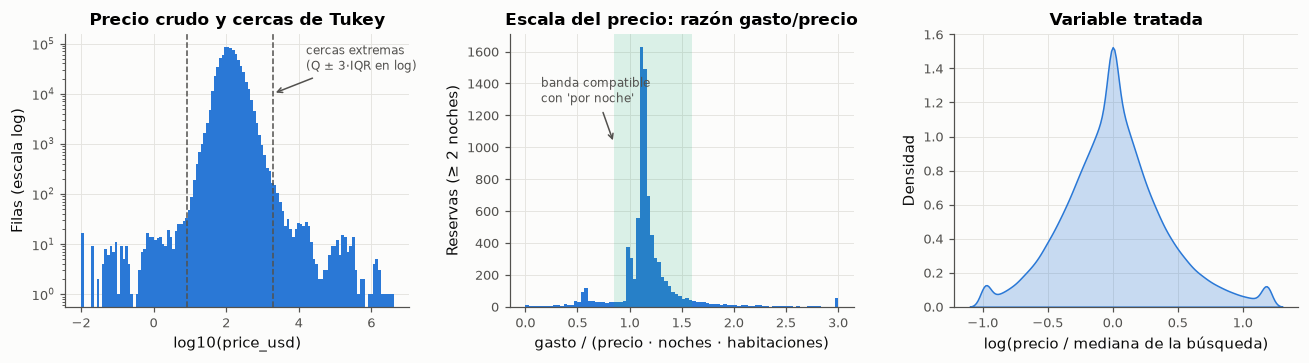

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
lp = np.log10(df["price_usd"].clip(lower=0.01))
ax[0].hist(lp, bins=120, color=gr.AZUL)
for c in (lo_abs, hi_abs):
    ax[0].axvline(np.log10(c), color=gr.TEXTO_2, ls="--", lw=1)
ax[0].set(
    yscale="log",
    xlabel="log10(price_usd)",
    ylabel="Filas (escala log)",
    title="Precio crudo y cercas de Tukey",
)
ax[0].annotate(
    "cercas extremas\n(Q ± 3·IQR en log)",
    xy=(np.log10(hi_abs), 1e4),
    xytext=(4.2, 3e4),
    fontsize=8,
    color=gr.TEXTO_2,
    arrowprops={"arrowstyle": "->", "color": gr.TEXTO_2},
)
razones = escala["razon_noche"].clip(0, 3)
ax[1].hist(razones, bins=90, color=gr.AZUL)
ax[1].axvspan(0.85, 1.6, color=gr.AQUA, alpha=0.15, lw=0)
ax[1].set(
    xlabel="gasto / (precio · noches · habitaciones)",
    ylabel="Reservas (≥ 2 noches)",
    title="Escala del precio: razón gasto/precio",
)
ax[1].annotate(
    "banda compatible\ncon 'por noche'",
    xy=(0.85, ax[1].get_ylim()[1] * 0.6),
    xytext=(0.15, ax[1].get_ylim()[1] * 0.75),
    fontsize=8,
    color=gr.TEXTO_2,
    arrowprops={"arrowstyle": "->", "color": gr.TEXTO_2},
)
sns.kdeplot(df["log_precio_rel"], ax=ax[2], color=gr.AZUL, fill=True, alpha=0.25, bw_adjust=1.5)
ax[2].set(
    xlabel="log(precio / mediana de la búsqueda)", ylabel="Densidad", title="Variable tratada"
)
fig.tight_layout()
gr.guardar(fig, "f1_precio_auditoria")
plt.show()

## 1.3 Mecanismo de pérdida de datos (MCAR, MAR, MNAR)

Sea $R_j = 1\{X_j \text{ falta}\}$. **MCAR**: $P(R_j \mid X_{\text{obs}}, X_{\text{mis}}) = P(R_j)$.
**MAR**: $P(R_j \mid X_{\text{obs}}, X_{\text{mis}}) = P(R_j \mid X_{\text{obs}})$. **MNAR**: depende del propio valor
faltante. MCAR implica que $R_j$ es independiente de **toda** variable observada, y eso es
contrastable: comparamos $R_j$ contra variables observadas (χ² de independencia para binarias,
Mann-Whitney para continuas, Bonferroni por familia). MAR vs. MNAR **no** es contrastable con
los datos: se argumenta por el mecanismo de generación.

Con cientos de miles de filas, casi cualquier dependencia da p ≈ 0. Por eso la lectura se apoya
en el tamaño de efecto: $|\text{SMD}| \ge 0{,}1$ o $V \ge 0{,}1$ es dependencia apreciable.

In [8]:
faltantes = (
    df[[c for c in df.columns if df[c].isna().any() and not c.startswith("comp")]]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .to_frame("pct_faltante")
)
faltantes

,pct_faltante
gross_bookings_usd,97.8230
visitor_hist_starrating,95.5182
visitor_hist_adr_usd,95.5143
srch_query_affinity_score,94.2999
orig_destination_distance,32.8042
prop_location_score2,22.0433
prop_log_historical_price,14.8256
prop_review_score,5.3376
prop_starrating,3.3731


In [9]:
CONTRA = [
    "booking_bool",
    "click_bool",
    "random_bool",
    "prop_starrating",
    "log_precio_rel",
    "prop_location_score1",
    "srch_booking_window",
]
mcar = pd.concat(
    [
        contraste_mcar(df, c, [v for v in CONTRA if v != c])
        for c in [
            "prop_location_score2",
            "orig_destination_distance",
            "prop_review_score",
            "visitor_hist_starrating",
            "srch_query_affinity_score",
        ]
    ]
)
resumen_mcar = mcar.pivot(index="variable_faltante", columns="contra", values="efecto").round(3)
resumen_mcar["max_|efecto|"] = resumen_mcar.abs().max(axis=1)
resumen_mcar

contra,booking_bool,click_bool,log_precio_rel,prop_location_score1,prop_starrating,random_bool,srch_booking_window,max_|efecto|
variable_faltante,,,,,,,,
orig_destination_distance,0.001,0.007,0.018,0.229,0.304,0.024,0.196,0.304
prop_location_score2,0.043,0.050,-0.030,-0.506,-0.257,0.019,-0.104,0.506
prop_review_score,0.020,0.016,-0.000,-0.238,-0.049,0.050,0.146,0.238
srch_query_affinity_score,0.014,0.000,0.014,0.132,0.180,0.082,0.112,0.180
visitor_hist_starrating,0.014,0.000,0.003,-0.012,-0.080,0.072,0.091,0.091


**Contraste multivariado: test de Little (1988).** Los contrastes anteriores miran una variable
por vez. Little contrasta MCAR en forma conjunta: con $\hat\mu$ y $\hat\Sigma$ de máxima
verosimilitud (algoritmo EM) y $J$ patrones de faltantes,

$$d^2 = \sum_{j=1}^{J} n_j\,(\bar y_j - \hat\mu_{o_j})^\top\,\hat\Sigma_{o_j}^{-1}\,(\bar y_j - \hat\mu_{o_j})
  \;\overset{H_0}{\sim}\; \chi^2_{\sum_j p_j - p},$$

donde $\bar y_j$ es la media de las $p_j$ variables observadas en el patrón $j$. Bajo
$H_0$ (MCAR) la media de cada patrón coincide con la global. Supone normalidad multivariada y,
como todo contraste con $n$ en cientos de miles, rechaza ante desvíos chicos: la decisión de
tratamiento sigue apoyándose en los tamaños de efecto de la tabla anterior.

In [10]:
from tpi.inferencia import _p as formato_p

COLS_LITTLE = [
    "prop_location_score2", "orig_destination_distance", "prop_review_score", "prop_starrating",
    "log_precio_rel", "prop_location_score1", "srch_booking_window",
]  # fmt: skip
little = little_mcar(df, COLS_LITTLE)
print(
    f"Test de Little: d² = {little['d2']:,.1f}, gl = {little['gl']}, {formato_p(little['p_valor'])} "
    f"| {little['patrones']} patrones de faltantes, n = {little['n']:,} (α = 0,05)"
)

Test de Little: d² = 75,952.2, gl = 73, p < 1e-300 (subdesborde de doble precisión) | 16 patrones de faltantes, n = 739,323 (α = 0,05)


**Lectura (efectos de la tabla; ver `contraste_mcar` para p-valores con Bonferroni):**

| Variable | % faltante | Dependencia observada | Mecanismo | Tratamiento |
|---|---|---|---|---|
| `prop_location_score2` | 22,0 | SMD = −0,506 con `location_score1`; −0,257 con estrellas; V = 0,043 con reserva | **MAR**: el faltante se explica por variables observadas del hotel (hoteles peor ubicados y de menos estrellas) | Mediana por país + indicador `_faltante` |
| `orig_destination_distance` | 32,8 | SMD = 0,304 con estrellas; 0,229 con `location_score1`; 0,196 con anticipación | **MAR**: falla de geolocalización asociada a perfiles observables | Mediana por par (país del usuario, país del hotel) + indicador |
| `prop_review_score` (incl. centinela 0) | 5,3 | SMD = −0,238 con `location_score1`; 0,146 con anticipación | **MNAR estructural**: el hotel no tiene reseñas; el valor no existe | Mediana por estrellas + indicador `sin_resenas`, que conserva la información |
| `visitor_hist_starrating` / `_adr_usd` | 95,5 | Todas las dependencias < 0,1 (máx. 0,091) | **MNAR estructural**: el usuario no tiene compras previas; no hay valor que imputar | **No se imputa**: se usa `usuario_recurrente` |
| `srch_query_affinity_score` | 94,3 | SMD = 0,180 con estrellas | **MNAR estructural**: el hotel no apareció en búsquedas previas | **No se imputa**: indicador `con_afinidad` |
| `gross_bookings_usd` | 97,8 | Existe solo si `booking_bool = 1` | Estructural por diseño | Solo se analiza entre reservas |

**MCAR se rechaza para las cinco variables contrastadas** (en todas hay al menos una dependencia
con p ajustado < 0,05), aunque para `visitor_hist_starrating` ninguna dependencia es apreciable.
El test de Little lo confirma en forma conjunta: $d^2$ es varios órdenes de magnitud mayor que sus
grados de libertad y se rechaza $H_0$ (MCAR).
La imputación por mediana dentro de grupos es coherente con MAR condicional al grupo, y el
indicador evita que el modelo trate el valor imputado como observado. Un faltante MNAR
estructural **no se imputa**: imputar un historial que no existe inventaría información.

In [11]:
df["usuario_recurrente"] = df["visitor_hist_starrating"].notna().astype("int8")
df["con_afinidad"] = df["srch_query_affinity_score"].notna().astype("int8")
# Medianas calculadas solo con Train y aplicadas a todas las filas (sin fuga)
for col, por in IMPUTACIONES:
    df = imputar_con_indicador(df, col, por=por, ajuste=df["train"])
print(
    "NaN restantes en variables de ajuste:",
    int(
        df[
            [
                "prop_location_score2",
                "prop_review_score",
                "prop_starrating",
                "prop_log_historical_price",
                "orig_destination_distance",
            ]
        ]
        .isna()
        .sum()
        .sum()
    ),
)

NaN restantes en variables de ajuste: 0


## 1.4 Variables de competidores ($Z_c$): ¿confusor o predictor?

**Definiciones (fuente primaria: pestaña Data de la competencia, transcriptas y verificadas por
Verónica el 12/11):**

* `compN_rate`: "+1 if Expedia has a lower price than competitor N for the hotel; 0 if the same;
  -1 if Expedia's price is higher than competitor N; NULL signifies there is no competitive data".
  **+1 = Expedia más barata.**
* `compN_inv`: "+1 if competitor N does not have availability in the hotel; 0 if both Expedia and
  competitor N have availability; NULL signifies there is no competitive data". En los datos
  aparece también **−1**, un valor no documentado (ver la tabla siguiente); no lo interpretamos.
* `compN_rate_percent_diff`: diferencia porcentual **absoluta** (sin signo; la dirección sale de
  `compN_rate`), con el precio de Expedia como denominador.

**Criterio de clasificación (fijado por Verónica antes del análisis):** $Z_c$ es **confusor** si el
ranking la usa ($Z_c \to T$) **y** además afecta la reserva ($Z_c \to Y$). Si solo afecta $Y$, es
**predictor**: puede incluirse por precisión, pero no integra el conjunto de ajuste mínimo de
Backdoor. Las dos flechas se contrastan por separado:

* **$Z_c \to T$:** el orden aleatorio (R = 1) corta los arcos que entran a T. Si el ranker usa
  $Z_c$, la asociación entre $Z_c$ y T con R = 0 debe **debilitarse** con R = 1. Se mide de tres
  formas: (a) $\rho$ de Spearman intra-búsqueda posición–$Z_c$; (b) diferencia pareada por
  búsqueda $D_s = \bar Z_{c,\text{top-5}} - \bar Z_{c,\text{resto}}$, en cada estrato; (c) logit de
  T sobre $Z_c$ y $Z_h$ con interacción $Z_c \times R$ (errores por clúster de búsqueda). (c) es
  el contraste formal: $H_0$: el efecto de $Z_c$ sobre T, condicional a $Z_h$, es igual con y sin
  el ranker.
* **$Z_c \to Y$:** con R = 1, logit de la reserva (y del clic, su mediador obligado) sobre $Z_c$,
  controlando por $\log(\text{posición})$ y por calidad y precio, con errores por clúster.

Resumen de los 8 competidores (entre 56 % y 98 % de faltantes): `comp_n_info` = competidores con
dato de precio; `comp_saldo` = (n con rate = +1 − n con rate = −1) / n con dato, en $[-1, 1]$:
**positivo = Expedia más barata que la mayoría de los competidores con dato**; `comp_diff_max` =
máxima diferencia porcentual absoluta válida (≤ 100 %).

In [12]:
inv = pd.concat([df[f"comp{i}_inv"].value_counts() for i in range(1, 9)], axis=1).sum(axis=1)
print(
    "compN_inv (8 competidores, valores no nulos):",
    inv.astype(int).to_dict(),
    f"| −1 no documentado: {100 * inv.get(-1.0, 0) / inv.sum():.2f} %",
)
diff_min = min(df[f"comp{i}_rate_percent_diff"].min() for i in range(1, 9))
print(f"Mínimo de compN_rate_percent_diff en los 8 competidores: {diff_min}")

compN_inv (8 competidores, valores no nulos): {0.0: 1235718, 1.0: 76325, -1.0: 16865} | −1 no documentado: 1.27 %
Mínimo de compN_rate_percent_diff en los 8 competidores: 2.0


In [13]:
df = agregar_competidores(df)
df["log_pos"] = np.log(df["position"])
ZH = "prop_starrating + prop_review_score + prop_location_score2 + log_precio_rel + promotion_flag"
filas_zc = []
for v in ["comp_n_info", "comp_saldo", "comp_diff_max"]:
    fila = {"variable": v}
    # (a) rho intra-búsqueda posición–Zc, por estrato
    for r in (0, 1):
        fila[f"rho_R{r}"] = resumir_rho(rho_intra_busqueda(df[df.random_bool == r], v), v).rho_medio
    # (b) diferencia pareada top-5 − resto, por estrato
    for r in (0, 1):
        d = df[df.random_bool == r].dropna(subset=[v])
        g = d.groupby(["srch_id", "top5"])[v].mean().unstack().dropna()
        c = contraste_pareado(g[1] - g[0])
        fila[f"D_R{r}"], fila[f"p_D_R{r}"] = c.diferencia, c.p_valor
    # (c) interacción Zc × R en el logit de T, condicional a Zh
    d = df.dropna(subset=[v])
    f = smf.logit(f"top5 ~ {v}*random_bool + ({ZH})*random_bool", d).fit(
        disp=0, cov_type="cluster", cov_kwds={"groups": d["srch_id"]}
    )
    fila["OR_T_R0"] = float(np.exp(f.params[v]))
    fila["razon_OR_T_R1/R0"] = float(np.exp(f.params[f"{v}:random_bool"]))
    fila["p_interaccion"] = float(f.pvalues[f"{v}:random_bool"])
    # Zc -> Y (y -> M) con R = 1
    d1 = df[df.random_bool == 1].dropna(subset=[v])
    for y in ["click_bool", "booking_bool"]:
        f = smf.logit(
            f"{y} ~ {v} + log_pos + prop_starrating + prop_review_score + log_precio_rel", d1
        ).fit(disp=0, cov_type="cluster", cov_kwds={"groups": d1["srch_id"]})
        fila[f"OR_{y}"] = float(np.exp(f.params[v]))
        fila[f"p_{y}"] = float(f.pvalues[v])
    filas_zc.append(fila)
tabla_zc = pd.DataFrame(filas_zc).set_index("variable")
tabla_zc.T

variable,comp_n_info,comp_saldo,comp_diff_max
rho_R0,-9.8626e-02,-3.7199e-02,-1.5721e-02
rho_R1,-3.3221e-02,7.3544e-03,-1.1588e-03
D_R0,1.0004e-01,4.8751e-02,1.2296e+00
p_D_R0,1.8832e-97,1.0561e-59,3.4244e-19
D_R1,2.6710e-02,-5.6890e-03,2.8623e-01
p_D_R1,1.9384e-09,7.2598e-02,6.2761e-02
OR_T_R0,9.4788e-01,1.1728e+00,1.0025e+00
razon_OR_T_R1/R0,1.0193e+00,8.4229e-01,9.9859e-01
p_interaccion,2.8677e-05,2.6707e-18,5.3951e-02
OR_click_bool,9.9487e-01,1.1467e+00,1.0002e+00


**Clasificación** (criterio de Verónica; aplicación de Claude Code; **pendiente de revisión por
Verónica**; incluye el contraste explícito de $Z_c \to T$ que ella pidió el 12/11):

| Variable | $Z_c \to T$ (ranker) | $Z_c \to Y$ (R = 1) | Clase |
|---|---|---|---|
| `comp_saldo` | Con R = 0 el top-5 tiene más saldo (D = +0,049, p = 1,1·10⁻⁵⁹); con R = 1 desaparece (D = −0,006, p = 0,073). Interacción: razón de OR 0,842, p = 2,7·10⁻¹⁸ | Reserva OR = 1,137 (p = 0,041); clic OR = 1,147 (p = 2,1·10⁻⁸) | **Confusor** |
| `comp_n_info` | D = +0,100 con R = 0 vs. +0,027 con R = 1 (cae 73 %). Condicional a $Z_h$, OR(T) = 0,948 con R = 0; interacción: razón 1,019, p = 2,8·10⁻⁵ | Reserva OR = 1,118 (p = 2,9·10⁻¹⁷); clic sin efecto (p = 0,20) | **Confusor (débil en T)** |
| `comp_diff_max` | Interacción p = 0,054: no se rechaza H0 | Reserva p = 0,53; clic p = 0,79 | **Ni confusor ni predictor**: se excluye |

**Lectura con el signo correcto.** `comp_saldo` > 0 significa que Expedia es más barata que la
mayoría de los competidores con dato. Bajo el orden del algoritmo, los hoteles con precio
competitivo suben al top-5 (OR(T) = 1,173 por unidad de saldo, condicional a calidad y precio
relativo). Con la posición aleatoria, ese mismo precio competitivo aumenta el clic (+14,7 % en las
chances) y la reserva (+13,7 %). Como el ranker usa una variable que también causa la reserva por
su cuenta, omitirla sesgaría el efecto del top-5 hacia arriba.

**`comp_n_info`** pasa el criterio, pero su arco a T es chico (≈ 2 % en las chances, condicional a
$Z_h$), y la asociación residual con R = 1 (D = +0,027, p = 1,9·10⁻⁹) es del mismo tipo que la
aleatorización imperfecta de `prop_starrating` (limitación declarada, Entrada 4). Incluirla en el
ajuste es seguro: es pre-tratamiento, no es mediador ni colisionador.

**DAG actualizado** (`src/tpi/dag.py`): se agregan $Z_c \to T$ y $Z_c \to M$, y $Z_c$ pasa al conjunto de
confusores. `tests/test_dag.py::test_sin_zc_el_ajuste_no_alcanza_aunque_se_observara_u` demuestra que
omitir $Z_c$ deja abierto $T \leftarrow Z_c \to Y$.

## 1.5 Análisis exploratorio univariado y bivariado

La figura central del problema: la tasa de clic por posición con el orden del algoritmo
(R = 0) y con el orden aleatorio (R = 1). Bajo R = 1 la caída con la posición es **sesgo de
posición** puro (el arco $T \to M$). Bajo R = 0 se le suma la calidad de los hoteles que el
algoritmo pone arriba (confusión). La distancia entre ambas curvas es la primera evidencia
visual del sesgo que la Fase 4 tiene que corregir.

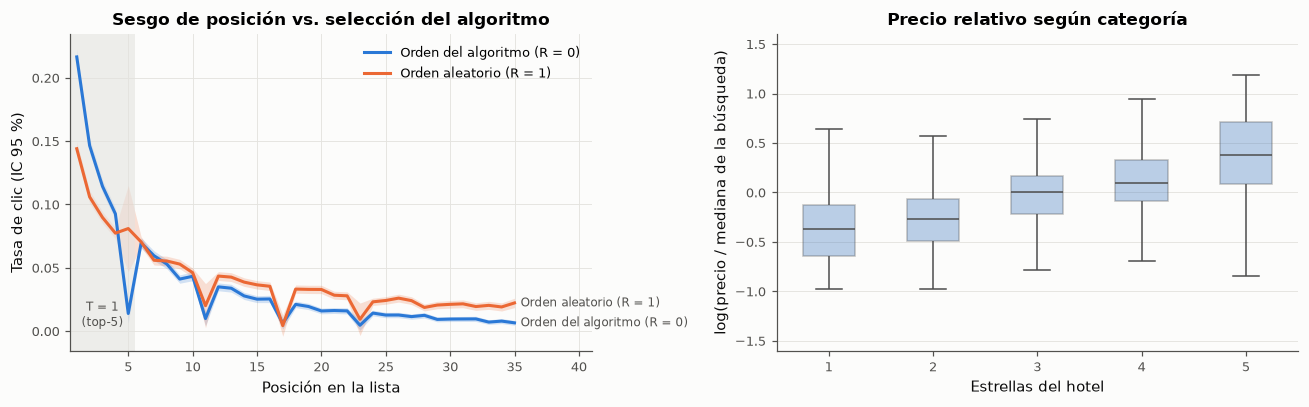

In [14]:
ctr = (
    df[df.position <= 35]
    .groupby(["random_bool", "position"])["click_bool"]
    .agg(["mean", "count"])
    .reset_index()
)
ctr["ee"] = np.sqrt(ctr["mean"] * (1 - ctr["mean"]) / ctr["count"])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for r, color, nombre in [
    (0, gr.AZUL, "Orden del algoritmo (R = 0)"),
    (1, gr.NARANJA, "Orden aleatorio (R = 1)"),
]:
    d = ctr[ctr.random_bool == r]
    ax[0].plot(d.position, d["mean"], color=color, label=nombre)
    ax[0].fill_between(
        d.position, d["mean"] - 1.96 * d.ee, d["mean"] + 1.96 * d.ee, color=color, alpha=0.2, lw=0
    )
    ax[0].annotate(
        nombre,
        xy=(d.position.iloc[-1], d["mean"].iloc[-1]),
        xytext=(4, 0),
        textcoords="offset points",
        fontsize=8,
        color=gr.TEXTO_2,
        va="center",
    )
ax[0].axvspan(0.5, 5.5, color=gr.GRILLA, alpha=0.6, lw=0)
ax[0].text(3, 0.004, "T = 1\n(top-5)", ha="center", fontsize=8, color=gr.TEXTO_2)
ax[0].set(
    xlabel="Posición en la lista",
    ylabel="Tasa de clic (IC 95 %)",
    title="Sesgo de posición vs. selección del algoritmo",
    xlim=(0.5, 41),
)
ax[0].legend(loc="upper right")
grupos_est = df.dropna(subset=["prop_starrating"]).assign(
    estrellas=lambda d: d.prop_starrating.astype(int).astype(str)
)
sns.boxplot(
    data=grupos_est,
    x="estrellas",
    y="log_precio_rel",
    order=["1", "2", "3", "4", "5"],
    color=gr.AZUL,
    ax=ax[1],
    fliersize=0,
    width=0.5,
    boxprops={"alpha": 0.35},
)
ax[1].set(
    xlabel="Estrellas del hotel",
    ylabel="log(precio / mediana de la búsqueda)",
    title="Precio relativo según categoría",
    ylim=(-1.6, 1.6),
)
fig.tight_layout()
gr.guardar(fig, "f1_ctr_posicion")
plt.show()

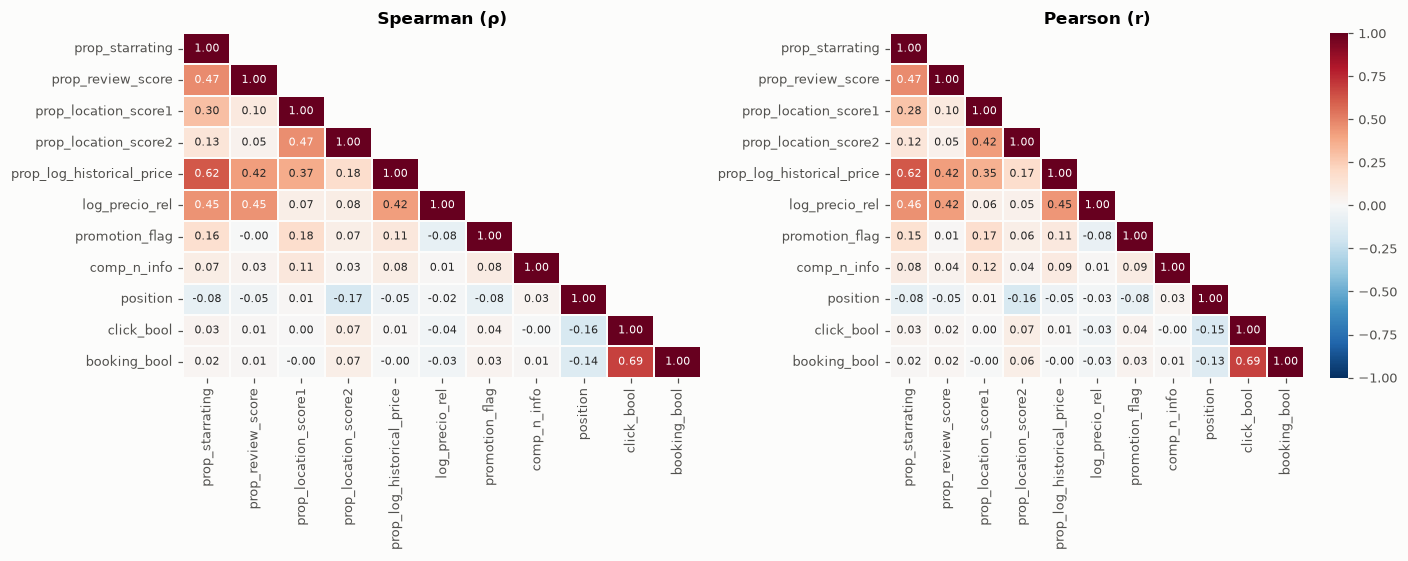

Mayor |ρ_Spearman − r_Pearson|: {('prop_location_score2', 'prop_location_score1'): 0.043, ('prop_location_score1', 'prop_location_score2'): 0.043, ('prop_review_score', 'log_precio_rel'): 0.03}


,ρ con position,ρ con booking_bool
prop_starrating,-0.082,0.017
prop_review_score,-0.045,0.013
prop_location_score1,0.013,-0.004
prop_location_score2,-0.172,0.065
prop_log_historical_price,-0.054,-0.000
log_precio_rel,-0.023,-0.032
promotion_flag,-0.082,0.032
comp_n_info,0.029,0.013
click_bool,-0.160,0.686


In [15]:
NUM = [
    "prop_starrating",
    "prop_review_score",
    "prop_location_score1",
    "prop_location_score2",
    "prop_log_historical_price",
    "log_precio_rel",
    "promotion_flag",
    "comp_n_info",
    "position",
    "click_bool",
    "booking_bool",
]
corr_s = df[NUM].corr(method="spearman")
corr_p = df[NUM].corr(method="pearson")
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
mascara = np.triu(np.ones_like(corr_s, dtype=bool), k=1)
for a, c, t in [(ax[0], corr_s, "Spearman (ρ)"), (ax[1], corr_p, "Pearson (r)")]:
    sns.heatmap(
        c,
        mask=mascara,
        cmap=gr.DIVERGENTE,
        vmin=-1,
        vmax=1,
        center=0,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 7},
        linewidths=1,
        linecolor=gr.SUPERFICIE,
        cbar=a is ax[1],
        ax=a,
    )
    a.set_title(t)
    a.grid(False)
fig.tight_layout()
gr.guardar(fig, "f1_correlaciones")
plt.show()
print(
    "Mayor |ρ_Spearman − r_Pearson|:",
    (corr_s - corr_p).abs().stack().sort_values(ascending=False).head(3).round(3).to_dict(),
)
pd.DataFrame(
    {"ρ con position": corr_s["position"], "ρ con booking_bool": corr_s["booking_bool"]}
).drop(["position", "booking_bool"]).round(3)

**Lectura de la exploración:**

* **Sesgo de posición.** Con orden aleatorio, la tasa de clic cae con la posición (el arco
  $T \to M$ existe). Con el orden del algoritmo, la curva arranca más alta en el top-5 y cae más
  abajo al final de la lista: el algoritmo concentra arriba a los hoteles que se clickean igual.
  La brecha entre curvas es la confusión que la Fase 4 debe eliminar. Los "pozos" en 5, 11, 17 y
  23 son los slots estructurales (1.1).
* **Calidad y precio.** El precio relativo sube con las estrellas: calidad y precio están
  entrelazados, lo que anticipa multicolinealidad en la Fase 2.
* **Correlaciones.** Spearman y Pearson difieren a lo sumo en 0,043 (entre los dos scores de
  ubicación), así que las relaciones son aproximadamente monótonas y lineales en estas escalas. La
  variable más asociada a la posición es `prop_location_score2` (ρ = −0,172: mejor ubicación, más
  arriba), seguida por el clic (−0,160), las estrellas (−0,082) y la promoción (−0,082). Con la
  reserva, la asociación más fuerte es el clic (ρ = 0,686, el mediador), seguida por la posición
  (ρ = −0,14 en la matriz). Las demás son débiles (`location_score2`: 0,065).
* **Colinealidad anticipada.** `prop_log_historical_price` correlaciona 0,62 con las estrellas, y
  el precio relativo, 0,45 con estrellas y con reseñas: bloque calidad–precio a auditar con VIF en
  la Fase 2.
* Son correlaciones a nivel fila, sin separar R = 0 de R = 1: descriptivas, no causales.

## 1.6 Contraste 1 — Sesgo de posición en el clic (pareado, R = 1)

**Pregunta de negocio:** si el orden es aleatorio, ¿los hoteles del top-5 reciben más clics que
el resto *de la misma lista*? Es el primer eslabón del DAG ($T \to M$): si no existiera, el slot
no tendría valor causal.

Para cada búsqueda $s$ con R = 1: $D_s = \overline{\text{CTR}}_{s,\text{top-5}} - \overline{\text{CTR}}_{s,\text{resto}}$.

$$H_0: \mathbb{E}[D_s] = 0 \qquad H_1: \mathbb{E}[D_s] \neq 0$$

**Estadístico:** t de Student para una muestra sobre las diferencias pareadas,
$t = \bar D / (s_D/\sqrt{n})$ con $n-1$ gl. Es pareado porque las dos tasas comparten búsqueda
(usuario, destino, fecha), lo que elimina todo confusor a nivel búsqueda. La validez descansa en
el TCL ($n$ en miles); como resguardo no paramétrico, Wilcoxon de rangos con signo. Tamaño de
efecto: $d_z = \bar D / s_D$.

**Selección:** el dataset solo trae búsquedas con al menos un clic (BITÁCORA, Entrada 4). Eso
infla ambas tasas, pero dentro de la búsqueda el cociente se conserva aproximadamente, así que
también reportamos el cociente de tasas medias.

In [16]:
r1_df = df[df.random_bool == 1]
por_busq = (
    r1_df.assign(T=(r1_df.position <= 5)).groupby(["srch_id", "T"])["click_bool"].mean().unstack()
)
por_busq = por_busq.dropna()
D = por_busq[True] - por_busq[False]
c1 = contraste_pareado(D, nombre="Contraste 1 (CTR top-5 − resto, R = 1)")
print(c1.texto())
print(f"Wilcoxon: W = {c1.extra['wilcoxon_W']:.4g}, p = {c1.extra['wilcoxon_p']:.3g}")
print(
    f"CTR medio top-5 = {por_busq[True].mean():.4f} | resto = {por_busq[False].mean():.4f} | cociente = {por_busq[True].mean() / por_busq[False].mean():.3f}"
)
print(
    f"Efecto mínimo detectable (d_z, 1−β = 0,80): {efecto_minimo_detectable(len(D)):.4f} | potencia para el d_z observado: {potencia(c1.efecto, len(D)):.4f}"
)
print(f"Asimetría de D: {stats.skew(D):.3f} | curtosis en exceso: {stats.kurtosis(D):.3f}")

Contraste 1 (CTR top-5 − resto, R = 1): t(14982) = 37.47, p = 7.74e-294, IC 95 % [0.05313; 0.05899], d_z = 0.306 (α = 0.05) → se rechaza H0
Wilcoxon: W = 4.326e+07, p = 7.7e-131
CTR medio top-5 = 0.1043 | resto = 0.0483 | cociente = 2.161
Efecto mínimo detectable (d_z, 1−β = 0,80): 0.0229 | potencia para el d_z observado: 1.0000
Asimetría de D: -0.540 | curtosis en exceso: 3.608


**Decisión.** Se rechaza $H_0$: t(14982) = 37,47, p = 7,74·10⁻²⁹⁴. Con orden aleatorio, los hoteles
del top-5 tienen una tasa de clic 5,6 puntos porcentuales mayor que el resto de su propia lista
(IC 95 % [5,31; 5,90] p.p.), y $d_z = 0{,}306$ (efecto pequeño a mediano en la escala de Cohen). El
Wilcoxon de resguardo coincide (p = 7,7·10⁻¹³¹), así que la conclusión no depende de la
normalidad: $D_s$ tiene asimetría −0,540 y curtosis en exceso 3,608, que el TCL absorbe con
n = 14.983.

**Escala relativa.** La tasa de clic media del top-5 es 0,1043 contra 0,0483 del resto: un
cociente de **2,16**. Por la selección del dataset (solo búsquedas con clic) las tasas absolutas
están infladas, pero el cociente dentro de la búsqueda es la escala que se conserva (Entrada 4).

**Potencia.** Con n = 14.983 el efecto mínimo detectable es $d_z$ = 0,023: la muestra detectaría
efectos 13 veces menores que el observado.

**Negocio.** Sin mirar la calidad del hotel, estar en el top-5 duplica la probabilidad de clic.
Ese es el valor *bruto* del slot sobre la atención; falta saber cuánto se traduce en reservas
(Fase 4).

## 1.7 Contraste 2 — Gasto por reserva: usuarios recurrentes vs. nuevos

**Pregunta de negocio:** ¿los usuarios con historial de compras en Expedia (recurrentes) gastan
más por reserva que los nuevos? Es la "autoselección de usuarios recurrentes" del enunciado: si
gastan distinto, el historial ($Z_u$) es candidato a confusor de cualquier efecto sobre el gasto.

**Unidad:** la reserva (a lo sumo una por búsqueda, así que son independientes). Excluimos
reservas con gasto nulo y con precio outlier. **Variable:** $\log(\text{gasto})$, porque el
gasto tiene cola pesada a derecha; la diferencia de medias en log se lee como **cociente de
medias geométricas** $e^{\bar y_1 - \bar y_2}$.

$$H_0: \mu_{\log,\text{recurrentes}} = \mu_{\log,\text{nuevos}} \qquad H_1: \mu_{\log,\text{recurrentes}} \neq \mu_{\log,\text{nuevos}}$$

**Estadístico:** t de Welch, porque los grupos tienen tamaños muy distintos y no hay razón para
suponer varianzas iguales (Levene abajo). Gl de Welch-Satterthwaite. Resguardo: U de Mann-Whitney
($H_0$: $P(X_1 > X_2) = 1/2$). Tamaños de efecto: g de Hedges y r biserial de rangos.
Contraste **descriptivo**, no causal: los recurrentes difieren en destino y duración.

In [17]:
res = df[(df.booking_bool == 1) & (df.gross_bookings_usd > 0) & (df.precio_outlier == 0)].copy()
res["log_gasto"] = np.log(res["gross_bookings_usd"])
rec, nue = (
    res.loc[res.usuario_recurrente == 1, "log_gasto"],
    res.loc[res.usuario_recurrente == 0, "log_gasto"],
)
lev = stats.levene(rec, nue, center="median")
print(f"Levene (Brown-Forsythe): F(1; {len(res) - 2}) = {lev.statistic:.4g}, p = {lev.pvalue:.3g}")
c2 = welch_dos_grupos(rec, nue, nombre="Contraste 2 (log gasto, recurrentes − nuevos)")
c2b = mann_whitney(np.exp(rec), np.exp(nue), nombre="Contraste 2b (gasto, Mann-Whitney)")
print(c2.texto())
print(c2b.texto())
print(
    f"Cociente de medias geométricas = {np.exp(c2.diferencia):.4f}, IC 95 % [{np.exp(c2.ic95[0]):.4f}; {np.exp(c2.ic95[1]):.4f}]"
)
print(f"Hodges-Lehmann (diferencia de gasto en USD): {c2b.diferencia:.2f}")
print(
    f"n recurrentes = {len(rec)}, n nuevos = {len(nue)} | efecto mínimo detectable (g): {efecto_minimo_detectable(len(rec), len(nue)):.4f}"
)
print(f"Asimetría log gasto: recurrentes {stats.skew(rec):.3f}, nuevos {stats.skew(nue):.3f}")
# Solo agregados: percentiles 1-99 (sin mínimo ni máximo, que describen un único registro)
res.groupby("usuario_recurrente")["gross_bookings_usd"].quantile(
    [0.01, 0.25, 0.5, 0.75, 0.99]
).unstack().rename(columns=lambda q: f"p{round(100 * q)}")

Levene (Brown-Forsythe): F(1; 16062) = 3.19, p = 0.0741
Contraste 2 (log gasto, recurrentes − nuevos): t(1158.6) = 1.303, p = 0.193, IC 95 % [-0.0194; 0.09617], g de Hedges = 0.043 (α = 0.05) → no se rechaza H0
Contraste 2b (gasto, Mann-Whitney): U = 7.949e+06, p = 0.0931, r biserial de rangos = 0.031 (α = 0.05) → no se rechaza H0
Cociente de medias geométricas = 1.0391, IC 95 % [0.9808; 1.1009]
Hodges-Lehmann (diferencia de gasto en USD): 8.59
n recurrentes = 1025, n nuevos = 15039 | efecto mínimo detectable (g): 0.0904
Asimetría log gasto: recurrentes 0.076, nuevos 0.507


,p1,p25,p50,p75,p99
usuario_recurrente,,,,,
0,49.2866,125.205,222.48,431.545,2558.1196
1,45.1808,126.340,236.83,460.200,2066.7705


**Decisión.** No se rechaza $H_0$: t de Welch(1158,6) = 1,303, p = 0,193; IC 95 % para la diferencia
de medias en log [−0,019; 0,096]. Equivale a un cociente de medias geométricas de 1,039 (IC 95 %
[0,981; 1,101]): los recurrentes gastarían entre 1,9 % menos y 10,1 % más por reserva. El
Mann-Whitney de resguardo coincide (p = 0,093; r biserial = 0,031).

**Supuestos.** Levene no rechaza la igualdad de varianzas (F(1; 16062) = 3,19, p = 0,074), pero
Welch se mantiene porque los grupos están muy desbalanceados (1.025 vs. 15.039), y en ese caso un
error de tipo II de Levene sería costoso. La asimetría del log gasto (0,076 y 0,507) está dentro
de $[-1, 1]$.

**Potencia.** No rechazar no prueba igualdad. Con estos tamaños, el efecto mínimo detectable con
potencia 0,80 es g = 0,090; el observado (g = 0,043) es la mitad. **Diferencias de gasto menores
que ≈ 0,09 desvíos no son detectables con esta muestra**: el contraste es compatible tanto con
"no hay diferencia" como con una diferencia chica.

**Negocio.** No hay evidencia de que el historial del usuario cambie el ticket medio. La
"autoselección de recurrentes" del enunciado, si existe, operaría sobre la conversión y no sobre
el gasto por reserva.

## 1.8 ANOVA de un factor — Precio por noche del hotel reservado según categoría

**Pregunta:** ¿el precio esperado por noche del hotel reservado varía entre categorías de
estrellas? Es la base del supuesto de que la calidad ($Z_h$) y el precio están entrelazados en
$Z$ (relevante para la multicolinealidad de la Fase 2).

**Modelo:** $Y_{gj} = \mu + \alpha_g + \varepsilon_{gj}$, con $\sum \alpha_g = 0$, $Y$ = log del
precio por noche de la reserva $j$ en la categoría $g \in \{1\text{–}2, 3, 4, 5\}$ (1 y 2
estrellas se unen por el bajo $n$ de 1 estrella).

$$H_0: \mu_{1\text{–}2} = \mu_3 = \mu_4 = \mu_5 \qquad H_1: \exists\, g \ne g' : \mu_g \ne \mu_{g'}$$

**Supuestos y resguardos:**
* *Normalidad:* con miles de observaciones, Shapiro-Wilk rechaza ante desvíos microscópicos
  irrelevantes para el TCL. La evaluamos con asimetría (criterio $|\text{asimetría}| \le 1$),
  curtosis y gráficos Q-Q.
* *Homocedasticidad:* Levene centrado en la mediana (Brown-Forsythe). Si se rechaza, el F
  clásico deja de ser válido y usamos **ANOVA de Welch** (no asume varianzas iguales) y
  **Kruskal-Wallis** (no paramétrico).
* *Post-hoc:* Games-Howell (no asume varianzas iguales), comparado con Tukey HSD (que sí las
  asume) y con Welch por pares + Bonferroni (conservador).

In [18]:
anova_df = res.dropna(subset=["prop_starrating"]).copy()
anova_df = anova_df[anova_df.precio_outlier == 0]
anova_df["categoria"] = pd.cut(
    anova_df.prop_starrating, [0, 2, 3, 4, 5], labels=["1-2", "3", "4", "5"]
)
anova_df["log_precio_noche"] = np.log(anova_df.price_usd)
desc = describir_grupos(anova_df, "log_precio_noche", "categoria")
sw = {
    g: stats.shapiro(d.sample(min(len(d), 5000), random_state=SEED)).pvalue
    for g, d in anova_df.groupby("categoria", observed=True)["log_precio_noche"]
}
desc["shapiro_p (n≤5000)"] = pd.Series(sw)
desc

,n,media,desvio,asimetria,curtosis_exceso,shapiro_p (n≤5000)
categoria,,,,,,
1-2,2301,4.3216,0.3960,0.2050,1.6134,7.5852e-17
3,6662,4.6435,0.4198,-0.2133,1.4907,2.3968e-22
4,5849,4.9337,0.4709,-0.0250,0.7798,3.0058e-10
5,1252,5.2964,0.4994,0.3139,0.4907,3.3613e-05


In [19]:
an = anova_un_factor(anova_df, "log_precio_noche", "categoria")
for k in ["levene", "clasico", "welch", "kruskal"]:
    print(an[k].texto())
print(f"ω² (ANOVA clásico) = {an['clasico'].extra['omega2']:.4f}")
ph = posthoc(anova_df, "log_precio_noche", "categoria")
ph["cociente_precios"] = np.exp(ph["diferencia"])
ph

Levene (Brown-Forsythe): F(3; 16060) = 56.57, p = 2.27e-36, razón de varianzas máx/mín = 1.590 (α = 0.05) → se rechaza H0
ANOVA clásico: F(3; 16060) = 1820, p < 1e-300 (subdesborde de doble precisión), η² = 0.254 (α = 0.05) → se rechaza H0
ANOVA de Welch: F(3; 4432.0) = 1807, p < 1e-300 (subdesborde de doble precisión), η² = 0.254 (α = 0.05) → se rechaza H0
Kruskal-Wallis: H(3) = 4150, p < 1e-300 (subdesborde de doble precisión), ε² = 0.258 (α = 0.05) → se rechaza H0
ω² (ANOVA clásico) = 0.2536


,A,B,diferencia,ee,p_games_howell,p_bonferroni,p_tukey,rechaza_games_howell,rechaza_bonferroni,rechaza_tukey,cociente_precios
0,1-2,3,-0.3218,0.0097,0.0000e+00,7.2874e-213,0.0,True,True,True,0.7248
1,1-2,4,-0.6121,0.0103,0.0000e+00,0.0000e+00,0.0,True,True,True,0.5422
2,1-2,5,-0.9748,0.0164,0.0000e+00,0.0000e+00,0.0,True,True,True,0.3773
3,3,4,-0.2902,0.0080,3.9457e-13,4.0669e-271,0.0,True,True,True,0.7481
4,3,5,-0.6529,0.0150,3.7637e-13,2.0205e-272,0.0,True,True,True,0.5205
5,4,5,-0.3627,0.0154,2.1061e-13,4.4095e-106,0.0,True,True,True,0.6958


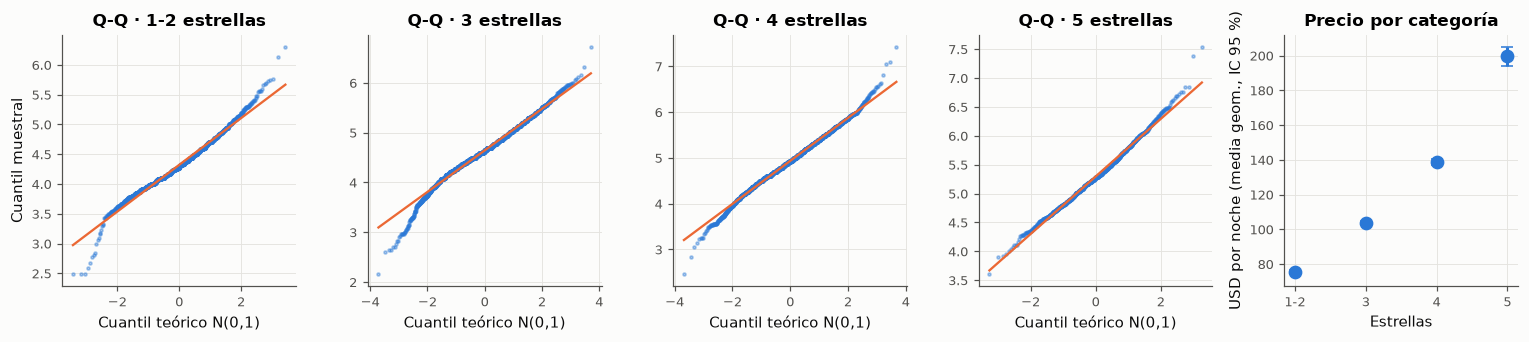

In [20]:
fig, ax = plt.subplots(1, 5, figsize=(14, 3.2))
for a, (g, d) in zip(
    ax[:4], anova_df.groupby("categoria", observed=True)["log_precio_noche"], strict=True
):
    stats.probplot(d, dist="norm", plot=a)
    a.get_lines()[0].set(markerfacecolor=gr.AZUL, markeredgecolor=gr.AZUL, markersize=2, alpha=0.4)
    a.get_lines()[1].set(color=gr.NARANJA, lw=1.5)
    a.set(
        title=f"Q-Q · {g} estrellas",
        xlabel="Cuantil teórico N(0,1)",
        ylabel="Cuantil muestral" if g == "1-2" else "",
    )
medias = anova_df.groupby("categoria", observed=True)["log_precio_noche"].agg(["mean", "sem"])
ax[4].errorbar(
    range(len(medias)),
    np.exp(medias["mean"]),
    yerr=[
        np.exp(medias["mean"]) - np.exp(medias["mean"] - 1.96 * medias["sem"]),
        np.exp(medias["mean"] + 1.96 * medias["sem"]) - np.exp(medias["mean"]),
    ],
    fmt="o",
    color=gr.AZUL,
    capsize=4,
    ms=8,
)
ax[4].set(
    xticks=range(len(medias)),
    xticklabels=medias.index,
    xlabel="Estrellas",
    ylabel="USD por noche (media geom., IC 95 %)",
    title="Precio por categoría",
)
fig.tight_layout()
gr.guardar(fig, "f1_anova")
plt.show()

**Supuestos.**
* *Normalidad:* Shapiro-Wilk rechaza en los cuatro grupos (p entre 2,4·10⁻²² y 3,4·10⁻⁵ con n ≤ 5.000),
  como anticipa el enunciado para muestras grandes. Lo relevante: asimetrías entre −0,213 y 0,314
  (dentro de $[-1, 1]$) y curtosis en exceso entre 0,49 y 1,61. Los Q-Q muestran colas algo más
  pesadas que la normal, sobre todo la izquierda en 1-2 y 3 estrellas. Con n ≥ 1.252 por grupo, el
  TCL garantiza la validez aproximada de las medias.
* *Homocedasticidad:* **Levene rechaza** (F(3; 16060) = 56,57, p = 2,27·10⁻³⁶; razón de varianzas
  máx/mín = 1,59). El F clásico pierde validez, así que la inferencia principal es el **ANOVA de
  Welch**.

**Decisión.** Se rechaza $H_0$ con las tres pruebas: Welch F(3; 4432,0) = 1807; F clásico(3; 16060)
= 1820; Kruskal-Wallis H(3) = 4150; en las tres, p < 10⁻³⁰⁰ (subdesborde de doble precisión). El
tamaño de efecto es grande: η² = 0,254, ω² = 0,254 y ε² = 0,258. La categoría explica ≈ 25 % de
la varianza del log precio.

**Post-hoc.** Las seis comparaciones son significativas con los tres criterios (Games-Howell,
Tukey HSD y Bonferroni), así que la conclusión no depende del supuesto de homocedasticidad. En
cocientes de medias geométricas, un hotel de 5 estrellas cuesta 2,65 veces uno de 1-2
(1/0,3773), 1,92 veces uno de 3 y 1,44 veces uno de 4. Los p-valores de Games-Howell que aparecen
como ≈ 10⁻¹³ o 0 son el límite numérico de la distribución de rango estudentizado en pingouin, no
valores exactos.

**Por qué Welch y no Kruskal-Wallis como principal:** la pregunta es sobre el **valor esperado**
del log precio (medias), y Welch responde exactamente eso sin suponer varianzas iguales.
Kruskal-Wallis contrasta otra hipótesis (dominancia estocástica) y queda como resguardo.

## 1.9 Síntesis de la Fase 1

| Hallazgo | Evidencia | Consecuencia para las fases siguientes |
|---|---|---|
| Hay sesgo de posición puro sobre el clic | Contraste 1: CTR ×2,16 en el top-5 con orden aleatorio | El arco $T \to M$ existe; el efecto sobre la reserva se estima en la Fase 4 |
| El algoritmo selecciona hoteles que se clickean igual | Curvas de CTR R = 0 vs. R = 1 | Confusión a corregir (Backdoor) |
| La categoría explica ≈ 25 % del log precio | ANOVA de Welch, η² = 0,254 | Multicolinealidad calidad–precio (VIF, Fase 2) |
| El gasto por reserva no difiere entre recurrentes y nuevos (no detectable bajo g ≈ 0,09) | Contraste 2 | $Z_u$ entra como confusor de la conversión, no del gasto |
| $Z_c$ = {`comp_n_info`, `comp_saldo`} son confusores | Tabla 1.4 | Entran al ajuste en la Fase 4 |
| Slots estructurales 5/11/17/23 fuera del dataset | Presencia por posición | T = top-5 en pantalla ≈ 4 hoteles del dataset |
| Faltantes MAR y MNAR estructurales, ninguno MCAR | Tabla 1.3 | Imputación por grupo + indicadores; los MNAR no se imputan |

---
# Fase 2 — Diagnóstico de Gauss-Markov, puntos influyentes y reducción PCA

## 2.0 Partición Train/Test (única para las Fases 2 a 4)

80/20 **agrupada por búsqueda** (ninguna lista queda partida entre Train y Test) y
**estratificada por `random_bool`**, con `SEED = 42` (`tpi.particion`). Toda la Fase 2 se estima
**solo con Train**; Test queda intacto para el torneo de la Fase 3. La partición es aleatoria y no
cronológica porque el período es corto (8 meses) y el objetivo es generalizar a búsquedas nuevas
del mismo período (ver Durbin-Watson en 2.2).

In [21]:
import statsmodels.api as sm
from sklearn.linear_model import HuberRegressor, RANSACRegressor

from tpi.particion import es_train
from tpi.regresion import ajustar_pca, diagnostico_gauss_markov, influencia, resumen_pca, tabla_vif

assert df["train"].equals(es_train(df))  # fijada en 1.2, antes de cualquier transformación
print(
    df.groupby("train").agg(
        busquedas=("srch_id", "nunique"), filas=("srch_id", "size"), pct_R1=("random_bool", "mean")
    )
)

       busquedas   filas  pct_R1
train                           
False       6000  148509  0.4938
True       24000  590814  0.4905


## 2.1 Modelo lineal de referencia (MCO): precio hedónico del hotel reservado

**Unidad:** la reserva (una por búsqueda, así que las observaciones son independientes), en Train
y sin precios outlier. **Respuesta:** $Y = \log(\text{precio por noche})$. Las pendientes se leen
como semielasticidades: $100\,(e^{\beta_j}-1)$ % de cambio en el precio por unidad de $X_j$.

$$\log(\text{precio})_i = \beta_0 + \sum_{j=1}^{p} \beta_j X_{ij} + \varepsilon_i, \qquad
  \mathbb{E}[\varepsilon \mid X] = 0,\; \operatorname{Var}(\varepsilon \mid X) = \sigma^2 I$$

Bajo Gauss-Markov (linealidad, exogeneidad, homocedasticidad, no autocorrelación, rango completo)
el estimador MCO $\hat\beta = (X^\top X)^{-1}X^\top y$ es el de mínima varianza entre los lineales
insesgados. La normalidad de $\varepsilon$ solo hace falta para que las pruebas t y F sean exactas
en muestras chicas; con $n$ en miles valen asintóticamente.

**Contrastes:** $F$ global, $H_0: \beta_1 = \dots = \beta_p = 0$; $t$ individual,
$H_0: \beta_j = 0$.

**Experimento previo (fallido, Entrada 3).** Primero ajustamos la especificación ingenua: precio
crudo en USD, sin log y sin quitar outliers.

In [22]:
X_MCO = [
    "prop_starrating", "prop_review_score", "sin_resenas", "prop_location_score1",
    "prop_location_score2", "prop_log_historical_price", "sin_historial_precio", "prop_brand_bool",
    "promotion_flag", "srch_length_of_stay", "srch_booking_window", "srch_adults_count",
    "srch_children_count", "srch_room_count", "srch_saturday_night_bool", "usuario_recurrente",
    "random_bool",
]  # fmt: skip
reservas_tr = df[df.train & (df.booking_bool == 1)].sort_values("date_time").copy()
ingenuo = smf.ols("price_usd ~ " + " + ".join(X_MCO), reservas_tr).fit()
dg_ing = diagnostico_gauss_markov(ingenuo)
inf_ing = influencia(ingenuo)
print(
    f"INGENUO (precio crudo, con outliers): n = {int(ingenuo.nobs)}, R² = {ingenuo.rsquared:.4f}, "
    f"JB = {dg_ing.jb:.4g}, curtosis = {dg_ing.curtosis:.1f}, Cook máx = {inf_ing.cook.max():.3f}, "
    f"obs. con D > 0,5: {int(inf_ing.influyente_05.sum())}"
)

rtr = reservas_tr[reservas_tr.precio_outlier == 0].copy()
rtr["log_precio_noche"] = np.log(rtr["price_usd"])
FORMULA = "log_precio_noche ~ " + " + ".join(X_MCO)
mco = smf.ols(FORMULA, rtr).fit()
print(mco.summary().tables[0])
from tpi.inferencia import _p as formato_p

print(
    f"F global: F({int(mco.df_model)}; {int(mco.df_resid)}) = {mco.fvalue:.2f}, {formato_p(mco.f_pvalue)}"
)
ic_mco = mco.conf_int()
pd.DataFrame(
    {
        "coef": mco.params,
        "ee": mco.bse,
        "t": mco.tvalues,
        "p": mco.pvalues,
        "IC95_inf": ic_mco[0],
        "IC95_sup": ic_mco[1],
        "efecto_%": 100 * (np.exp(mco.params) - 1),
    }
).round(4)

INGENUO (precio crudo, con outliers): n = 12877, R² = 0.0028, JB = 7.975e+10, curtosis = 12192.8, Cook máx = 1.215, obs. con D > 0,5: 1
                            OLS Regression Results                            
Dep. Variable:       log_precio_noche   R-squared:                       0.604
Model:                            OLS   Adj. R-squared:                  0.603
Method:                 Least Squares   F-statistic:                     1151.
Date:                Fri, 13 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:24:02   Log-Likelihood:                -3662.2
No. Observations:               12858   AIC:                             7360.
Df Residuals:                   12840   BIC:                             7495.
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
F global: F(17; 12840) = 1150.93, p < 1e-300 (subdesborde de doble precisi

,coef,ee,t,p,IC95_inf,IC95_sup,efecto_%
Intercept,0.4358,0.0374,11.6423,0.0000,0.3624,0.5092,54.6215
prop_starrating,0.0600,0.0045,13.3458,0.0000,0.0512,0.0688,6.1860
prop_review_score,0.0545,0.0060,9.0609,0.0000,0.0427,0.0663,5.6057
sin_resenas,-0.0347,0.0190,-1.8289,0.0674,-0.0718,0.0025,-3.4073
prop_location_score1,0.0038,0.0022,1.7318,0.0833,-0.0005,0.0081,0.3794
prop_location_score2,0.0414,0.0158,2.6261,0.0086,0.0105,0.0724,4.2312
prop_log_historical_price,0.7666,0.0084,91.4790,0.0000,0.7502,0.7830,115.2478
sin_historial_precio,0.0461,0.0080,5.7529,0.0000,0.0304,0.0618,4.7177
prop_brand_bool,-0.0023,0.0063,-0.3736,0.7087,-0.0147,0.0100,-0.2346
promotion_flag,-0.1611,0.0065,-24.9092,0.0000,-0.1738,-0.1484,-14.8779


**Experimento fallido (Entrada 3).** El modelo ingenuo sobre el precio crudo explica el 0,28 % de la
varianza (R² = 0,0028, n = 12.877). Sus residuos tienen curtosis 12.192,8 (JB = 7,975·10¹⁰) y una
sola observación tiene distancia de Cook 1,215 (> 0,5): un precio imposible domina la estimación.
Las dos correcciones de la Fase 1 (log y outliers) lo resuelven.

**Modelo corregido** (n = 12.858 reservas de Train): R² = 0,604, R² ajustado = 0,603. El F global
rechaza $H_0$ de que todas las pendientes son nulas: F(17; 12840) = 1151 (p-valor exacto en la
salida). Lectura de los coeficientes significativos, como cambio porcentual del precio por noche:

* **Precio histórico del hotel** ($\beta$ = 0,767, t = 91,48): es casi una elasticidad. Un 1 % más
  de precio histórico se asocia con un 0,77 % más de precio actual; es el regresor dominante.
* **Estrellas** (+6,2 % por estrella, t = 13,35) y **reseñas** (+5,6 % por punto, t = 9,06),
  netos del precio histórico.
* **Promoción:** −14,9 % (t = −24,91), el descuento visible.
* **Usuario recurrente:** +4,7 % (t = 3,93). Los recurrentes reservan hoteles algo más caros por
  noche (compatible con el contraste 2 de la Fase 1, que no encontró diferencias en el gasto
  total).
* **No se rechaza $H_0$** para `random_bool` (p = 0,661): el precio del hotel reservado no
  difiere entre orden aleatorio y orden del algoritmo, condicional a sus atributos. Tampoco para
  marca (p = 0,709), ausencia de reseñas (p = 0,067) ni `location_score1` (p = 0,083).

Es un modelo **descriptivo** del precio, no causal: sirve de referencia para auditar los supuestos
de Gauss-Markov sobre datos reales.

## 2.2 Auditoría de los supuestos de Gauss-Markov

* **Homocedasticidad:** Breusch-Pagan ($H_0$: $\operatorname{Var}(\varepsilon\mid X) = \sigma^2$;
  LM $= nR^2$ de la regresión auxiliar de $\hat\varepsilon^2$ sobre $X$, $\chi^2_p$) y White
  (agrega cuadrados y productos cruzados).
* **Normalidad:** Jarque-Bera, $JB = \frac{n}{6}\left(S^2 + \frac{(K-3)^2}{4}\right) \sim \chi^2_2$, y Q-Q.
* **Independencia:** las reservas están ordenadas por fecha, así que el Durbin-Watson
  $d = \sum (\hat\varepsilon_t - \hat\varepsilon_{t-1})^2 / \sum \hat\varepsilon_t^2 \approx 2(1-\hat\rho)$
  mide autocorrelación temporal de primer orden.

In [23]:
dg = diagnostico_gauss_markov(mco)
print(f"Breusch-Pagan: LM = {dg.bp_lm:.2f}, gl = {dg.bp_gl}, {formato_p(dg.bp_p)}")
print(f"White: LM = {dg.white_lm:.2f}, {formato_p(dg.white_p)}")
print(
    f"Jarque-Bera: JB = {dg.jb:.2f}, {formato_p(dg.jb_p)} | asimetría = {dg.asimetria:.3f}, "
    f"curtosis = {dg.curtosis:.3f}"
)
print(f"Durbin-Watson (orden temporal): d = {dg.durbin_watson:.4f}")
mco_hc3 = smf.ols(FORMULA, rtr).fit(cov_type="HC3")
comp_ee = pd.DataFrame(
    {"coef": mco.params, "ee_MCO": mco.bse, "ee_HC3": mco_hc3.bse, "p_HC3": mco_hc3.pvalues}
)
comp_ee["razon_ee"] = comp_ee["ee_HC3"] / comp_ee["ee_MCO"]
comp_ee.round(4)

Breusch-Pagan: LM = 515.92, gl = 17, p = 8.34e-99
White: LM = 985.44, p = 1.09e-117
Jarque-Bera: JB = 4235.60, p < 1e-300 (subdesborde de doble precisión) | asimetría = 0.081, curtosis = 5.807
Durbin-Watson (orden temporal): d = 1.9515


,coef,ee_MCO,ee_HC3,p_HC3,razon_ee
Intercept,0.4358,0.0374,0.0389,0.0000,1.0380
prop_starrating,0.0600,0.0045,0.0047,0.0000,1.0459
prop_review_score,0.0545,0.0060,0.0061,0.0000,1.0130
sin_resenas,-0.0347,0.0190,0.0229,0.1309,1.2108
prop_location_score1,0.0038,0.0022,0.0024,0.1127,1.0919
prop_location_score2,0.0414,0.0158,0.0166,0.0125,1.0510
prop_log_historical_price,0.7666,0.0084,0.0093,0.0000,1.1114
sin_historial_precio,0.0461,0.0080,0.0105,0.0000,1.3100
prop_brand_bool,-0.0023,0.0063,0.0066,0.7215,1.0480
promotion_flag,-0.1611,0.0065,0.0068,0.0000,1.0454


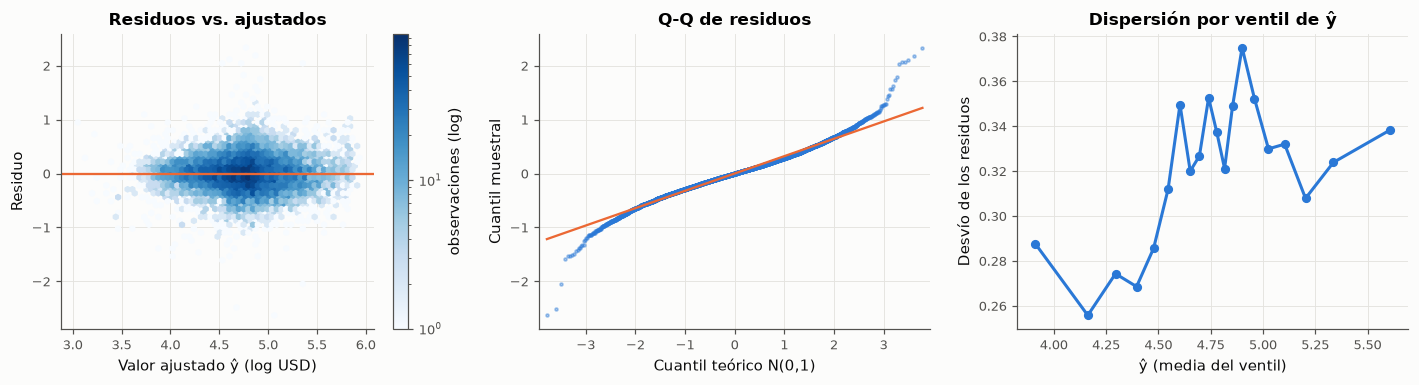

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
hb = ax[0].hexbin(
    mco.fittedvalues, mco.resid, gridsize=60, cmap=gr.SECUENCIAL, mincnt=1, bins="log"
)
ax[0].axhline(0, color=gr.NARANJA, lw=1.5)
ax[0].set(xlabel="Valor ajustado ŷ (log USD)", ylabel="Residuo", title="Residuos vs. ajustados")
fig.colorbar(hb, ax=ax[0], label="observaciones (log)")
sm.qqplot(
    mco.resid,
    line="s",
    ax=ax[1],
    markersize=2,
    alpha=0.4,
    markerfacecolor=gr.AZUL,
    markeredgecolor=gr.AZUL,
)
ax[1].get_lines()[1].set(color=gr.NARANJA, lw=1.5)
ax[1].set(title="Q-Q de residuos", xlabel="Cuantil teórico N(0,1)", ylabel="Cuantil muestral")
cuantiles = pd.qcut(mco.fittedvalues, 20)
disp = mco.resid.groupby(cuantiles, observed=True).std()
ax[2].plot(
    mco.fittedvalues.groupby(cuantiles, observed=True).mean(), disp, "o-", color=gr.AZUL, ms=5
)
ax[2].set(
    xlabel="ŷ (media del ventil)",
    ylabel="Desvío de los residuos",
    title="Dispersión por ventil de ŷ",
)
fig.tight_layout()
gr.guardar(fig, "f2_residuos")
plt.show()

**Homocedasticidad: se rechaza.** Breusch-Pagan LM = 515,92 (gl = 17, p = 8,34·10⁻⁹⁹) y White
LM = 985,44 (p = 1,09·10⁻¹¹⁷). El panel derecho lo muestra: el desvío de los residuos va de 0,26 a
0,37 según el nivel de precio ajustado. (En la regresión auxiliar de White, el cuadrado de un regresor
binario es el mismo regresor: la matriz tiene rango incompleto por construcción y statsmodels toma
los grados de libertad del rango, así que el estadístico es válido.)
**Remediación:** errores estándar robustos **HC3**. Los EE suben hasta un 31 %
(`sin_historial_precio`) y un 21 % (`sin_resenas`, cuyo p pasa de 0,067 a 0,131). Las
conclusiones sustantivas no cambian; los coeficientes MCO siguen siendo insesgados, solo era
incorrecta su varianza.

**Normalidad: se rechaza** (JB = 4235,60; p < 10⁻³⁰⁰), pero con asimetría 0,081 y **curtosis
5,807**: colas pesadas y simétricas, visibles en los extremos del Q-Q. Con n = 12.858, los
contrastes t y F siguen siendo válidos asintóticamente (TCL); las colas pesadas motivan los
estimadores robustos de 2.3.

**Independencia:** Durbin-Watson = 1,9515 con las reservas en orden temporal, compatible con
ausencia de autocorrelación de primer orden ($\hat\rho \approx 1 - d/2 = 0{,}024$). Respalda la
partición aleatoria (no cronológica) de 2.0.

## 2.3 Observaciones extremas y puntos influyentes

* Residuo estudentizado externo: $r_i = \hat\varepsilon_i / (\hat\sigma_{(i)}\sqrt{1-h_{ii}})$; outlier de respuesta si $|r_i| > 3$.
* Leverage $h_{ii}$ (diagonal de $H = X(X^\top X)^{-1}X^\top$): extremo en $X$ si $h_{ii} > 2(p+1)/n$.
* Cook: $D_i = \frac{\hat\varepsilon_i^2}{(p+1)\,\mathrm{MSE}}\left[\frac{h_{ii}}{(1-h_{ii})^2}\right]$; influyente si $D_i > 4/n$ o $D_i > 0{,}5$.

**¿Error de medición o caso real?** Cruzamos los influyentes con el diagnóstico de escala del precio
de la Fase 1 (reservas cuyo gasto es compatible con precio por noche, por estadía o con ninguno).

In [25]:
inf = influencia(mco)
n_obs, k = int(mco.nobs), mco.model.exog.shape[1]
print(f"n = {n_obs}, p + 1 = {k} | umbrales: h > {2 * k / n_obs:.5f}, D > {4 / n_obs:.6f}")
print(
    inf[["outlier_y", "alto_leverage", "influyente_4n", "influyente_05"]].sum().to_dict(),
    f"| D máx = {inf.cook.max():.4f}",
)
esc_tr = diagnostico_escala_precio(rtr)[["escala"]]
cruce = (
    rtr[[]]
    .join(esc_tr)
    .fillna({"escala": "1 noche (sin ambigüedad)"})
    .join(inf[["influyente_4n", "outlier_y"]])
)
cruce.groupby("escala")[["influyente_4n", "outlier_y"]].agg(["mean", "size"]).round(4)

n = 12858, p + 1 = 18 | umbrales: h > 0.00280, D > 0.000311
{'outlier_y': 121, 'alto_leverage': 841, 'influyente_4n': 748, 'influyente_05': 0} | D máx = 0.0117


influyente_4n       outlier_y      
                                  mean  size      mean  size
escala                                                      
1 noche (sin ambigüedad)        0.0487  6268    0.0086  6268
incompatible                    0.0951   610    0.0262   610
por_estadia                     0.0791   215    0.0186   215
por_noche                       0.0638  5765    0.0082  5765

In [26]:
y_r, X_r = rtr["log_precio_noche"], rtr[X_MCO].astype(float)
huber = HuberRegressor(epsilon=1.35, max_iter=1000).fit(X_r, y_r)
# RANSAC con el umbral por defecto (MAD de y, no de los residuos): experimento fallido (Entrada 3)
ransac = RANSACRegressor(random_state=SEED).fit(X_r, y_r)
# RANSAC corregido: umbral = 3 · σ robusto de los residuos MCO (1,4826 · MAD)
sigma_rob = 1.4826 * np.median(np.abs(mco.resid - np.median(mco.resid)))
ransac3 = RANSACRegressor(residual_threshold=3 * sigma_rob, random_state=SEED).fit(X_r, y_r)
sin_inf = smf.ols(FORMULA, rtr[~inf["influyente_4n"].to_numpy()]).fit()
robustez = pd.DataFrame(
    {
        "MCO": mco.params[X_MCO],
        "MCO sin D>4/n": sin_inf.params[X_MCO],
        "Huber": pd.Series(huber.coef_, index=X_MCO),
        "RANSAC (defecto)": pd.Series(ransac.estimator_.coef_, index=X_MCO),
        "RANSAC (3σ rob.)": pd.Series(ransac3.estimator_.coef_, index=X_MCO),
    }
)
print(
    f"RANSAC defecto: {ransac.inlier_mask_.mean():.2%} de inliers | RANSAC 3σ: "
    f"{ransac3.inlier_mask_.mean():.2%} | Huber: {np.mean(huber.outliers_):.2%} marcados como outliers"
)
print(
    "Máx. |coef − MCO sin influyentes|:",
    (robustez.drop(columns="MCO sin D>4/n").sub(robustez["MCO sin D>4/n"], axis=0))
    .abs()
    .max()
    .round(4)
    .to_dict(),
)
print(f"R² MCO sin influyentes: {sin_inf.rsquared:.4f} (n = {int(sin_inf.nobs)})")
robustez.round(4)

RANSAC defecto: 55.01% de inliers | RANSAC 3σ: 89.07% | Huber: 37.15% marcados como outliers
Máx. |coef − MCO sin influyentes|: {'MCO': 0.0237, 'Huber': 0.0135, 'RANSAC (defecto)': 0.3401, 'RANSAC (3σ rob.)': 0.0577}
R² MCO sin influyentes: 0.6858 (n = 12110)


,MCO,MCO sin D>4/n,Huber,RANSAC (defecto),RANSAC (3σ rob.)
prop_starrating,0.0600,0.0453,0.0462,-0.0459,0.0586
prop_review_score,0.0545,0.0455,0.0455,-0.0621,0.0744
sin_resenas,-0.0347,-0.0151,-0.0016,-0.0006,0.0086
prop_location_score1,0.0038,-0.0004,0.0000,-0.0066,0.0219
prop_location_score2,0.0414,0.0550,0.0565,0.1010,0.0686
prop_log_historical_price,0.7666,0.7789,0.7843,0.9920,0.8218
sin_historial_precio,0.0461,0.0224,0.0263,-0.2537,0.0252
prop_brand_bool,-0.0023,-0.0104,-0.0088,-0.0069,-0.0026
promotion_flag,-0.1611,-0.1569,-0.1503,0.0577,-0.1874
srch_length_of_stay,0.0062,0.0059,0.0053,0.0621,-0.0119


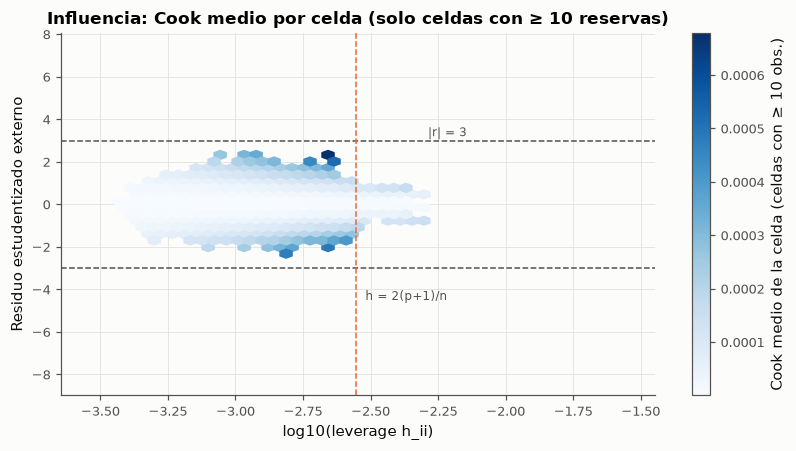

In [27]:
# Solo agregados (decisión de Verónica, 12/11): densidad por celdas, sin puntos individuales
fig, ax = plt.subplots(figsize=(7.5, 4.2))
hb = ax.hexbin(np.log10(inf["leverage"]), inf["r_ext"], C=inf["cook"], reduce_C_function=np.mean,
               gridsize=45, cmap=gr.SECUENCIAL, mincnt=10)  # fmt: skip
fig.colorbar(hb, ax=ax, label="Cook medio de la celda (celdas con ≥ 10 obs.)")
ax.axhline(3, color=gr.TEXTO_2, ls="--", lw=1)
ax.axhline(-3, color=gr.TEXTO_2, ls="--", lw=1)
ax.axvline(np.log10(2 * k / n_obs), color=gr.NARANJA, ls="--", lw=1)
ax.annotate(
    "|r| = 3", xy=(np.log10(inf.leverage).quantile(0.99), 3.2), fontsize=8, color=gr.TEXTO_2
)
ax.annotate(
    "h = 2(p+1)/n",
    xy=(np.log10(2 * k / n_obs), -4.5),
    xytext=(6, 0),
    textcoords="offset points",
    fontsize=8,
    color=gr.TEXTO_2,
)
ax.set(
    xlabel="log10(leverage h_ii)",
    ylabel="Residuo estudentizado externo",
    title="Influencia: Cook medio por celda (solo celdas con ≥ 10 reservas)",
)
fig.tight_layout()
gr.guardar(fig, "f2_influencia")
plt.show()

**Diagnóstico** (n = 12.858, p + 1 = 18): 121 outliers de respuesta (|r| > 3), 841 puntos de alto
leverage (h > 0,0028) y 748 influyentes según D > 4/n = 0,000311. **Ningún punto supera
D = 0,5** (D máx = 0,0117). No hay un punto que, por sí solo, mueva la recta; hay un grupo de
puntos moderadamente influyentes.

**¿Error de medición o caso real?** Cruzado con el diagnóstico de escala del precio (Fase 1), la
tasa de influyentes es del 4,87 % en reservas de 1 noche y del 6,38 % en las compatibles con
precio por noche, pero sube al **7,91 %** en las de precio por estadía y al **9,51 %** en las
incompatibles con ambas escalas. Lo mismo ocurre con los outliers de respuesta: 0,82-0,86 %
contra 1,86 % y 2,62 %. **Parte de la influencia es error de medición** (precio informado en la
escala equivocada). El resto son casos reales de colas pesadas.

**Regresión robusta:**
* Quitar los 748 influyentes sube el R² a 0,6858 y cambia los coeficientes a lo sumo en 0,024
  (estrellas: 0,060 → 0,045).
* **Huber** ($\epsilon$ = 1,35) llega casi a los mismos coeficientes que MCO sin influyentes
  (diferencia máxima 0,014) sin descartar datos: es la especificación de resguardo.
* **RANSAC con el umbral por defecto: experimento fallido (Entrada 3).** El umbral por defecto es
  la MAD de *y*, no de los residuos, y con 17 regresores deja solo el 55,01 % de inliers. Los
  coeficientes se vuelven inestables: estrellas −0,046, habitaciones +0,311; diferencia máxima con
  MCO sin influyentes, 0,340.
* Con el umbral corregido (3 σ̂ robustos de los residuos MCO) retiene el 89,07 % y la diferencia
  máxima baja a 0,058.

**Decisión:** MCO con errores HC3 como especificación principal, y Huber como resguardo. Los
influyentes no se eliminan: la mayoría son casos reales, y la parte que es error de medición ya
está neutralizada en las fases siguientes por el precio relativo a la búsqueda.

## 2.4 Multicolinealidad (VIF)

$\mathrm{VIF}_j = 1/(1-R_j^2)$, donde $R_j^2$ es el de la regresión de $X_j$ sobre los demás
regresores. Mide cuánto se infla $\operatorname{Var}(\hat\beta_j)$ respecto de regresores
ortogonales. Umbrales: 5 (atención) y 10 (severa). Lo calculamos para el modelo de 2.1 y para el
conjunto ampliado que usará el torneo de la Fase 3 (agrega precio, precio relativo, competidores y
posición).

In [28]:
X_AMPLIADO = X_MCO + [
    "log_precio",
    "log_precio_rel",
    "comp_n_info",
    "position",
    "prop_location_score2_faltante",
]
vif = pd.concat(
    {
        "VIF modelo 2.1": tabla_vif(rtr[X_MCO]),
        "VIF conjunto ampliado (Fase 3)": tabla_vif(df.loc[df.train, X_AMPLIADO]),
    },
    axis=1,
)
vif.sort_values("VIF conjunto ampliado (Fase 3)", ascending=False).round(2).head(10)

,VIF modelo 2.1,VIF conjunto ampliado (Fase 3)
log_precio,NaN,2.98
prop_log_historical_price,1.74,2.63
prop_starrating,1.70,1.97
log_precio_rel,NaN,1.92
prop_location_score1,1.28,1.54
prop_review_score,1.30,1.43
srch_booking_window,1.08,1.42
comp_n_info,NaN,1.41
srch_adults_count,1.30,1.29
srch_room_count,1.30,1.29


**No hay multicolinealidad relevante.** En el modelo de 2.1 el VIF máximo es 1,74 (precio
histórico) y 1,70 (estrellas). En el conjunto ampliado de la Fase 3 el máximo es 2,98
(`log_precio`), seguido por 2,63 (precio histórico) y 1,97 (estrellas). Ninguna variable se acerca a
5. **Corrige una anticipación de la Fase 1:** las correlaciones de a pares de hasta 0,62 entre
estrellas y precio histórico hacían esperar multicolinealidad, pero un $R^2_j$ auxiliar de a lo sumo
1 − 1/2,98 = 0,66 no infla las varianzas en forma preocupante (se registra en la Entrada 3).
**Decisión:** no se eliminan ni combinan regresores por colinealidad. La regularización Ridge/Lasso
de la Fase 3 se justifica por selección y estabilidad predictiva, no por un VIF alto.

## 2.5 Reducción de dimensionalidad con PCA (sin fuga de datos)

**Regla estricta:** la estandarización (media y desvío) y la descomposición espectral de la matriz
de correlaciones se calculan **solo con las filas de Train**; Test se proyecta con esa misma
rotación (`pipe.transform`), sin reajustar. `tests/test_fase2.py::test_pca_se_ajusta_solo_con_train`
lo verifica.

Variables: atributos continuos del hotel en la fila búsqueda × hotel (la unidad del torneo de la
Fase 3). Criterios de retención: codo del scree plot y Kaiser ($\lambda_k > 1$ sobre variables
estandarizadas).

In [29]:
X_PCA = [
    "prop_starrating", "prop_review_score", "prop_location_score1", "prop_location_score2",
    "prop_log_historical_price", "log_precio", "log_precio_rel", "promotion_flag",
    "prop_brand_bool", "comp_n_info",
]  # fmt: skip
pca_pipe = ajustar_pca(df[df.train], X_PCA, seed=SEED)
var_pca, cargas = resumen_pca(pca_pipe, X_PCA)
n_kaiser = int((var_pca["autovalor"] > 1).sum())
print(
    f"Kaiser (λ > 1): {n_kaiser} componentes, {var_pca['pct_acum'].iloc[n_kaiser - 1]:.1f} % de la varianza"
)
Z_test = pca_pipe.transform(df.loc[~df.train, X_PCA].astype(float))
print(f"Test proyectado con la rotación de Train: {Z_test.shape}")
var_pca.round(3)

Kaiser (λ > 1): 4 componentes, 69.7 % de la varianza
Test proyectado con la rotación de Train: (148509, 10)


,autovalor,pct_var,pct_acum
PC1,3.264,32.645,32.645
PC2,1.515,15.152,47.796
PC3,1.184,11.840,59.637
PC4,1.002,10.018,69.654
PC5,0.749,7.493,77.147
PC6,0.637,6.368,83.515
PC7,0.572,5.724,89.239
PC8,0.455,4.547,93.786
PC9,0.404,4.045,97.831
PC10,0.217,2.169,100.000


In [30]:
cargas.iloc[:, :4].round(3)

,PC1,PC2,PC3,PC4
prop_starrating,0.441,-0.003,-0.018,0.209
prop_review_score,0.351,-0.226,0.017,0.093
prop_location_score1,0.248,0.547,0.102,-0.208
prop_location_score2,0.153,0.479,0.088,-0.544
prop_log_historical_price,0.468,0.026,-0.011,0.054
log_precio,0.470,-0.105,-0.100,-0.077
log_precio_rel,0.387,-0.303,-0.120,-0.075
promotion_flag,0.063,0.379,0.171,0.745
prop_brand_bool,0.001,-0.413,0.576,-0.193
comp_n_info,0.065,0.041,0.771,0.050


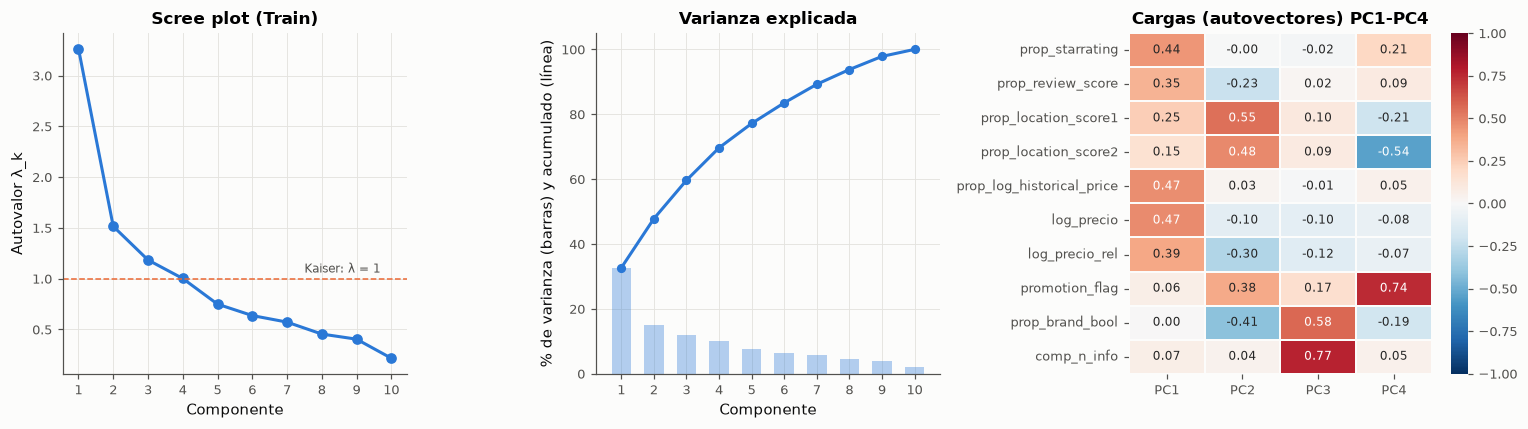

In [31]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 1, 1.1]})
pcs = np.arange(1, len(var_pca) + 1)
ax[0].plot(pcs, var_pca["autovalor"], "o-", color=gr.AZUL, ms=6)
ax[0].axhline(1, color=gr.NARANJA, ls="--", lw=1)
ax[0].annotate("Kaiser: λ = 1", xy=(len(pcs) - 2.5, 1.06), fontsize=8, color=gr.TEXTO_2)
ax[0].set(xlabel="Componente", ylabel="Autovalor λ_k", title="Scree plot (Train)", xticks=pcs)
ax[1].bar(pcs, var_pca["pct_var"], color=gr.AZUL, alpha=0.35, width=0.6)
ax[1].plot(pcs, var_pca["pct_acum"], "o-", color=gr.AZUL, ms=5)
ax[1].set(
    xlabel="Componente",
    ylabel="% de varianza (barras) y acumulado (línea)",
    title="Varianza explicada",
    xticks=pcs,
    ylim=(0, 105),
)
sns.heatmap(
    cargas.iloc[:, :4],
    cmap=gr.DIVERGENTE,
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    linewidths=1,
    linecolor=gr.SUPERFICIE,
    ax=ax[2],
)
ax[2].set_title("Cargas (autovectores) PC1-PC4")
ax[2].grid(False)
fig.tight_layout()
gr.guardar(fig, "f2_pca")
plt.show()

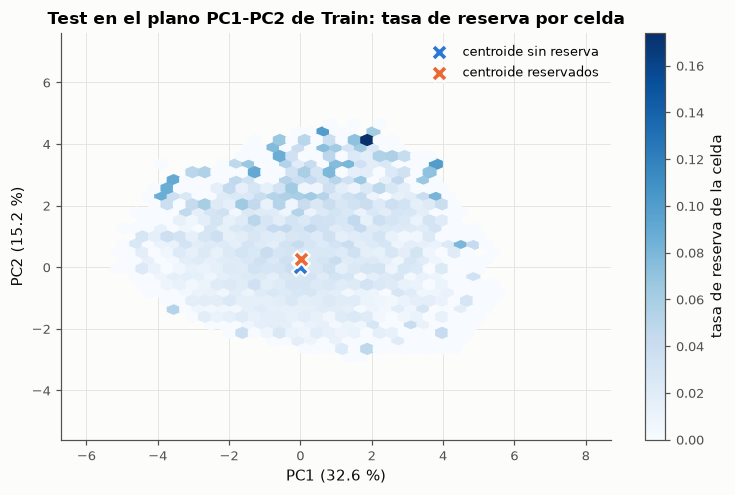

,PC1,PC2
reserva,,
0,-0.0063,-0.0035
1,0.0069,0.2700


In [32]:
proy = pd.DataFrame(Z_test[:, :2], columns=["PC1", "PC2"]).assign(
    reserva=df.loc[~df.train, "booking_bool"].to_numpy()
)
# Solo agregados: tasa de reserva por celda del plano (celdas con ≥ 10 hoteles), sin puntos individuales
fig, ax = plt.subplots(figsize=(7, 4.6))
hb = ax.hexbin(proy.PC1, proy.PC2, C=proy.reserva, reduce_C_function=np.mean, gridsize=40,
               cmap=gr.SECUENCIAL, mincnt=10, extent=(-6, 8, -5, 7))  # fmt: skip
fig.colorbar(hb, ax=ax, label="tasa de reserva de la celda")
medias_pc = proy.groupby("reserva")[["PC1", "PC2"]].mean()
for r, color, nombre in [
    (0, gr.AZUL, "centroide sin reserva"),
    (1, gr.NARANJA, "centroide reservados"),
]:
    ax.scatter(
        *medias_pc.loc[r],
        s=120,
        color=color,
        marker="X",
        edgecolor=gr.SUPERFICIE,
        lw=1.5,
        label=nombre,
        zorder=3,
    )
ax.set(
    xlabel=f"PC1 ({var_pca.pct_var.iloc[0]:.1f} %)",
    ylabel=f"PC2 ({var_pca.pct_var.iloc[1]:.1f} %)",
    title="Test en el plano PC1-PC2 de Train: tasa de reserva por celda",
)
ax.legend(loc="upper right")
fig.tight_layout()
gr.guardar(fig, "f2_pca_plano")
plt.show()
proy.groupby("reserva")[["PC1", "PC2"]].mean()

**Retención.** Kaiser retiene **4 componentes** (λ = 3,264; 1,515; 1,184; 1,002), que explican el
69,7 % de la varianza. El cuarto está en el límite (λ = 1,002). El codo del scree plot está en la
2.ª componente (de 3,26 a 1,52, y después la caída se suaviza). **Decisión:** 2 componentes para la
visualización (plano PC1-PC2 de la app, módulo de diagnóstico) y 4 para el conjunto alternativo de
features que se pone a prueba en la Fase 3.

**Interpretación de negocio de las cargas:**
* **PC1 (32,6 %): "categoría y precio".** Cargas positivas y parecidas en estrellas (0,44), precio
  histórico (0,47), precio (0,47), precio relativo (0,39) y reseñas (0,35). Ordena los hoteles de
  económicos a premium.
* **PC2 (15,2 %): "buena ubicación a buen precio, independiente".** Ubicación (0,55 y 0,48) y
  promoción (0,38), con signo opuesto al de cadena (−0,41) y al precio relativo (−0,30).
* PC3 (11,8 %): cobertura de competidores (0,77) y pertenencia a cadena (0,58).
  PC4 (10,0 %): promoción (0,75) frente a `location_score2` (−0,54).

**Proyección ciega de Test.** Los hoteles reservados tienen PC2 medio = 0,270, contra −0,0035 de
los no reservados. En PC1 la diferencia es mínima (0,0069 vs. −0,0063). **Lo que se reserva no es
lo más caro ni lo de mayor categoría, sino lo bien ubicado, en promoción y barato para su
búsqueda.** Es un hallazgo predictivo, no causal (Fase 4).

## 2.6 Síntesis de la Fase 2

| Supuesto / análisis | Resultado | Remediación |
|---|---|---|
| Especificación | Precio crudo: R² = 0,0028, Cook máx 1,215 (fallido) | log(precio) sin outliers: R² = 0,604 |
| Homocedasticidad | Se rechaza (BP p = 8,34·10⁻⁹⁹; White p = 1,09·10⁻¹¹⁷) | Errores HC3 (EE hasta +31 %) |
| Normalidad | Se rechaza (JB), curtosis 5,81, asimetría 0,08 | TCL (n = 12.858) + estimador robusto de Huber |
| Independencia | DW = 1,95 | Ninguna; respalda la partición aleatoria |
| Influyentes | 748 con D > 4/n, ninguno con D > 0,5; más frecuentes con escala de precio errónea | Huber como resguardo; RANSAC con umbral 3σ̂ (el de defecto falla) |
| Multicolinealidad | VIF máx 1,74 (modelo) y 2,98 (conjunto Fase 3) | Ninguna |
| PCA (solo Train) | 4 comp. por Kaiser (69,7 %), codo en 2; PC1 = categoría-precio, PC2 = ubicación/promoción | 2 PCs para la app, 4 como features alternativas en la Fase 3 |

---
# Fase 3 — Torneo predictivo, calibración y explicabilidad

**Pregunta predictiva:** $P(\text{reserva} \mid X)$ para cada hotel de una lista. Es la pregunta
observacional del enunciado ($P(Y \mid X)$), distinta de la causal de la Fase 4
($P(Y \mid do(T))$).

**Diseño (propuesto por Claude Code):**
* Unidad: fila búsqueda × hotel. $Y$ = `booking_bool`, con prevalencia ≈ 2 %: clasificación muy
  desbalanceada.
* Partición 80/20 de la Fase 2 (agrupada por búsqueda y estratificada por `random_bool`). La
  validación cruzada es `StratifiedGroupKFold(5)` por `srch_id` dentro de Train: estratificada como
  pide el enunciado y agrupada para que ninguna lista se parta entre pliegues.
* Métrica de selección: **PR-AUC** (precisión promedio). Con 2 % de positivos, la exactitud y el
  ROC-AUC son optimistas; la PR-AUC mide directamente cuánto se concentran las reservas arriba.
* **Sin fuga:** se excluyen `click_bool` (mediador posterior a la exposición, que ocurre en la
  misma sesión que la reserva), el gasto y la propia respuesta (`tests/test_modelos.py`).
  `position` sí entra: se conoce al mostrar la lista.
* **Cómputo:** las búsquedas de hiperparámetros se hacen sobre una submuestra del 25 % de las
  búsquedas de Train (búsquedas completas, misma semilla). Los modelos finales se reentrenan con
  todo Train y se evalúan una sola vez en Test.

In [33]:
import time

from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    f1_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_predict
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

from tpi.modelos import (
    FEATURES,
    OBJETIVO,
    acierto_top_k,
    cv_agrupado,
    matriz,
    metricas,
    submuestra_busquedas,
    umbral_f1,
)
from tpi.preparacion import preparar

# Verificación: los pasos expositivos de la Fase 1 coinciden con el pipeline reutilizable
pd.testing.assert_frame_equal(matriz(df), matriz(preparar(crudo)), check_dtype=False)
tr, te = df[df.train], df[~df.train]
X_tr, y_tr, g_tr = matriz(tr), tr[OBJETIVO].to_numpy(), tr["srch_id"].to_numpy()
X_te, y_te = matriz(te), te[OBJETIVO].to_numpy()
sub = submuestra_busquedas(tr, 0.25)
X_sub, y_sub, g_sub = matriz(sub), sub[OBJETIVO].to_numpy(), sub["srch_id"].to_numpy()
CV = cv_agrupado()
print(
    f"Train: {len(tr):,} filas ({tr.srch_id.nunique():,} búsquedas), prevalencia {y_tr.mean():.4f}"
)
print(
    f"Test:  {len(te):,} filas ({te.srch_id.nunique():,} búsquedas), prevalencia {y_te.mean():.4f}"
)
print(
    f"Submuestra de búsqueda de hiperparámetros: {len(sub):,} filas ({sub.srch_id.nunique():,} búsquedas)"
)
TIEMPOS = {}

Train: 590,814 filas (24,000 búsquedas), prevalencia 0.0218
Test:  148,509 filas (6,000 búsquedas), prevalencia 0.0217
Submuestra de búsqueda de hiperparámetros: 148,050 filas (6,000 búsquedas)


## 3.1 Familia 1 — Regresión logística regularizada

$\operatorname{logit} P(Y=1\mid X) = \beta_0 + X^\top\beta$, estimada maximizando la verosimilitud
penalizada $\ell(\beta) - \lambda\,\Omega(\beta)$ con $\Omega = \lVert\beta\rVert_1$ (Lasso) o
$\tfrac12\lVert\beta\rVert_2^2$ (Ridge), sobre variables estandarizadas ($C = 1/\lambda$). La
búsqueda en grilla elige penalización y $C$ por PR-AUC con CV agrupada.

Para interpretar, los **odds ratios** $\mathrm{OR}_j = e^{\beta_j}$ con IC 95 % salen de una
logística **sin penalizar** sobre Train con errores robustos por clúster de búsqueda (la
penalización sesga los coeficientes y no tiene IC exactos).

In [34]:
t0 = time.time()
grid_log = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(solver="saga", max_iter=3000)),
    {
        "logisticregression__penalty": ["l1", "l2"],
        "logisticregression__C": [0.001, 0.01, 0.1, 1, 10],
    },
    scoring="average_precision",
    cv=CV,
    n_jobs=-1,
)
grid_log.fit(X_sub, y_sub, groups=g_sub)
logit = clone(grid_log.best_estimator_).fit(X_tr, y_tr)
TIEMPOS["Logística"] = time.time() - t0
print("Mejor:", grid_log.best_params_, f"| PR-AUC CV = {grid_log.best_score_:.4f}")
coef = pd.Series(logit[-1].coef_[0], index=FEATURES)
print(f"Coeficientes anulados por la penalización: {int((coef == 0).sum())} de {len(coef)}")

Mejor: {'logisticregression__C': 0.1, 'logisticregression__penalty': 'l1'} | PR-AUC CV = 0.1415
Coeficientes anulados por la penalización: 0 de 27


In [35]:
X_or = sm.add_constant(X_tr)
logit_sm = sm.Logit(y_tr, X_or).fit(
    disp=0, cov_type="cluster", cov_kwds={"groups": g_tr}, maxiter=200
)
ic_or = np.exp(logit_sm.conf_int())
tabla_or = pd.DataFrame(
    {
        "OR": np.exp(logit_sm.params),
        "IC95_inf": ic_or[0],
        "IC95_sup": ic_or[1],
        "p": logit_sm.pvalues,
    }
).drop("const")
tabla_or.sort_values("p").round(4)

,OR,IC95_inf,IC95_sup,p
position,0.8991,0.8964,0.9017,0.0000
random_bool,0.1462,0.1392,0.1536,0.0000
prop_location_score2,4.3813,4.0162,4.7797,0.0000
log_precio_rel,0.3993,0.3770,0.4230,0.0000
prop_location_score2_faltante,0.6489,0.6156,0.6840,0.0000
prop_review_score,1.2957,1.2521,1.3408,0.0000
prop_location_score1,0.9153,0.9043,0.9264,0.0000
log_precio,0.7551,0.7261,0.7852,0.0000
prop_starrating,1.1773,1.1479,1.2074,0.0000
srch_length_of_stay,0.9542,0.9472,0.9613,0.0000


**Lectura.**
- La grilla elige **L1 con C = 0,1** (PR-AUC en CV de 0,1415), pero ningún coeficiente se anula:
  con 150.000 filas, todas las variables aportan algo.
- Odds ratios (logit sin penalizar, errores por clúster de búsqueda; todos *ceteris paribus* y
  **asociativos, no causales**):
  - Cada posición más abajo multiplica las chances de reserva por 0,899 (IC 95 % [0,896; 0,902]).
  - `location_score2` tiene el OR más alto (4,38 por unidad de score).
  - Ser más caro que la mediana de la búsqueda las baja: OR 0,40 por unidad de log precio relativo.
  - Las estrellas (1,18) y las reseñas (1,30) las suben; también que Expedia sea más barata que sus
    competidores (`comp_saldo`, OR 1,12).
  - El OR de `random_bool` (0,146) **no es un efecto**: refleja que el proveedor sobremuestreó
    compras solo en el estrato del algoritmo (Fase 0).

## 3.2 Familia 2 — Naive Bayes gaussiano

$P(Y\mid X) \propto P(Y)\prod_j P(X_j \mid Y)$, con $X_j \mid Y \sim N(\mu_{jy}, \sigma^2_{jy})$.
Elegimos `GaussianNB` porque la mayoría de las variables son continuas o de conteo; las
binarias quedan aproximadas por una normal, lo que es parte del problema que se evalúa.
**Supuesto clave:** independencia condicional de las $X_j$ dada la clase. Lo auditamos con las
correlaciones **dentro de cada clase**: si fueran independientes, serían ≈ 0.

In [36]:
t0 = time.time()
nb = make_pipeline(StandardScaler(), GaussianNB()).fit(X_tr, y_tr)
TIEMPOS["Naive Bayes"] = time.time() - t0
corr_clase = {
    c: X_tr[y_tr == c].corr().abs().where(~np.eye(len(FEATURES), dtype=bool)) for c in (0, 1)
}
for c in (0, 1):
    v = corr_clase[c].stack()
    print(
        f"Clase {c}: |r| máx = {v.max():.3f} ({v.idxmax()}), pares con |r| > 0,3: {int((v > 0.3).sum() / 2)}"
    )

Clase 0: |r| máx = 0.721 (('prop_log_historical_price', 'log_precio')), pares con |r| > 0,3: 15
Clase 1: |r| máx = 0.718 (('prop_log_historical_price', 'log_precio')), pares con |r| > 0,3: 13


**Violación del supuesto.** Dentro de cada clase hay pares fuertemente correlacionados: hasta |r| =
0,721 entre el precio y el precio histórico, y 15 pares con |r| > 0,3 en la clase 0. Naive Bayes
multiplica verosimilitudes como si fueran evidencia independiente, así que **cuenta varias veces la
misma información** y empuja las probabilidades a los extremos. La consecuencia se ve en 3.5: es el
modelo peor calibrado (Brier 0,0697 contra ≈ 0,020 de los demás).

## 3.3 Familia 3 — Árbol CART y poda por complejidad de costo

Primero un árbol **sin restricciones** (hasta hojas puras) para mostrar el sobreajuste. Después,
la poda de complejidad de costo minimiza $R_\alpha(T) = R(T) + \alpha\,|T|$, donde $R(T)$ es la
impureza total de las hojas y $|T|$ su número. `cost_complexity_pruning_path` da la sucesión de
$\alpha$ en la que se van podando ramas; elegimos $\alpha_{\text{opt}}$ por PR-AUC con CV agrupada
sobre una grilla de cuantiles de esa sucesión.

In [37]:
t0 = time.time()
arbol_libre = DecisionTreeClassifier(random_state=SEED).fit(X_tr, y_tr)
p_libre_tr, p_libre_te = (
    arbol_libre.predict_proba(X_tr)[:, 1],
    arbol_libre.predict_proba(X_te)[:, 1],
)
print(
    f"Árbol sin restricciones: {arbol_libre.get_n_leaves():,} hojas, profundidad {arbol_libre.get_depth()} | "
    f"PR-AUC Train = {average_precision_score(y_tr, p_libre_tr):.4f}, Test = {average_precision_score(y_te, p_libre_te):.4f} | "
    f"ROC-AUC Train = {roc_auc_score(y_tr, p_libre_tr):.4f}, Test = {roc_auc_score(y_te, p_libre_te):.4f}"
)
camino = DecisionTreeClassifier(random_state=SEED).cost_complexity_pruning_path(X_sub, y_sub)
alfas = np.unique(
    np.quantile(camino.ccp_alphas[camino.ccp_alphas > 0], np.linspace(0.5, 0.999, 25))
)
grid_arbol = GridSearchCV(
    DecisionTreeClassifier(random_state=SEED),
    {"ccp_alpha": alfas},
    scoring="average_precision",
    cv=CV,
    n_jobs=-1,
    return_train_score=True,
)
grid_arbol.fit(X_sub, y_sub, groups=g_sub)
alfa_opt = grid_arbol.best_params_["ccp_alpha"]
arbol = DecisionTreeClassifier(ccp_alpha=alfa_opt, random_state=SEED).fit(X_tr, y_tr)
TIEMPOS["CART podado"] = time.time() - t0
print(
    f"Camino de poda: {len(camino.ccp_alphas):,} valores de α; α_opt = {alfa_opt:.3e} "
    f"(PR-AUC CV = {grid_arbol.best_score_:.4f}) | árbol podado: {arbol.get_n_leaves()} hojas, profundidad {arbol.get_depth()}"
)

Árbol sin restricciones: 18,863 hojas, profundidad 45 | PR-AUC Train = 1.0000, Test = 0.0310 | ROC-AUC Train = 1.0000, Test = 0.5499


Camino de poda: 1,202 valores de α; α_opt = 2.253e-05 (PR-AUC CV = 0.1195) | árbol podado: 14 hojas, profundidad 6


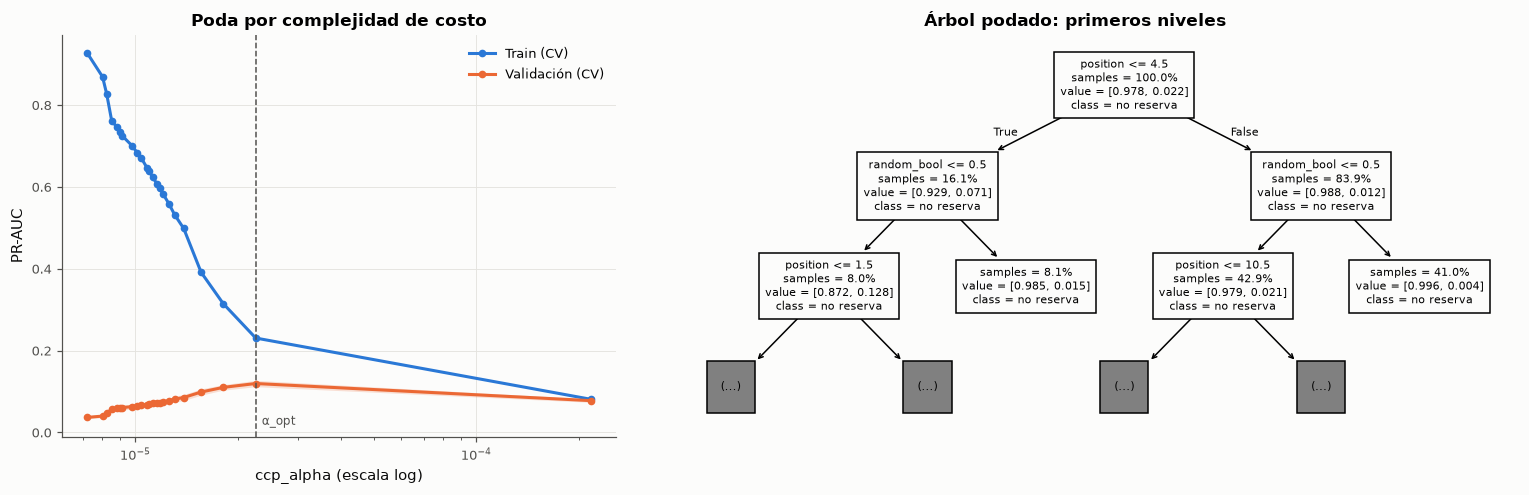

|--- position <= 4.50
|   |--- random_bool <= 0.50
|   |   |--- truncated branch of depth 5
|   |--- random_bool >  0.50
|   |   |--- class: 0
|--- position >  4.50
|   |--- random_bool <= 0.50
|   |   |--- truncated branch of depth 3
|   |--- random_bool >  0.50
|   |   |--- class: 0



In [38]:
cvr = pd.DataFrame(grid_arbol.cv_results_)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.6]})
ax[0].plot(
    cvr["param_ccp_alpha"].astype(float),
    cvr["mean_train_score"],
    "o-",
    color=gr.AZUL,
    ms=4,
    label="Train (CV)",
)
ax[0].plot(
    cvr["param_ccp_alpha"].astype(float),
    cvr["mean_test_score"],
    "o-",
    color=gr.NARANJA,
    ms=4,
    label="Validación (CV)",
)
ax[0].fill_between(
    cvr["param_ccp_alpha"].astype(float),
    cvr["mean_test_score"] - cvr["std_test_score"],
    cvr["mean_test_score"] + cvr["std_test_score"],
    color=gr.NARANJA,
    alpha=0.2,
    lw=0,
)
ax[0].axvline(alfa_opt, color=gr.TEXTO_2, ls="--", lw=1)
ax[0].annotate(
    "α_opt",
    xy=(alfa_opt, ax[0].get_ylim()[0]),
    xytext=(4, 8),
    textcoords="offset points",
    fontsize=8,
    color=gr.TEXTO_2,
)
ax[0].set(
    xscale="log",
    xlabel="ccp_alpha (escala log)",
    ylabel="PR-AUC",
    title="Poda por complejidad de costo",
)
ax[0].legend()
plot_tree(
    arbol,
    max_depth=2,
    feature_names=FEATURES,
    class_names=["no reserva", "reserva"],
    filled=False,
    impurity=False,
    proportion=True,
    fontsize=7,
    ax=ax[1],
)
ax[1].set_title("Árbol podado: primeros niveles")
fig.tight_layout()
gr.guardar(fig, "f3_cart")
plt.show()
print(export_text(arbol, feature_names=FEATURES, max_depth=1))

**Sobreajuste.** El árbol sin restricciones crece hasta 18.863 hojas y profundidad 45. Memoriza Train
(PR-AUC = 1,000) y fracasa en Test (PR-AUC = 0,031; ROC-AUC = 0,550, casi azar). La poda elige
$\alpha_{\text{opt}}$ = 2,25·10⁻⁵ entre 1.202 valores del camino y deja **14 hojas** (profundidad 6),
con PR-AUC de 0,120 en CV.

**Regla del nodo raíz:** `position ≤ 4,5`. El primer corte separa los hoteles de las posiciones 1-4
del resto: la posición es lo que más reduce la impureza. El segundo corte en ambas ramas es
`random_bool`, que separa los estratos con tasas base muy distintas. Ninguno de los dos cortes es
una palanca causal: es el punto de partida del ensayo de la Fase 4.

## 3.4 Familia 4 — Random Forest con búsqueda de hiperparámetros

Ensamble de $B$ árboles sobre muestras bootstrap y subconjuntos aleatorios de variables en cada
corte (`max_features`), lo que decorrelaciona los árboles y reduce la varianza del promedio.
`RandomizedSearchCV` (20 combinaciones, CV agrupada de 5 pliegues, `n_jobs=-1`) explora
`n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf` y `max_features`
(`sqrt`, `log2`, fracción). El error **out-of-bag** (OOB) usa, para cada fila, solo los árboles
que no la vieron: es una validación "gratis" que comparamos con la CV.

In [39]:
t0 = time.time()
busqueda_rf = RandomizedSearchCV(
    RandomForestClassifier(random_state=SEED, n_jobs=1),
    {
        "n_estimators": [100, 200, 300],
        "max_depth": [8, 12, 16, 24, None],
        "min_samples_split": [2, 10, 50, 200],
        "min_samples_leaf": [1, 5, 20, 50, 100],
        "max_features": ["sqrt", "log2", 0.3, 0.5],
    },
    n_iter=20,
    scoring="average_precision",
    cv=CV,
    n_jobs=-1,
    random_state=SEED,
)
busqueda_rf.fit(X_sub, y_sub, groups=g_sub)
print("Mejor:", busqueda_rf.best_params_, f"| PR-AUC CV = {busqueda_rf.best_score_:.4f}")
rf = RandomForestClassifier(
    **busqueda_rf.best_params_, oob_score=True, random_state=SEED, n_jobs=-1
).fit(X_tr, y_tr)
TIEMPOS["Random Forest"] = time.time() - t0
p_oob = rf.oob_decision_function_[:, 1]
ok = ~np.isnan(p_oob)
print(
    f"OOB (Train completo): PR-AUC = {average_precision_score(y_tr[ok], p_oob[ok]):.4f}, ROC-AUC = {roc_auc_score(y_tr[ok], p_oob[ok]):.4f}, error de clasificación = {1 - rf.oob_score_:.4f}"
)

Mejor: {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 50, 'max_features': 'log2', 'max_depth': 24} | PR-AUC CV = 0.1569


OOB (Train completo): PR-AUC = 0.1511, ROC-AUC = 0.8499, error de clasificación = 0.0218


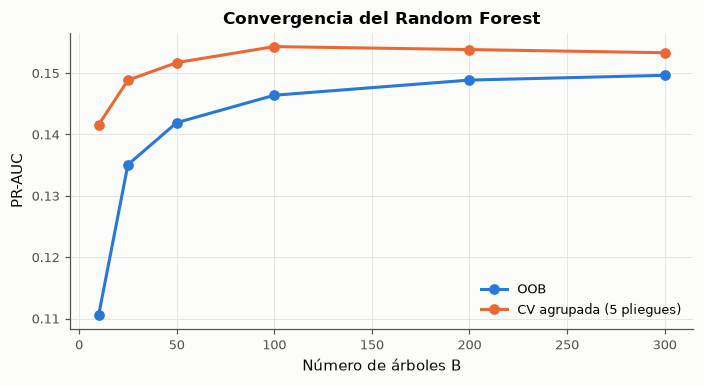

,arboles,PR_AUC_OOB,PR_AUC_CV
0,10,0.1105,0.1416
1,25,0.1351,0.1488
2,50,0.1419,0.1517
3,100,0.1464,0.1543
4,200,0.1488,0.1538
5,300,0.1496,0.1533


In [40]:
# Convergencia: OOB y CV en función del número de árboles (submuestra, mismos hiperparámetros)
param_conv = {k: v for k, v in busqueda_rf.best_params_.items() if k != "n_estimators"}
conv = []
for b in [10, 25, 50, 100, 200, 300]:
    m = RandomForestClassifier(
        n_estimators=b, oob_score=True, random_state=SEED, n_jobs=-1, **param_conv
    ).fit(X_sub, y_sub)
    po = m.oob_decision_function_[:, 1]
    okb = ~np.isnan(po)
    cv_b = cross_val_predict(
        clone(m).set_params(oob_score=False),
        X_sub,
        y_sub,
        groups=g_sub,
        cv=CV,
        method="predict_proba",
        n_jobs=1,
    )[:, 1]
    conv.append(
        {
            "arboles": b,
            "PR_AUC_OOB": average_precision_score(y_sub[okb], po[okb]),
            "PR_AUC_CV": average_precision_score(y_sub, cv_b),
        }
    )
conv = pd.DataFrame(conv)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(conv.arboles, conv.PR_AUC_OOB, "o-", color=gr.AZUL, label="OOB")
ax.plot(conv.arboles, conv.PR_AUC_CV, "o-", color=gr.NARANJA, label="CV agrupada (5 pliegues)")
ax.set(xlabel="Número de árboles B", ylabel="PR-AUC", title="Convergencia del Random Forest")
ax.legend()
fig.tight_layout()
gr.guardar(fig, "f3_rf_convergencia")
plt.show()
conv.round(4)

**Búsqueda.** La mejor combinación es 200 árboles, `max_depth` = 24, `min_samples_leaf` = 50,
`min_samples_split` = 10 y `max_features` = `log2`, con PR-AUC de 0,1569 en CV. **OOB vs. CV:** en Train
completo, el OOB da PR-AUC 0,1511 y ROC-AUC 0,8499, en línea con la CV. En la curva de
convergencia, ambas crecen con el número de árboles y se estabilizan desde ≈ 100-200 (OOB: 0,1488 →
0,1496 de 200 a 300 árboles; CV: 0,1538 → 0,1533). El OOB queda algo por debajo de la CV con pocos
árboles porque cada fila se evalúa solo con el ≈ 37 % de los árboles que no la vieron. La
diferencia se cierra al crecer B: es la convergencia que pide el enunciado.

## 3.5 Evaluación en Test, calibración y umbral

El umbral de clasificación se elige **en Train** (el que maximiza F1 en predicciones fuera de
pliegue de la submuestra) y se aplica tal cual en Test. Con 2 % de positivos, el umbral 0,5 por
defecto clasificaría casi todo como "no reserva".

In [41]:
MODELOS = {"Logística": logit, "Naive Bayes": nb, "CART podado": arbol, "Random Forest": rf}
prob_te, filas_test = {}, []
for nombre, m in MODELOS.items():
    p_oof = cross_val_predict(
        clone(m), X_sub, y_sub, groups=g_sub, cv=CV, method="predict_proba", n_jobs=-1
    )[:, 1]
    u = umbral_f1(y_sub, p_oof)
    p = m.predict_proba(X_te)[:, 1]
    prob_te[nombre] = p
    fila = {
        "modelo": nombre,
        **metricas(y_te, p, u),
        "F1 con umbral 0,5": f1_score(y_te, (p >= 0.5).astype(int)),
        "seg. entrenamiento": TIEMPOS[nombre],
    }
    filas_test.append(fila)
prob_te["Posición de Expedia (referencia)"] = 1 / te["position"].to_numpy()
tabla_test = pd.DataFrame(filas_test).set_index("modelo")
tabla_test.round(4)

,ROC_AUC,PR_AUC,Brier,Precision,Recall,F1,F1_macro,F1_ponderado,umbral,"F1 con umbral 0,5",seg. entrenamiento
modelo,,,,,,,,,,,
Logística,0.8439,0.1350,0.0198,0.1678,0.3039,0.2162,0.5958,0.9589,0.1090,0.0000,20.0158
Naive Bayes,0.7960,0.0740,0.0697,0.0694,0.0031,0.0059,0.4973,0.9673,0.9998,0.1411,0.3365
CART podado,0.8232,0.1197,0.0198,0.1511,0.3788,0.2161,0.5926,0.9527,0.0918,0.0000,21.1164
Random Forest,0.8540,0.1534,0.0196,0.1635,0.3897,0.2303,0.6005,0.9547,0.0903,0.0000,209.0928


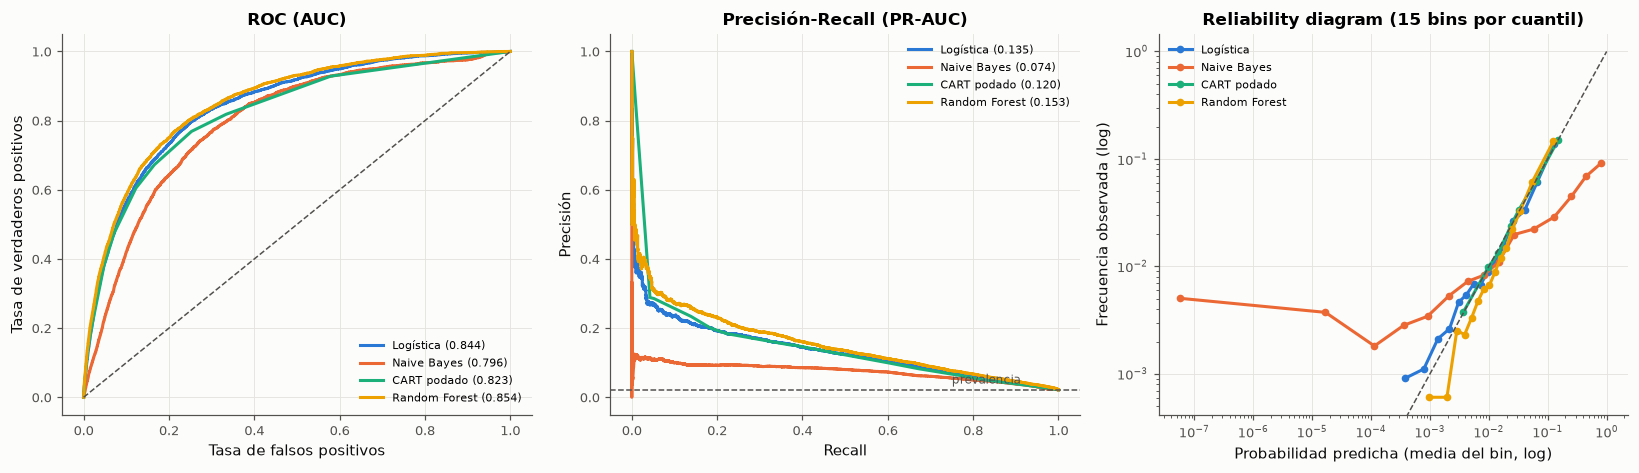

In [42]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
colores = {
    "Logística": gr.AZUL,
    "Naive Bayes": gr.NARANJA,
    "CART podado": gr.AQUA,
    "Random Forest": gr.AMARILLO,
}
for nombre, color in colores.items():
    p = prob_te[nombre]
    fpr, tpr, _ = roc_curve(y_te, p)
    ax[0].plot(fpr, tpr, color=color, label=f"{nombre} ({roc_auc_score(y_te, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_te, p)
    ax[1].plot(rc, pr, color=color, label=f"{nombre} ({average_precision_score(y_te, p):.3f})")
    fr, mp = calibration_curve(y_te, p, n_bins=15, strategy="quantile")
    ax[2].plot(mp, fr, "o-", color=color, ms=4, label=nombre)
ax[0].plot([0, 1], [0, 1], color=gr.TEXTO_2, ls="--", lw=1)
ax[0].set(
    xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos", title="ROC (AUC)"
)
ax[1].axhline(y_te.mean(), color=gr.TEXTO_2, ls="--", lw=1)
ax[1].annotate(
    "prevalencia",
    xy=(0.75, y_te.mean()),
    xytext=(0, 4),
    textcoords="offset points",
    fontsize=8,
    color=gr.TEXTO_2,
)
ax[1].set(xlabel="Recall", ylabel="Precisión", title="Precisión-Recall (PR-AUC)")
lim = max(max(prob_te[n].max() for n in colores), 0.5)
ax[2].plot([0, lim], [0, lim], color=gr.TEXTO_2, ls="--", lw=1)
ax[2].set(
    xscale="log",
    yscale="log",
    xlabel="Probabilidad predicha (media del bin, log)",
    ylabel="Frecuencia observada (log)",
    title="Reliability diagram (15 bins por cuantil)",
)
for a in ax:
    a.legend(fontsize=7.5, loc="best")
fig.tight_layout()
gr.guardar(fig, "f3_evaluacion")
plt.show()

**Ganador: Random Forest**, con PR-AUC 0,153 (unas 7 veces la prevalencia de 0,022), ROC-AUC 0,854 y
el menor Brier (0,0196). Le siguen la logística (PR-AUC 0,135) y el CART podado (0,120). Naive
Bayes queda último (0,074) y con un Brier de 0,0697: la violación de la independencia condicional
**destruye la calibración**. Su umbral elegido en Train (0,9998) no se traslada a Test (recall
0,003).

**Calibración (reliability diagram).** Logística, CART y RF quedan cerca de la diagonal; Naive Bayes
se aleja en los extremos.

**Umbral.** Con el umbral por defecto de 0,5, el F1 es 0 en logística, CART y RF: con
2 % de positivos nada supera 0,5. Con el umbral elegido en Train, el F1 de RF es 0,230 (precisión
0,164, recall 0,390). Es un experimento fallido documentado en la Entrada 3.

## 3.6 Explicabilidad: MDI vs. importancia por permutación

* **MDI** (disminución media de la impureza de Gini): suma, sobre todos los cortes que usan
  $X_j$, la reducción de impureza ponderada por las filas que pasan por el nodo. Se calcula en
  **Train**.
* **Permutación:** cuánto cae la PR-AUC en **Test** cuando se permuta $X_j$ (rompiendo su
  relación con $Y$ y con las demás variables), promediado en 5 repeticiones. Por cómputo, se usa
  una submuestra del 25 % de las búsquedas de Test.

In [43]:
te_sub = submuestra_busquedas(te, 0.25)
perm = permutation_importance(
    rf,
    matriz(te_sub),
    te_sub[OBJETIVO].to_numpy(),
    scoring="average_precision",
    n_repeats=5,
    random_state=SEED,
    n_jobs=-1,
)
imp = pd.DataFrame(
    {
        "MDI": rf.feature_importances_,
        "Permutación (ΔPR-AUC)": perm.importances_mean,
        "Permutación_de": perm.importances_std,
    },
    index=FEATURES,
)
imp["cardinalidad"] = [tr[f].nunique() for f in FEATURES]
imp["rango_MDI"] = imp["MDI"].rank(ascending=False).astype(int)
imp["rango_perm"] = imp["Permutación (ΔPR-AUC)"].rank(ascending=False).astype(int)
rho_card = stats.spearmanr(imp["cardinalidad"], imp["MDI"])
print(
    f"Spearman cardinalidad vs. MDI: ρ = {rho_card.statistic:.3f} (p = {rho_card.pvalue:.3g}); vs. permutación: ρ = {stats.spearmanr(imp['cardinalidad'], imp['Permutación (ΔPR-AUC)']).statistic:.3f}"
)
imp.sort_values("MDI", ascending=False).round(4)

Spearman cardinalidad vs. MDI: ρ = 0.701 (p = 4.68e-05); vs. permutación: ρ = 0.346


,MDI,Permutación (ΔPR-AUC),Permutación_de,cardinalidad,rango_MDI,rango_perm
position,0.3216,0.0987,0.0013,40,1,1
random_bool,0.1563,0.0753,0.0036,2,2,2
prop_location_score2,0.0973,0.0228,0.0020,8087,3,3
log_precio_rel,0.0693,0.0155,0.0020,237727,4,4
prop_location_score1,0.0564,0.0117,0.0021,337,5,5
log_precio,0.0560,0.0075,0.0018,43509,6,6
prop_log_historical_price,0.0415,0.0008,0.0008,376,7,11
orig_destination_distance,0.0377,-0.0005,0.0011,178306,8,25
srch_booking_window,0.0375,0.0000,0.0009,357,9,18
prop_review_score,0.0161,0.0036,0.0016,9,10,7


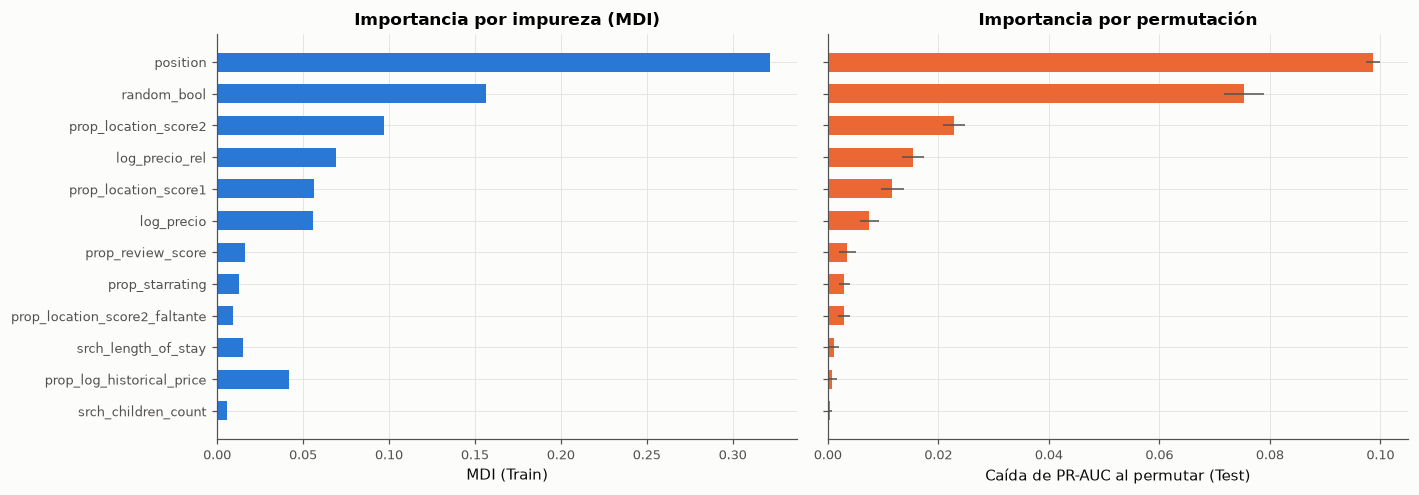

In [44]:
top = imp.sort_values("Permutación (ΔPR-AUC)", ascending=False).head(12).index[::-1]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
ax[0].barh(top, imp.loc[top, "MDI"], color=gr.AZUL, height=0.6)
ax[0].set(xlabel="MDI (Train)", title="Importancia por impureza (MDI)")
ax[1].barh(
    top,
    imp.loc[top, "Permutación (ΔPR-AUC)"],
    xerr=imp.loc[top, "Permutación_de"],
    color=gr.NARANJA,
    height=0.6,
    error_kw={"ecolor": gr.TEXTO_2, "lw": 1},
)
ax[1].set(xlabel="Caída de PR-AUC al permutar (Test)", title="Importancia por permutación")
fig.tight_layout()
gr.guardar(fig, "f3_importancias")
plt.show()

**El dilema MDI vs. permutación, con los datos.**
- El MDI correlaciona fuertemente con la cardinalidad de las variables (ρ de Spearman = 0,701,
  p = 4,7·10⁻⁵); la permutación, bastante menos (0,346).
- Ejemplos:
  - `orig_destination_distance` (178.306 valores distintos) es 8.ª en MDI, pero por permutación
    la PR-AUC de Test no cae (−0,0005): sus cortes no generalizan.
  - `prop_log_historical_price` es 7.ª en MDI y 11.ª por permutación.
  - `prop_starrating` (5 valores) sube del 13.° puesto en MDI al 8.° por permutación.

**Por qué:** el MDI suma reducciones de impureza **en Train**. Una variable continua ofrece miles de
cortes posibles, y el árbol encuentra entre ellos alguno que reduce impureza por azar (sobre todo
en nodos profundos con pocas filas). Una dummy ofrece un único corte. La permutación mide la caída
de desempeño **en Test** cuando se rompe la variable: los cortes que solo servían para memorizar no
generalizan y no cuentan.

**Las dos más importantes por ambos criterios:** `position` (caída de PR-AUC de 0,099) y
`random_bool` (0,075). La Fase 4 discute por qué ninguna de las dos es una palanca en la magnitud
que sugiere su importancia.

## 3.7 Sensibilidades propias

1. **Holdout cronológico** (pedido por Verónica): el mejor modelo se reentrena con las búsquedas
   del primer 80 % del período y se evalúa en el último 20 % (por `date_time`), para ver si el
   desempeño se sostiene hacia adelante.
2. **¿Ordena mejor que Expedia?** Entre las búsquedas de Test con reserva, en qué fracción el
   hotel reservado está en el top-5 del modelo, comparado con el top-5 de Expedia y separando
   orden del algoritmo (R = 0) y orden aleatorio (R = 1).
3. **PCA como features** (Fase 2): la logística con las 4 componentes de Train en lugar de las
   10 variables de hotel originales.

In [45]:
inicio_busq = df.groupby("srch_id")["date_time"].min().sort_values()
corte = inicio_busq.quantile(0.8)
ids_futuro = set(inicio_busq[inicio_busq > corte].index)
pasado, futuro = df[~df.srch_id.isin(ids_futuro)], df[df.srch_id.isin(ids_futuro)]
mejor = max(MODELOS, key=lambda n: tabla_test.loc[n, "PR_AUC"])
m_crono = clone(MODELOS[mejor]).fit(matriz(pasado), pasado[OBJETIVO])
p_fut = m_crono.predict_proba(matriz(futuro))[:, 1]
print(f"Mejor modelo: {mejor} | corte cronológico: {corte:%Y-%m-%d %H:%M}")
print(
    f"Holdout aleatorio: PR-AUC = {tabla_test.loc[mejor, 'PR_AUC']:.4f}, ROC-AUC = {tabla_test.loc[mejor, 'ROC_AUC']:.4f} | "
    f"Holdout cronológico ({futuro.srch_id.nunique():,} búsquedas): PR-AUC = {average_precision_score(futuro[OBJETIVO], p_fut):.4f}, "
    f"ROC-AUC = {roc_auc_score(futuro[OBJETIVO], p_fut):.4f}, prevalencia {futuro[OBJETIVO].mean():.4f}"
)

Mejor modelo: Random Forest | corte cronológico: 2013-05-21 20:45
Holdout aleatorio: PR-AUC = 0.1534, ROC-AUC = 0.8540 | Holdout cronológico (6,000 búsquedas): PR-AUC = 0.1438, ROC-AUC = 0.8454, prevalencia 0.0225


In [46]:
filas_rank = []
for r in (0, 1):
    d = te[te.random_bool == r]
    filas_rank.append(
        {
            "estrato": f"R = {r}",
            "búsquedas con reserva": int(d.groupby("srch_id")[OBJETIVO].max().sum()),
            "top-5 de Expedia": acierto_top_k(d, -d["position"], 5),
            f"top-5 del modelo ({mejor})": acierto_top_k(
                d, pd.Series(MODELOS[mejor].predict_proba(matriz(d))[:, 1]), 5
            ),
        }
    )
pd.DataFrame(filas_rank).set_index("estrato").round(4)

,búsquedas con reserva,top-5 de Expedia,top-5 del modelo (Random Forest)
estrato,,,
R = 0,2829,0.6052,0.6299
R = 1,389,0.4936,0.5681


In [47]:
X_HOTEL_PCA = X_PCA  # las 10 variables de hotel de la Fase 2
otras = [f for f in FEATURES if f not in X_HOTEL_PCA]
Z_tr = pd.DataFrame(
    pca_pipe.transform(tr[X_HOTEL_PCA].astype(float))[:, :4],
    columns=[f"PC{i}" for i in range(1, 5)],
    index=tr.index,
)
Z_te = pd.DataFrame(
    pca_pipe.transform(te[X_HOTEL_PCA].astype(float))[:, :4], columns=Z_tr.columns, index=te.index
)
logit_pca = clone(grid_log.best_estimator_).fit(pd.concat([Z_tr, matriz(tr, otras)], axis=1), y_tr)
p_pca = logit_pca.predict_proba(pd.concat([Z_te, matriz(te, otras)], axis=1))[:, 1]
print(
    f"Logística con 4 PCs + resto: PR-AUC Test = {average_precision_score(y_te, p_pca):.4f} vs. {tabla_test.loc['Logística', 'PR_AUC']:.4f} con las variables originales"
)

Logística con 4 PCs + resto: PR-AUC Test = 0.1190 vs. 0.1350 con las variables originales


1. **Holdout cronológico.** Entrenado con el 80 % inicial del período y evaluado en las búsquedas
   posteriores al 21/05/2013, el RF da PR-AUC 0,144 y ROC-AUC 0,845, contra 0,153 y 0,854 en el
   holdout aleatorio. La pérdida es chica: el modelo no depende de patrones que no se repiten en el
   tiempo.
2. **¿Ordena mejor que Expedia?** En las búsquedas de Test con reserva, el hotel reservado está en
   el top-5 del RF en el 63,0 % de los casos con R = 0, contra 60,5 % del top-5 de Expedia, y en el
   56,8 % con R = 1, contra 49,4 %.
   - Con orden aleatorio, el top-5 de Expedia **no** debería anticipar nada. Que acierte el 49 % es
     el efecto causal de la posición: el usuario reserva más lo que ve arriba.
   - El modelo, que usa la posición, hereda ese efecto y lo mejora con los atributos del hotel.
3. **PCA como features.** Reemplazar las 10 variables de hotel por las 4 componentes de Train baja
   la PR-AUC de la logística de 0,135 a 0,119: la compresión pierde información predictiva. Se
   mantienen las variables originales.

## 3.8 Síntesis de la Fase 3

| Modelo | PR-AUC (Test) | ROC-AUC | Brier | Lectura |
|---|---|---|---|---|
| Random Forest | 0,153 | 0,854 | 0,0196 | Ganador; OOB y CV convergen |
| Logística L1 | 0,135 | 0,844 | 0,0198 | Interpretable (OR con IC); bien calibrada |
| CART podado | 0,120 | 0,823 | 0,0198 | 14 hojas; regla raíz `position ≤ 4,5` |
| Naive Bayes | 0,074 | 0,796 | 0,0697 | Viola la independencia condicional; mal calibrado |

- La posición es la variable más predictiva por los dos criterios de importancia.
- El modelo se sostiene en el holdout cronológico.
- La pregunta que la Fase 3 **no puede responder** es cuánto de esa importancia es causal: Fase 4.

---
# Fase 4 — Inferencia causal, Causal ML y el choque causal vs. predictivo

## 4.1 DAG estructural y criterio Backdoor

**Pregunta causal:** $\tau = \mathbb{E}[Y(1) - Y(0)]$, el efecto de que el recomendador exponga un
hotel en el top-5 ($T$ = `top5`) sobre su reserva ($Y$ = `booking_bool`). El DAG (`tpi.dag`;
justificación arco por arco en la BITÁCORA, Entrada 4) tiene:

* **Confusores observados** $Z = \{Z_h, Z_p, Z_b, Z_u, Z_c\}$: calidad y precio, popularidad previa,
  contexto de la búsqueda, historial del usuario y competidores (Fase 1, 1.4).
* **Latentes:** $U$ (desempeño histórico del hotel que usa el ranker) e $I$ (intención de compra de
  la sesión).
* **Mediador** $M$ = clic. **Colisionadores:** $M$ mismo ($T \to M \leftarrow I$), la selección del
  dataset $S$ (≥ 1 clic por búsqueda) y un colisionador simulado $C$ ("destacado en el reporte",
  $T \to C \leftarrow Y$).
* **Experimento natural:** con `random_bool` = 1 la intervención corta todos los arcos que entran a
  $T$ salvo $R \to T$.

**Demostración analítica** (d-separación sobre el grafo; `tests/test_dag.py`): con el orden del
algoritmo, $Z$ bloquea todos los caminos de puerta trasera $T \leftarrow Z \to Y$ pero **no**
$T \leftarrow U \to Y$. Backdoor se cumpliría solo si $U$ fuera observable. Con orden aleatorio, el
conjunto vacío alcanza.

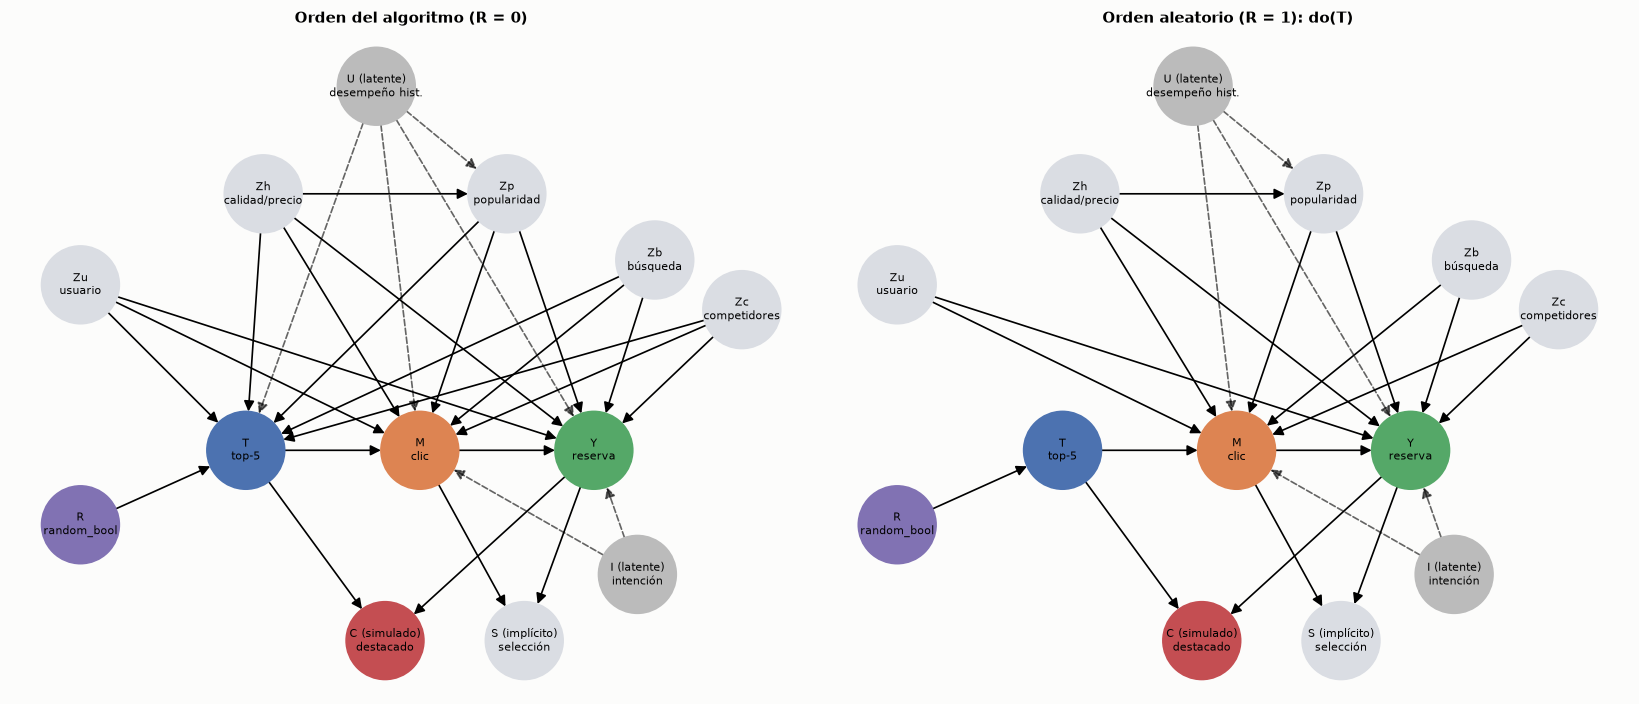

,grafo,conjunto de ajuste,cumple Backdoor
0,Algoritmo (R=0),∅ (ingenuo),False
1,Algoritmo (R=0),Z observado,False
2,Algoritmo (R=0),Z ∪ {U} (hipotético),True
3,Algoritmo (R=0),Z ∪ {M} (trampa del mediador),False
4,Algoritmo (R=0),Z ∪ {U} sin Zc,False
5,Aleatorio (R=1),∅,True
6,Aleatorio (R=1),{S} (selección del dataset),False
7,Aleatorio (R=1),{C} (colisionador simulado),False


In [48]:
import logging

from scipy.special import expit
from sklearn.exceptions import ConvergenceWarning

from tpi.causal import (
    efecto_marginal_real,
    logit_condicional,
    lpm_efectos_fijos,
    modelo_dowhy,
    simular_colisionador,
    simular_listas,
)
from tpi.dag import CONFUSORES, a_dot, construir_dag, cumple_backdoor, dibujar_dag

g_alg, g_rand = construir_dag("algoritmo"), construir_dag("aleatorio")
Zs = set(CONFUSORES)
pruebas_bd = pd.DataFrame(
    [
        ("Algoritmo (R=0)", "∅ (ingenuo)", cumple_backdoor(g_alg, "T", "Y", set())),
        ("Algoritmo (R=0)", "Z observado", cumple_backdoor(g_alg, "T", "Y", Zs)),
        ("Algoritmo (R=0)", "Z ∪ {U} (hipotético)", cumple_backdoor(g_alg, "T", "Y", Zs | {"U"})),
        (
            "Algoritmo (R=0)",
            "Z ∪ {M} (trampa del mediador)",
            cumple_backdoor(g_alg, "T", "Y", Zs | {"M", "U"}),
        ),
        (
            "Algoritmo (R=0)",
            "Z ∪ {U} sin Zc",
            cumple_backdoor(g_alg, "T", "Y", (Zs - {"Zc"}) | {"U"}),
        ),
        ("Aleatorio (R=1)", "∅", cumple_backdoor(g_rand, "T", "Y", set())),
        (
            "Aleatorio (R=1)",
            "{S} (selección del dataset)",
            cumple_backdoor(g_rand, "T", "Y", {"S"}),
        ),
        (
            "Aleatorio (R=1)",
            "{C} (colisionador simulado)",
            cumple_backdoor(g_rand, "T", "Y", {"C"}),
        ),
    ],
    columns=["grafo", "conjunto de ajuste", "cumple Backdoor"],
)
fig, ax = plt.subplots(1, 2, figsize=(15, 6.5))
dibujar_dag(g_alg, ax[0], "Orden del algoritmo (R = 0)")
dibujar_dag(g_rand, ax[1], "Orden aleatorio (R = 1): do(T)")
fig.tight_layout()
gr.guardar(fig, "f4_dag")
plt.show()
pruebas_bd

**Variables del ajuste** (expansión de los nodos de $Z$ a columnas). En las estimaciones **dentro
de la búsqueda** (efectos fijos, logit condicional) las variables de búsqueda y usuario ($Z_b$,
$Z_u$) son constantes en cada lista: quedan absorbidas por el efecto fijo, junto con todo confusor
de nivel búsqueda, observado o no (intención de la sesión, destino, fecha).

In [49]:
Z_HOTEL = [
    "prop_starrating", "prop_review_score", "sin_resenas", "prop_location_score1", "prop_location_score2",
    "prop_location_score2_faltante", "prop_brand_bool", "log_precio_rel", "promotion_flag",
    "prop_log_historical_price", "sin_historial_precio", "con_afinidad", "comp_n_info", "comp_saldo",
]  # fmt: skip
Z_BUSQ = [
    "srch_length_of_stay",
    "srch_booking_window",
    "srch_adults_count",
    "srch_children_count",
    "srch_room_count",
    "srch_saturday_night_bool",
    "usuario_recurrente",
]
# log_precio solo en el ajuste agrupado: dentro de la búsqueda es casi colineal con log_precio_rel
# (difieren en la mediana de la lista, que absorbe el efecto fijo; ia_log, error 27)
Z_TODAS = Z_HOTEL + ["log_precio"] + Z_BUSQ
dc = df.copy()
dc["comp_saldo"] = dc["comp_saldo"].fillna(0.0)
R0, R1 = dc[dc.random_bool == 0], dc[dc.random_bool == 1]
print(
    f"R = 0: {len(R0):,} filas, {R0.srch_id.nunique():,} búsquedas | R = 1: {len(R1):,} filas, {R1.srch_id.nunique():,} búsquedas"
)

R = 0: 376,197 filas, 15,000 búsquedas | R = 1: 363,126 filas, 15,000 búsquedas


## 4.2 Flujo DoWhy en 4 pasos (orden del algoritmo, R = 0)

**Model** (DAG con columnas reales y el clic como mediador) → **Identify** (Backdoor) →
**Estimate** (regresión lineal con ajuste y ponderación por propensión inversa) → **Refute**
(sección 4.6). El efecto es una diferencia de probabilidades (escala absoluta); su
comparabilidad entre estratos está limitada por la selección del dataset (Entrada 4, amenaza A).

In [50]:
modelo0, estimando0 = modelo_dowhy(R0, "top5", "booking_bool", Z_TODAS, "click_bool")
print(estimando0)

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
   d                                                                           ↪
───────(E[booking_bool|sin_historial_precio,prop_location_score2,usuario_recur ↪
d[top₅]                                                                        ↪

↪                                                                              ↪
↪ rente,prop_log_historical_price,srch_children_count,prop_brand_bool,promotio ↪
↪                                                                              ↪

↪                                                                              ↪
↪ n_flag,sin_resenas,srch_length_of_stay,srch_adults_count,con_afinidad,prop_r ↪
↪                                                                              ↪

↪                                                                              ↪
↪ eview_score,prop_starrating,comp_n_info,srch_saturday_night_bool,log_precio_

In [51]:
ate = {}
for nombre, d in [("R = 0 (algoritmo)", R0), ("R = 1 (aleatorio)", R1)]:
    mod, est = (
        (modelo0, estimando0)
        if d is R0
        else modelo_dowhy(d, "top5", "booking_bool", Z_TODAS, "click_bool")
    )
    ing = smf.ols("booking_bool ~ top5", d).fit(
        cov_type="cluster", cov_kwds={"groups": d["srch_id"]}
    )
    lin = mod.estimate_effect(est, "backdoor.linear_regression", confidence_intervals=True)
    # Modelo de propensión escalado: el logit por defecto de DoWhy no converge con covariables en
    # escalas muy distintas (ia_log, error 29). Se exige convergencia.
    with warnings.catch_warnings(record=True) as avisos_ps:
        warnings.simplefilter("always", ConvergenceWarning)
        ipw = mod.estimate_effect(
            est,
            "backdoor.propensity_score_weighting",
            method_params={
                "weighting_scheme": "ips_weight",
                "propensity_score_model": make_pipeline(
                    StandardScaler(), LogisticRegression(max_iter=3000)
                ),
            },
        )
    assert not any(issubclass(a.category, ConvergenceWarning) for a in avisos_ps), (
        "propensión sin converger"
    )
    ate[nombre] = {
        "ingenuo (Y ~ T)": ing.params["top5"],
        "ingenuo IC95": tuple(ing.conf_int().loc["top5"].round(4)),
        "regresión backdoor": lin.value,
        "regresión IC95": tuple(np.round(lin.get_confidence_intervals()[0], 4)),
        "IPW": ipw.value,
        "tasa base P(Y|T=0)": d.loc[d.top5 == 0, "booking_bool"].mean(),
    }
    if d is R0:
        est_lin0, est_ipw0 = lin, ipw
tabla_ate = pd.DataFrame(ate).T
tabla_ate["sesgo de confusión (ingenuo − regresión)"] = (
    tabla_ate["ingenuo (Y ~ T)"] - tabla_ate["regresión backdoor"]
)
tabla_ate["sesgo relativo %"] = (
    100 * tabla_ate["sesgo de confusión (ingenuo − regresión)"] / tabla_ate["regresión backdoor"]
)
tabla_ate

,ingenuo (Y ~ T),ingenuo IC95,regresión backdoor,regresión IC95,IPW,tasa base P(Y|T=0),sesgo de confusión (ingenuo − regresión),sesgo relativo %
R = 0 (algoritmo),0.1055,"(0.1032, 0.1078)",0.0961,"(0.0944, 0.0978)",0.089,0.0206,0.0094,9.7451
R = 1 (aleatorio),0.0105,"(0.0096, 0.0115)",0.0092,"(0.0086, 0.0099)",0.0079,0.0037,0.0013,14.5225


**Lectura.** El estimando identificado es Backdoor con $Z$ (DoWhy excluye el clic porque es mediador).
Con el orden del algoritmo, la diferencia ingenua (0,1055) baja a 0,0961 con regresión y a 0,0890
con IPW (propensión escalada y con convergencia verificada): el ajuste por $Z$ remueve ≈ 9 %
(regresión) y ≈ 16 % (IPW) del coeficiente ingenuo. La
**dirección** del sesgo es la esperada: el algoritmo pone arriba a hoteles que se reservarían igual,
así que la comparación ingenua sobreestima.

Las magnitudes absolutas de R = 0 y R = 1 **no son comparables**: la tasa base es 0,0206 contra
0,0037 porque el proveedor sobremuestreó búsquedas con compra solo en R = 0 (Entrada 4, amenaza A).
Además, el ajuste agrupado no controla los confusores de nivel búsqueda. Por eso la comparación
principal es la de 4.3.

## 4.2 bis Positividad, overlap e IPW recortado

El IPW identifica $\tau$ solo si todo hotel tiene probabilidad positiva de recibir cada nivel del
tratamiento: $0 < e(z) = P(T=1 \mid Z=z) < 1$ (**positividad**). Con propensiones cercanas a 0 o
a 1, los pesos $1/\hat e$ y $1/(1-\hat e)$ explotan y unos pocos hoteles dominan la estimación.
Diagnosticamos el overlap con la distribución de $\hat e$ por grupo, la fracción de unidades
fuera de $[0{,}01;\,0{,}99]$, el peso máximo y el tamaño efectivo de Kish,
$\mathrm{ESS} = (\sum_i w_i)^2/\sum_i w_i^2$.

Usamos el estimador normalizado de Hájek,

$$\hat\tau_{\text{IPW}} = \frac{\sum_i T_i Y_i/\hat e_i}{\sum_i T_i/\hat e_i}
  - \frac{\sum_i (1-T_i)\,Y_i/(1-\hat e_i)}{\sum_i (1-T_i)/(1-\hat e_i)},$$

con la misma propensión que DoWhy (logística escalada sobre $Z$). Como resguardo, **excluimos** las
unidades con $\hat e \notin [0{,}01;\,0{,}99]$ (Crump et al., 2009) y lo contrastamos con
**truncar** $\hat e$ a ese intervalo; `tests/test_cierre.py` muestra con verdad conocida que truncar
sesga y excluir no. El IC 95 % sale de un bootstrap por búsqueda (B = 1000) con $\hat e$ fijo,
que es conservador (Hirano, Imbens y Ridder, 2003).

In [52]:
from tpi.causal import LIMITES_PS, bootstrap_ipw, diagnostico_overlap, ipw_hajek

propension, filas_ov, filas_ipw = {}, [], []
for nombre, d in [("R = 0 (algoritmo)", R0), ("R = 1 (aleatorio)", R1)]:
    modelo_ps = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    modelo_ps.fit(d[Z_TODAS], d["top5"])
    ps = modelo_ps.predict_proba(d[Z_TODAS])[:, 1]
    y_, t_, g_ = d["booking_bool"].to_numpy(), d["top5"].to_numpy(), d["srch_id"].to_numpy()
    propension[nombre] = (ps, t_)
    filas_ov.append({"estrato": nombre} | diagnostico_overlap(ps, t_))
    filas_ipw.append({"estrato": nombre, "estimador": "IPW de DoWhy", "ATE": ate[nombre]["IPW"]})
    for variante, kw in [
        ("IPW Hájek", {}),
        ("IPW Hájek, excluye ê fuera de [0,01; 0,99]", {"limites": LIMITES_PS}),
    ]:
        filas_ipw.append(
            {"estrato": nombre, "estimador": variante}
            | bootstrap_ipw(y_, t_, ps, g_, B=1000, seed=SEED, **kw)
        )
    filas_ipw.append(
        {
            "estrato": nombre,
            "estimador": "IPW Hájek, ê truncado a [0,01; 0,99]",
            "ATE": ipw_hajek(y_, t_, ps, limites=LIMITES_PS, modo="truncar"),
        }
    )
tabla_overlap = pd.DataFrame(filas_ov).set_index("estrato")
tabla_ipw = pd.DataFrame(filas_ipw).set_index(["estrato", "estimador"])
tabla_overlap.T.round(4)

estrato,R = 0 (algoritmo),R = 1 (aleatorio)
ps_p01_T1,0.0366,0.0613
ps_p99_T1,0.6974,0.4786
ps_p01_T0,0.0261,0.0561
ps_p99_T0,0.4712,0.3423
pct_fuera_T1,0.0017,0.0000
pct_fuera_T0,0.0098,0.0000
peso_max,119.9553,30.8771
ess_T1,35929.4113,50156.0625
ess_T0,308341.2475,301424.6902
n_T1,60265.0000,59864.0000


In [53]:
tabla_ipw.round(4)

ATE  \
estrato           estimador                                            
R = 0 (algoritmo) IPW de DoWhy                                0.0890   
                  IPW Hájek                                   0.0882   
                  IPW Hájek, excluye ê fuera de [0,01; 0,99]  0.0882   
                  IPW Hájek, ê truncado a [0,01; 0,99]        0.0882   
R = 1 (aleatorio) IPW de DoWhy                                0.0079   
                  IPW Hájek                                   0.0078   
                  IPW Hájek, excluye ê fuera de [0,01; 0,99]  0.0078   
                  IPW Hájek, ê truncado a [0,01; 0,99]        0.0078   

                                                              IC95_inf  \
estrato           estimador                                              
R = 0 (algoritmo) IPW de DoWhy                                     NaN   
                  IPW Hájek                                     0.0854   
                  IPW Hájek, excluye ê fuera de [0,01; 0,99]    0.0854   
                  IPW Hájek, ê truncado a [0,01; 0,99]             NaN   
R = 1 (aleatorio) IPW de DoWhy                                     NaN   
                  IPW Hájek                                     0.0069   
                  IPW Hájek, excluye ê fuera de [0,01; 0,99]    0.0069   
                  IPW Hájek, ê truncado a [0,01; 0,99]             NaN   

                                                              IC95_sup  \
estrato           estimador                                              
R = 0 (algoritmo) IPW de DoWhy                                     NaN   
                  IPW Hájek                                     0.0909   
                  IPW Hájek, excluye ê fuera de [0,01; 0,99]    0.0910   
                  IPW Hájek, ê truncado a [0,01; 0,99]             NaN   
R = 1 (aleatorio) IPW de DoWhy                                     NaN   
                  IPW Hájek                                     0.0088   
                  IPW Hájek, excluye ê fuera de [0,01; 0,99]    0.0088   
                  IPW Hájek, ê truncado a [0,01; 0,99]             NaN   

                                                              ee_bootstrap  \
estrato           estimador                                                  
R = 0 (algoritmo) IPW de DoWhy                                         NaN   
                  IPW Hájek                                         0.0014   
                  IPW Hájek, excluye ê fuera de [0,01; 0,99]        0.0014   
                  IPW Hájek, ê truncado a [0,01; 0,99]                 NaN   
R = 1 (aleatorio) IPW de DoWhy                                         NaN   
                  IPW Hájek                                         0.0005   
                  IPW Hájek, excluye ê fuera de [0,01; 0,99]        0.0005   
                  IPW Hájek, ê truncado a [0,01; 0,99]                 NaN   

                                                                   B  
estrato           estimador                                           
R = 0 (algoritmo) IPW de DoWhy                                   NaN  
                  IPW Hájek                                   1000.0  
                  IPW Hájek, excluye ê fuera de [0,01; 0,99]  1000.0  
                  IPW Hájek, ê truncado a [0,01; 0,99]           NaN  
R = 1 (aleatorio) IPW de DoWhy                                   NaN  
                  IPW Hájek                                   1000.0  
                  IPW Hájek, excluye ê fuera de [0,01; 0,99]  1000.0  
                  IPW Hájek, ê truncado a [0,01; 0,99]           NaN

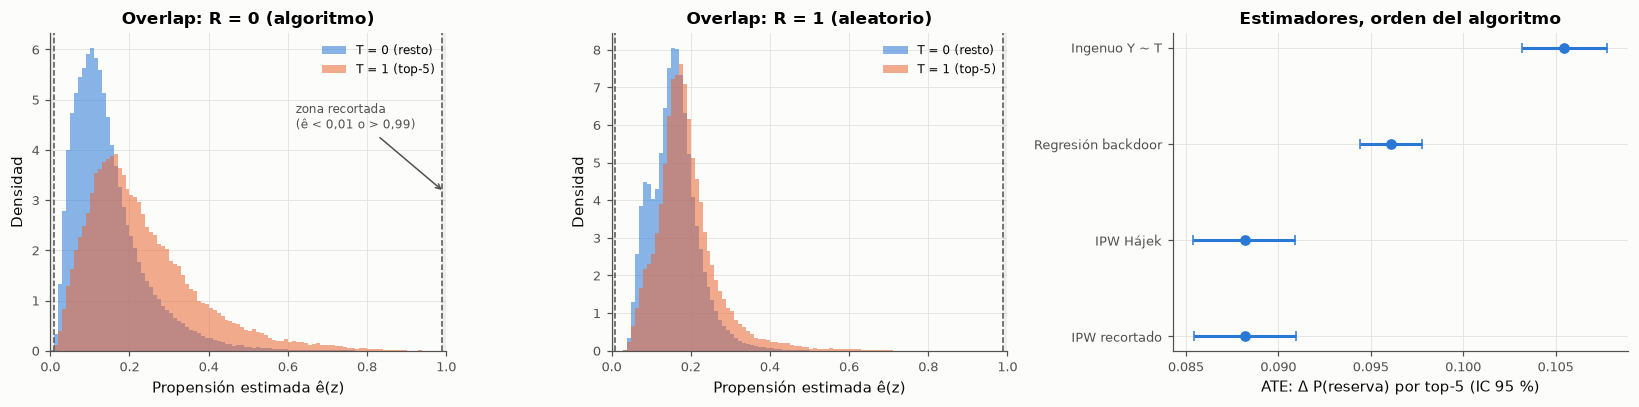

In [54]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1, 1, 1.15]})
bins = np.linspace(0, 1, 101)
for a, (nombre, (ps, t_)) in zip(ax[:2], propension.items(), strict=True):
    a.hist(ps[t_ == 0], bins=bins, density=True, alpha=0.55, color=gr.AZUL, label="T = 0 (resto)")
    a.hist(
        ps[t_ == 1], bins=bins, density=True, alpha=0.55, color=gr.NARANJA, label="T = 1 (top-5)"
    )
    for lim in LIMITES_PS:
        a.axvline(lim, color=gr.TEXTO_2, ls="--", lw=1)
    a.axvspan(0, LIMITES_PS[0], color=gr.TEXTO_2, alpha=0.08, lw=0)
    a.axvspan(LIMITES_PS[1], 1, color=gr.TEXTO_2, alpha=0.08, lw=0)
    a.set(
        xlabel="Propensión estimada ê(z)",
        ylabel="Densidad",
        title=f"Overlap: {nombre}",
        xlim=(0, 1),
    )
    a.legend(fontsize=8, frameon=False)
ax[0].annotate(
    "zona recortada\n(ê < 0,01 o > 0,99)",
    xy=(0.995, ax[0].get_ylim()[1] * 0.5),
    xytext=(0.62, ax[0].get_ylim()[1] * 0.7),
    fontsize=8,
    color=gr.TEXTO_2,
    arrowprops={"arrowstyle": "->", "color": gr.TEXTO_2},
)
r0 = "R = 0 (algoritmo)"
puntos = [
    ("Ingenuo Y ~ T", ate[r0]["ingenuo (Y ~ T)"], *ate[r0]["ingenuo IC95"]),
    ("Regresión backdoor", ate[r0]["regresión backdoor"], *ate[r0]["regresión IC95"]),
    ("IPW Hájek", *tabla_ipw.loc[(r0, "IPW Hájek"), ["ATE", "IC95_inf", "IC95_sup"]]),
    (
        "IPW recortado",
        *tabla_ipw.loc[
            (r0, "IPW Hájek, excluye ê fuera de [0,01; 0,99]"), ["ATE", "IC95_inf", "IC95_sup"]
        ],
    ),
]
for i, (_lab, est, lo, hi) in enumerate(puntos):
    ax[2].errorbar(est, i, xerr=[[est - lo], [hi - est]], fmt="o", color=gr.AZUL, capsize=3)
ax[2].set_yticks(range(len(puntos)), [p[0] for p in puntos])
ax[2].invert_yaxis()
ax[2].set(xlabel="ATE: Δ P(reserva) por top-5 (IC 95 %)", title="Estimadores, orden del algoritmo")
fig.tight_layout()
gr.guardar(fig, "f4_overlap")
plt.show()

**Lectura.**
- **Positividad: se cumple en los dos estratos.** Las propensiones del top-5 y del resto se
  superponen en todo su rango y casi ninguna unidad cae fuera de $[0{,}01;\,0{,}99]$, así que el
  IPW recortado coincide con el completo. Con orden aleatorio, las distribuciones de los dos grupos
  casi coinciden: $Z$ apenas predice la exposición, que es la huella de la aleatorización.
- **Pesos.** Con el orden del algoritmo, el peso máximo y la caída del tamaño efectivo del grupo
  tratado muestran que $Z$ predice más la exposición: el ranker usa esas variables.
- **Estimadores.** El IPW de Hájek queda del mismo lado que la regresión backdoor respecto del
  ingenuo: ajustar por $Z$ reduce el efecto aparente. El IPW de DoWhy difiere del de Hájek recién en
  la cuarta cifra (otra normalización de los pesos), no en la identificación.
- **Límite.** Un buen overlap en $Z$ no protege contra $U$: ningún reponderado por lo observado
  corrige la confusión que revela el benchmark (4.3).

## 4.3 Escala relativa dentro de la búsqueda: observacional vs. cuasi-experimento

**Estimador principal** (decisión del 12/11): **logit condicional** por búsqueda,
$P(Y_{is}=1 \mid \textstyle\sum_i Y_{is}, X) = \frac{\exp(\tau T_{is} + Z_{is}^\top\gamma)}{\sum_{j \in s}\exp(\tau T_{js} + Z_{js}^\top\gamma)}$,
un modelo de elección: "dado que en esta lista hubo una reserva, ¿cuánto aumenta el top-5 la
chance de que sea este hotel?". $e^\tau$ es un **OR intra-búsqueda**, invariante a la selección
de listas por su resultado (`tests/test_causal.py::test_or_condicional_sobrevive_al_filtro_de_seleccion`).

* **Benchmark (R = 1):** orden (casi) aleatorio. Se informa sin ajuste y ajustado por $Z$ por la
  aleatorización imperfecta (Entrada 4, amenaza B).
* **Observacional (R = 0):** sin ajuste (ingenuo) y ajustado por $Z$ (Backdoor).
* Como escala absoluta, el MPL con efectos fijos por búsqueda.

In [55]:
filas_rel = []
for estrato, d in [("R = 0 (algoritmo)", R0), ("R = 1 (aleatorio)", R1)]:
    for ajuste, cov in [("sin ajuste", []), ("ajustado por Z", Z_HOTEL)]:
        cl = logit_condicional(d, "top5", "booking_bool", cov)
        fe = lpm_efectos_fijos(d, "top5", "booking_bool", cov)
        filas_rel.append(
            {
                "estrato": estrato,
                "ajuste": ajuste,
                "OR intra": cl.estimacion,
                "OR IC95": tuple(np.round(cl.ic95, 3)),
                "p": cl.p_valor,
                "búsquedas informativas": cl.n,
                "MPL-EF (Δp)": fe.estimacion,
                "Δp IC95": tuple(np.round(fe.ic95, 4)),
            }
        )
tabla_rel = pd.DataFrame(filas_rel).set_index(["estrato", "ajuste"])
or_ = tabla_rel["OR intra"]
or_ing0, or_adj0 = (
    or_[("R = 0 (algoritmo)", "sin ajuste")],
    or_[("R = 0 (algoritmo)", "ajustado por Z")],
)
or_bench = or_[("R = 1 (aleatorio)", "ajustado por Z")]
brecha = np.log(or_ing0 / or_bench)
print(f"Brecha total en log-OR (ingenuo R=0 vs. benchmark R=1 ajustado): {brecha:.3f}")
print(
    f"  explicada por Z observado: {np.log(or_ing0 / or_adj0):.3f} ({100 * np.log(or_ing0 / or_adj0) / brecha:.1f} %)"
)
print(
    f"  residual (compatible con confusión no observada U): {np.log(or_adj0 / or_bench):.3f} ({100 * np.log(or_adj0 / or_bench) / brecha:.1f} %)"
)
print(
    f"  el estimador observacional ajustado sobrestima el OR en un {100 * (or_adj0 / or_bench - 1):.1f} %"
)
sens_t = logit_condicional(R1, "top4_dataset", "booking_bool", Z_HOTEL)
print(
    f"Sensibilidad T = top4_dataset (R = 1, ajustado): OR = {sens_t.estimacion:.3f} IC95 [{sens_t.ic95[0]:.3f}; {sens_t.ic95[1]:.3f}]"
)
tabla_rel

Brecha total en log-OR (ingenuo R=0 vs. benchmark R=1 ajustado): 0.935
  explicada por Z observado: 0.466 (49.8 %)
  residual (compatible con confusión no observada U): 0.469 (50.2 %)
  el estimador observacional ajustado sobrestima el OR en un 59.9 %


Sensibilidad T = top4_dataset (R = 1, ajustado): OR = 2.128 IC95 [1.909; 2.372]


OR intra         OR IC95            p  \
estrato           ajuste                                                  
R = 0 (algoritmo) sin ajuste        5.3825  (5.196, 5.576)   0.0000e+00   
                  ajustado por Z    3.3778  (3.242, 3.519)   0.0000e+00   
R = 1 (aleatorio) sin ajuste        3.0019  (2.717, 3.316)  8.8987e-104   
                  ajustado por Z    2.1124  (1.895, 2.355)   1.7422e-41   

                                  búsquedas informativas  MPL-EF (Δp)  \
estrato           ajuste                                                
R = 0 (algoritmo) sin ajuste                       14124       0.0973   
                  ajustado por Z                   14124       0.0778   
R = 1 (aleatorio) sin ajuste                        1971       0.0085   
                  ajustado por Z                    1971       0.0064   

                                           Δp IC95  
estrato           ajuste                            
R = 0 (algoritmo) sin ajuste      (0.0949, 0.0997)  
                  ajustado por Z  (0.0753, 0.0803)  
R = 1 (aleatorio) sin ajuste      (0.0075, 0.0094)  
                  ajustado por Z  (0.0055, 0.0074)

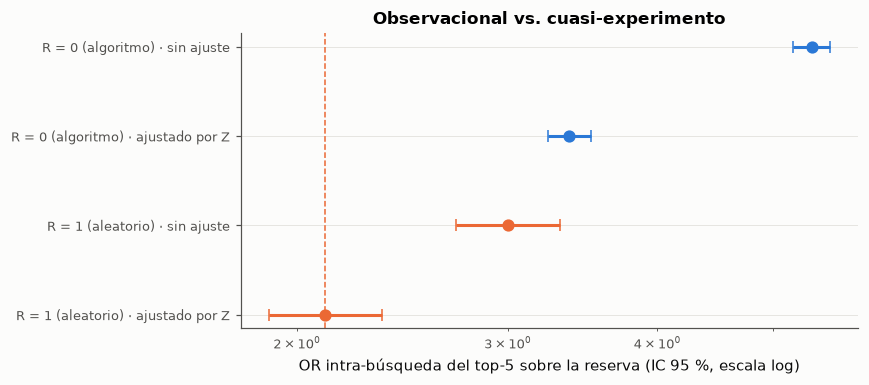

In [56]:
fig, ax = plt.subplots(figsize=(8, 3.6))
etiquetas = [f"{e} · {a}" for e, a in tabla_rel.index]
y_pos = np.arange(len(tabla_rel))[::-1]
for yy, (idx, fila) in zip(y_pos, tabla_rel.iterrows(), strict=True):
    color = gr.AZUL if idx[0].startswith("R = 0") else gr.NARANJA
    ax.errorbar(
        fila["OR intra"],
        yy,
        xerr=[[fila["OR intra"] - fila["OR IC95"][0]], [fila["OR IC95"][1] - fila["OR intra"]]],
        fmt="o",
        color=color,
        capsize=4,
        ms=7,
    )
ax.axvline(or_bench, color=gr.NARANJA, ls="--", lw=1)
ax.annotate(
    "benchmark (R = 1 ajustado)",
    xy=(or_bench, y_pos[0] + 0.35),
    xytext=(6, 0),
    textcoords="offset points",
    fontsize=8,
    color=gr.TEXTO_2,
)
ax.set(
    yticks=y_pos,
    yticklabels=etiquetas,
    xscale="log",
    xlabel="OR intra-búsqueda del top-5 sobre la reserva (IC 95 %, escala log)",
    title="Observacional vs. cuasi-experimento",
)
fig.tight_layout()
gr.guardar(fig, "f4_or_comparacion")
plt.show()

**Resultado central del TP.**

| | OR intra-búsqueda (IC 95 %) |
|---|---|
| Orden del algoritmo, ingenuo | 5,38 |
| Orden del algoritmo, ajustado por $Z$ | 3,38 |
| **Orden aleatorio, ajustado (benchmark)** | **2,11** |
| Orden aleatorio, sin ajuste | 3,00 |

(IC 95 % sándwich por búsqueda en la tabla de arriba.)

1. **El top-5 tiene efecto causal:** con orden aleatorio, estar en el top-5 multiplica por 2,11 las
   chances de que el hotel sea el reservado de su lista; el IC excluye 1.
2. **El estimador observacional sobreestima, aun ajustado.** Ajustar por $Z$ cierra la mitad de la
   brecha en log-odds (salida de arriba), pero el OR observacional ajustado sigue un 60 % por encima
   del benchmark. **Los datos son incompatibles con que el ajuste por lo observable elimine el
   sesgo** de selección del algoritmo. Es lo que anticipa el DAG ($Z$ no bloquea
   $T \leftarrow U \to Y$). La sección 4.3 bis somete esta conclusión a cuatro pruebas.
3. **Candidatos concretos de confusión no observada ($U$)**, es decir, señales que un ranker de
   hoteles en producción usa y este dataset no expone:
   - la tasa histórica de clic y de conversión del hotel en Expedia, por destino;
   - el margen o la comisión que Expedia cobra a cada hotel (incluidos acuerdos de visibilidad);
   - la disponibilidad y el inventario en tiempo real;
   - la calidad del contenido de la ficha (fotos, descripción);
   - el comportamiento previo del usuario en la misma sesión (clics y búsquedas anteriores).

   Todas afectan a la vez la posición y la reserva.
4. Con orden aleatorio, ajustar por $Z$ también baja el OR (de 3,00 a 2,11), por la aleatorización
   imperfecta (amenaza B): por eso el benchmark es el ajustado.
5. La sensibilidad con $T$ = top-4 del dataset (salida de arriba) no cambia la conclusión.

## 4.3 bis Robustez de la conclusión central

Cuatro objeciones posibles a "el observacional ajustado sobreestima el efecto causal", y cómo las
contrastamos:

* **(a) ¿Diferencia de población, no de confusión?** Si las búsquedas con orden aleatorio y las del
  algoritmo tuvieran distinta composición, la brecha podría venir de efectos distintos en
  poblaciones distintas. Medimos el balance con la **diferencia de medias estandarizada** (SMD) de
  covariables de búsqueda y de composición de la lista, sobre las búsquedas que realmente entran
  al estimador (las que tienen reserva). Después **re-ponderamos** la muestra del algoritmo a la
  distribución de la aleatoria con pesos de odds, $w = \hat P(R=1\mid X)/\hat P(R=0\mid X)$, y
  recalculamos.
* **(b) ¿No colapsabilidad del OR?** El OR condicional cambia con el conjunto de ajuste aunque no
  haya sesgo. Repetimos la comparación en **escala de diferencia de riesgos**, que sí es colapsable:
  (i) el **efecto marginal promedio** del logit de elección, $\frac1N\sum_i [P_i(T_i=1) - P_i(T_i=0)]$
  con el resto de la lista fijo; (ii) el MPL con efectos fijos. Restringidos a búsquedas con una
  reserva, la tasa base es comparable entre estratos (≈ 1/largo de la lista), así que la escala
  absoluta también es comparable.
* **(c) ¿Es significativa la brecha?** Test de Wald de $H_0: \log \mathrm{OR}_{R=0} = \log \mathrm{OR}_{R=1}$
  (muestras independientes), e **IC 95 % percentil por bootstrap clusterizado por búsqueda**
  (**1000 réplicas**: búsquedas completas remuestreadas con reposición en cada estrato, pesos de
  balance re-estimados en cada réplica, paralelizado en 24 núcleos con `joblib`, sin submuestreo).
  Se obtienen los OR de cada estrato y su cociente, los efectos marginales (cociente y
  diferencia) y la diferencia de riesgos con efectos fijos.

In [57]:
from tpi.causal import (
    bootstrap_brecha,
    efecto_marginal_eleccion,
    eleccion_logit,
    pesos_odds_busqueda,
    smd,
)

informativas = dc[dc.groupby("srch_id")["booking_bool"].transform("sum") == 1].copy()
g_inf = informativas.groupby("srch_id")
informativas["largo_lista"] = g_inf["prop_id"].transform("size")
for nueva, base in [
    ("estrellas_media", "prop_starrating"), ("resenas_media", "prop_review_score"), ("ubic2_media", "prop_location_score2"),
    ("log_precio_medio", "log_precio"), ("promo_share", "promotion_flag"), ("marca_share", "prop_brand_bool"),
    ("comp_info_media", "comp_n_info"), ("log_hist_medio", "prop_log_historical_price"),
]:  # fmt: skip
    informativas[nueva] = g_inf[base].transform("mean")
informativas["sitio_principal"] = (
    informativas["site_id"] == informativas["site_id"].mode()[0]
).astype(int)
informativas["pais_usuario_principal"] = (
    informativas["visitor_location_country_id"]
    == informativas["visitor_location_country_id"].mode()[0]
).astype(int)
COLS_BUSQ = [
    "largo_lista", "srch_length_of_stay", "srch_booking_window", "srch_adults_count", "srch_children_count",
    "srch_room_count", "srch_saturday_night_bool", "usuario_recurrente", "sitio_principal", "pais_usuario_principal",
    "estrellas_media", "resenas_media", "ubic2_media", "log_precio_medio", "promo_share", "marca_share",
    "comp_info_media", "log_hist_medio",
]  # fmt: skip
I0, I1 = informativas[informativas.random_bool == 0], informativas[informativas.random_bool == 1]
s0b, s1b = I0.groupby("srch_id")[COLS_BUSQ].first(), I1.groupby("srch_id")[COLS_BUSQ].first()
w_bal = pesos_odds_busqueda(s0b, s1b, COLS_BUSQ)
ess = w_bal.sum() ** 2 / (w_bal**2).sum()
balance = pd.DataFrame(
    {
        "media R=0": s0b.mean(),
        "media R=1": s1b.mean(),
        "SMD sin ponderar": [smd(s0b[c], s1b[c]) for c in COLS_BUSQ],
        "SMD ponderado": [smd(s0b[c], s1b[c], w_bal.to_numpy()) for c in COLS_BUSQ],
    }
)
print(
    f"Búsquedas con reserva: R=0 {len(s0b):,}, R=1 {len(s1b):,} | tamaño efectivo de R=0 ponderado: {ess:,.0f} | peso máx. {w_bal.max():.2f}"
)
print(
    f"|SMD| máx.: sin ponderar {balance['SMD sin ponderar'].abs().max():.3f}, ponderado {balance['SMD ponderado'].abs().max():.3f}"
)
balance.round(3)

Búsquedas con reserva: R=0 14,124, R=1 1,971 | tamaño efectivo de R=0 ponderado: 12,938 | peso máx. 3.43
|SMD| máx.: sin ponderar 0.248, ponderado 0.005


,media R=0,media R=1,SMD sin ponderar,SMD ponderado
largo_lista,25.061,23.516,0.166,-0.005
srch_length_of_stay,2.092,2.086,0.004,0.000
srch_booking_window,32.529,31.292,0.026,-0.001
srch_adults_count,1.952,1.933,0.022,-0.001
srch_children_count,0.361,0.361,0.001,0.000
srch_room_count,1.134,1.145,-0.024,0.001
srch_saturday_night_bool,0.512,0.530,-0.036,-0.001
usuario_recurrente,0.064,0.064,-0.001,-0.001
sitio_principal,0.624,0.639,-0.031,0.001
pais_usuario_principal,0.587,0.593,-0.011,0.001


In [58]:
filas_rob = []
for nombre, pesos in [("sin ponderar", None), ("R=0 ponderado a la composición de R=1", w_bal)]:
    a0 = eleccion_logit(I0, "top5", "booking_bool", Z_HOTEL, pesos_grupo=pesos)
    a1 = eleccion_logit(I1, "top5", "booking_bool", Z_HOTEL)
    dlog, ee = a0.params["top5"] - a1.params["top5"], np.hypot(a0.ee["top5"], a1.ee["top5"])
    ame0 = efecto_marginal_eleccion(I0, "top5", "booking_bool", Z_HOTEL, pesos_grupo=pesos)
    ame1 = efecto_marginal_eleccion(I1, "top5", "booking_bool", Z_HOTEL)
    filas_rob.append(
        {
            "especificación": nombre, "OR R=0": np.exp(a0.params["top5"]), "OR R=1": np.exp(a1.params["top5"]),
            "cociente OR": np.exp(dlog), "Wald z": dlog / ee, "p (Wald)": 2 * stats.norm.sf(abs(dlog / ee)),
            "AME R=0 (p.p.)": 100 * ame0, "AME R=1 (p.p.)": 100 * ame1, "cociente AME": ame0 / ame1, "diferencia AME (p.p.)": 100 * (ame0 - ame1),
        }
    )  # fmt: skip
fe_i0, fe_i1 = (
    lpm_efectos_fijos(I0, "top5", "booking_bool", Z_HOTEL),
    lpm_efectos_fijos(I1, "top5", "booking_bool", Z_HOTEL),
)
tabla_rob = pd.DataFrame(filas_rob).set_index("especificación")
print(
    f"MPL con efectos fijos (búsquedas con reserva): R=0 Δp = {fe_i0.estimacion:.4f} {tuple(np.round(fe_i0.ic95, 4))}, R=1 Δp = {fe_i1.estimacion:.4f} {tuple(np.round(fe_i1.ic95, 4))}, cociente = {fe_i0.estimacion / fe_i1.estimacion:.3f}"
)
print(
    f"Tasa base (búsquedas con reserva): R=0 {I0.booking_bool.mean():.4f}, R=1 {I1.booking_bool.mean():.4f}"
)
tabla_rob.round(4)

MPL con efectos fijos (búsquedas con reserva): R=0 Δp = 0.0826 (0.08, 0.0853), R=1 Δp = 0.0477 (0.0409, 0.0545), cociente = 1.731
Tasa base (búsquedas con reserva): R=0 0.0399, R=1 0.0425


,OR R=0,OR R=1,cociente OR,Wald z,p (Wald),AME R=0 (p.p.),AME R=1 (p.p.),cociente AME,diferencia AME (p.p.)
especificación,,,,,,,,,
sin ponderar,3.3778,2.1124,1.5990,7.9217,0.0,5.3444,3.2408,1.6491,2.1036
R=0 ponderado a la composición de R=1,3.3664,2.1124,1.5936,7.8142,0.0,5.4996,3.2408,1.6970,2.2588


In [59]:
t0 = time.time()
boot = bootstrap_brecha(I0, I1, "top5", "booking_bool", Z_HOTEL, COLS_BUSQ, B=1000, seed=SEED)
ic_boot = boot.quantile([0.025, 0.5, 0.975]).T.rename(
    columns={0.025: "IC95_inf", 0.5: "mediana", 0.975: "IC95_sup"}
)
ic_boot["fracción de réplicas sin sobreestimación"] = [
    (boot[c] <= (0 if c.startswith("diferencia") else 1)).mean()
    if c.startswith(("cociente", "diferencia"))
    else np.nan
    for c in boot.columns
]
print(f"Bootstrap por búsqueda: {len(boot)} réplicas, {time.time() - t0:.0f} s")
ic_boot.round(4)

Bootstrap por búsqueda: 1000 réplicas, 954 s


,IC95_inf,mediana,IC95_sup,fracción de réplicas sin sobreestimación
OR_R0,3.2508,3.3824,3.5196,NaN
OR_R1,1.8952,2.1110,2.3636,NaN
cociente_OR,1.4213,1.6018,1.8025,0.0
cociente_OR_ponderado,1.4181,1.5976,1.7950,0.0
AME_R0,0.0514,0.0535,0.0555,NaN
AME_R1,0.0272,0.0324,0.0378,NaN
cociente_AME,1.4062,1.6525,1.9776,0.0
diferencia_AME,0.0153,0.0210,0.0269,0.0
cociente_AME_ponderado,1.4477,1.7011,2.0336,0.0
DR_EF_R0,0.0801,0.0826,0.0852,NaN


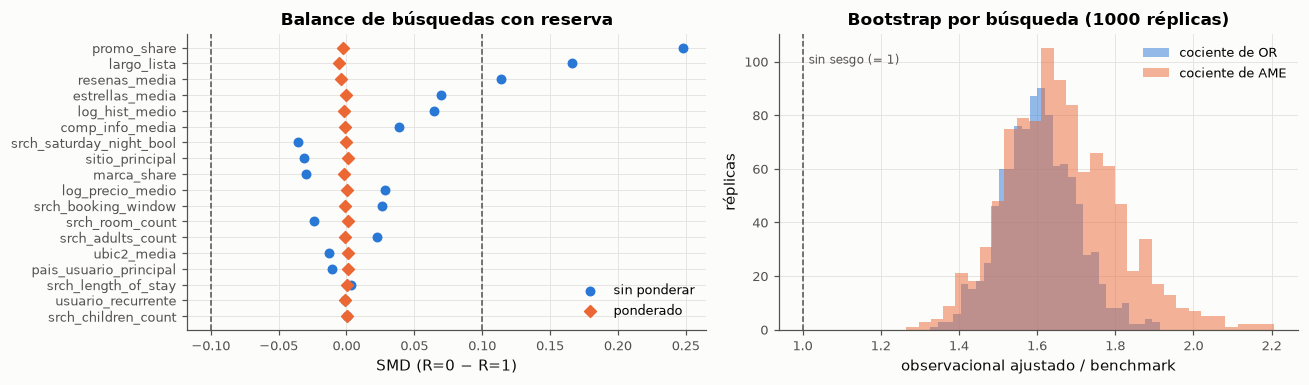

In [60]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
orden = balance["SMD sin ponderar"].abs().sort_values().index
ax[0].scatter(
    balance.loc[orden, "SMD sin ponderar"], orden, color=gr.AZUL, s=30, label="sin ponderar"
)
ax[0].scatter(
    balance.loc[orden, "SMD ponderado"],
    orden,
    color=gr.NARANJA,
    s=30,
    marker="D",
    label="ponderado",
)
for x in (-0.1, 0.1):
    ax[0].axvline(x, color=gr.TEXTO_2, ls="--", lw=1)
ax[0].set(xlabel="SMD (R=0 − R=1)", title="Balance de búsquedas con reserva")
ax[0].legend(loc="lower right")
for c, color, nombre in [
    ("cociente_OR", gr.AZUL, "cociente de OR"),
    ("cociente_AME", gr.NARANJA, "cociente de AME"),
]:
    ax[1].hist(boot[c], bins=30, color=color, alpha=0.5, label=nombre)
ax[1].axvline(1, color=gr.TEXTO_2, ls="--", lw=1)
ax[1].annotate(
    "sin sesgo (= 1)",
    xy=(1, ax[1].get_ylim()[1] * 0.9),
    xytext=(4, 0),
    textcoords="offset points",
    fontsize=8,
    color=gr.TEXTO_2,
)
ax[1].set(
    xlabel="observacional ajustado / benchmark",
    ylabel="réplicas",
    title="Bootstrap por búsqueda (1000 réplicas)",
)
ax[1].legend()
fig.tight_layout()
gr.guardar(fig, "f4_robustez")
plt.show()

**La conclusión resiste las tres objeciones.**

**(a) No es una diferencia de población.** Sobre las 14.124 búsquedas con reserva del algoritmo y
las 1.971 aleatorias, el balance sin ponderar ya es bueno en casi todo: 16 de 18 covariables con
|SMD| < 0,12. Las excepciones son la proporción de hoteles en promoción (0,248) y el largo de la
lista (0,166). Con pesos de odds, la mayor |SMD| baja a 0,005, con un tamaño efectivo de 12.938 y
un peso máximo de 3,43. Re-ponderado, el cociente de OR casi no cambia (1,599 → 1,594).

**(b) No es la no colapsabilidad del OR.** En escala de diferencia de riesgos, colapsable y con tasa
base comparable (0,0399 vs. 0,0425 en búsquedas con reserva):
- el efecto marginal promedio del top-5 es 5,34 p.p. con el algoritmo contra 3,24 p.p. con orden
  aleatorio (cociente 1,65; diferencia 2,10 p.p.);
- el MPL con efectos fijos da 0,0826 contra 0,0477 (cociente 1,73).

**(c) Es significativa y precisa.**
- Test de Wald de la igualdad de log-OR: z = 7,92, p = 2,4·10⁻¹⁵ (5,5·10⁻¹⁵ re-ponderado; la tabla
  redondea a 4 decimales).
- Bootstrap percentil clusterizado por búsqueda, con 1000 réplicas:

| Magnitud | Mediana | IC 95 % |
|---|---|---|
| OR algoritmo ajustado | 3,38 | [3,25; 3,52] |
| OR benchmark (aleatorio, ajustado) | 2,11 | [1,90; 2,36] |
| **Cociente de OR** | **1,60** | **[1,42; 1,80]** |
| Cociente de OR re-ponderado | 1,60 | [1,42; 1,80] |
| Efecto marginal, algoritmo (p.p.) | 5,35 | [5,14; 5,55] |
| Efecto marginal, benchmark (p.p.) | 3,24 | [2,72; 3,78] |
| **Cociente de efectos marginales** | **1,65** | **[1,41; 1,98]** |
| Diferencia de efectos marginales (p.p.) | 2,10 | [1,53; 2,69] |
| Diferencia de riesgos con EF, algoritmo − benchmark | 0,035 | [0,028; 0,042] |

En **ninguna** de las 1000 réplicas el cociente cae a 1 o menos (ni en OR, ni en efecto marginal,
ni en diferencia de riesgos). **Los datos son incompatibles con que el ajuste por las covariables
observadas elimine el sesgo de selección del algoritmo:** el observacional ajustado sobreestima el
efecto causal del top-5 en un 60-65 %, en las dos escalas.

## 4.4 El clic: paso obligatorio del embudo, no mediador sustantivo

En Expedia, `booking_bool = 1` implica `click_bool = 1` (regla verificada en el contrato de
datos): **la reserva sin clic es estructuralmente imposible**. Por eso "ajustar por el clic"
anula el efecto casi por construcción y no es un hallazgo sustantivo de mediación. Lo informativo
es **descomponer** el efecto. Como $Y = 1 \Rightarrow M = 1$, vale la identidad exacta

$$P(Y=1\mid T) = P(M=1\mid T)\cdot P(Y=1\mid M=1, T) \;\Rightarrow\;
  \mathrm{RR}_{Y} = \mathrm{RR}_{\text{clic}} \times \mathrm{RR}_{\text{conversión}\mid \text{clic}}$$

**Método:** proporciones por fila búsqueda × hotel en cada estrato; los IC 95 % son percentiles de
1000 réplicas de bootstrap clusterizado por búsqueda. Con orden aleatorio, $\mathrm{RR}_{\text{clic}}$ es causal. En
cambio, $\mathrm{RR}_{\text{conversión}\mid\text{clic}}$ condiciona en un colisionador
($T \to M \leftarrow I$), así que es **descriptivo**: compara quienes hicieron clic en cada
posición, que no son intercambiables.

In [61]:
def embudo(d: pd.DataFrame) -> dict:
    ctr = d.groupby("top5")["click_bool"].mean()
    conv = d[d.click_bool == 1].groupby("top5")["booking_bool"].mean()
    rr_c, rr_v = ctr[1] / ctr[0], conv[1] / conv[0]
    return {"P(clic|T=1)": ctr[1], "P(clic|T=0)": ctr[0], "RR clic": rr_c, "P(res|clic,T=1)": conv[1], "P(res|clic,T=0)": conv[0],
            "RR conversión|clic": rr_v, "RR reserva": rr_c * rr_v, "% del log-RR vía clic": 100 * np.log(rr_c) / np.log(rr_c * rr_v)}  # fmt: skip


from joblib import Parallel, delayed

rng_e = np.random.default_rng(SEED)
filas_emb, ic_emb = {}, {}
for estrato, d in [("R = 0 (algoritmo)", R0), ("R = 1 (aleatorio)", R1)]:
    filas_emb[estrato] = embudo(d)
    pos = d.groupby("srch_id").indices
    ids = np.array(list(pos))
    sorteos = [rng_e.choice(ids, len(ids)) for _ in range(1000)]
    reps = Parallel(n_jobs=-1)(
        delayed(embudo)(d.iloc[np.concatenate([pos[i] for i in sel])]) for sel in sorteos
    )
    ic_emb[estrato] = pd.DataFrame(reps).quantile([0.025, 0.975])
tabla_emb = pd.DataFrame(filas_emb).T
for estrato in tabla_emb.index:
    for c in ["RR clic", "RR conversión|clic", "RR reserva"]:
        tabla_emb.loc[estrato, f"{c} IC95"] = (
            f"[{ic_emb[estrato].loc[0.025, c]:.3f}; {ic_emb[estrato].loc[0.975, c]:.3f}]"
        )
tabla_emb

,P(clic|T=1),P(clic|T=0),RR clic,"P(res|clic,T=1)","P(res|clic,T=0)",RR conversión|clic,RR reserva,% del log-RR vía clic,RR clic IC95,RR conversión|clic IC95,RR reserva IC95
R = 0 (algoritmo),0.1410,0.0253,5.5771,0.8946,0.8167,1.0953,6.1087,94.969,[5.394; 5.748],[1.079; 1.111],[5.917; 6.309]
R = 1 (aleatorio),0.1042,0.0351,2.9642,0.1366,0.1050,1.3012,3.8571,80.495,[2.874; 3.058],[1.196; 1.413],[3.508; 4.214]


In [62]:
med = {
    "efecto total (ajuste Z)": lpm_efectos_fijos(R0, "top5", "booking_bool", Z_HOTEL),
    "ajustando además por el clic (M)": lpm_efectos_fijos(
        R0, "top5", "booking_bool", Z_HOTEL + ["click_bool"]
    ),
    "solo hoteles clickeados (condicionar en M)": lpm_efectos_fijos(
        R0[R0.click_bool == 1], "top5", "booking_bool", Z_HOTEL
    ),
}
tabla_med = pd.DataFrame(
    {
        k: {"Δp": v.estimacion, "IC95": tuple(np.round(v.ic95, 4)), "p": v.p_valor}
        for k, v in med.items()
    }
).T
solo_clic = R0[R0.click_bool == 1]
dif_conv = (
    solo_clic.loc[solo_clic.top5 == 1, "booking_bool"].mean()
    - solo_clic.loc[solo_clic.top5 == 0, "booking_bool"].mean()
)
print(f"Residual al ajustar por el clic: {med['ajustando además por el clic (M)'].estimacion:.4f}")
print(
    f"Diferencia de conversión entre clickeados (top-5 − resto, R = 0): {dif_conv:.4f} × P(clic) = {dif_conv * R0.click_bool.mean():.4f}"
)
tabla_med

Residual al ajustar por el clic: 0.0042
Diferencia de conversión entre clickeados (top-5 − resto, R = 0): 0.0778 × P(clic) = 0.0034


,Δp,IC95,p
efecto total (ajuste Z),0.0778,"(0.0753, 0.0803)",0.0
ajustando además por el clic (M),0.0042,"(0.0031, 0.0052)",0.0
solo hoteles clickeados (condicionar en M),0.115,"(0.0452, 0.1847)",0.0012


**Lectura del embudo** (IC 95 % bootstrap por búsqueda, 1000 réplicas):

| | RR clic | RR conversión \| clic | RR reserva | % del log-RR vía clic |
|---|---|---|---|---|
| Orden aleatorio (R = 1) | 2,96 [2,87; 3,06] | 1,30 [1,20; 1,41] | 3,86 [3,51; 4,21] | 80 % |
| Orden del algoritmo (R = 0) | 5,58 [5,39; 5,75] | 1,10 [1,08; 1,11] | 6,11 [5,92; 6,31] | 95 % |

- Con orden aleatorio, **el top-5 casi triplica la probabilidad de clic** (efecto causal) y el 80 %
  del efecto sobre la reserva (en escala log) opera por esa vía.
- El 20 % restante es una mayor conversión entre quienes hicieron clic. Es descriptivo: condiciona
  en el clic, que es un colisionador, y no es un efecto directo identificado.
- Con el algoritmo, el RR del clic (5,58) está inflado por la selección de hoteles atractivos: el
  mismo sesgo de 4.3, visto en el primer paso del embudo.

**El "≈ 95 % que absorbe el clic" no es un hallazgo sustantivo.** Como no hay reserva sin clic,
ajustar por el clic deja solo la diferencia de conversión entre quienes hicieron clic. El residuo
del MPL al ajustar por el clic (0,0042) **no es un artefacto numérico**: tiene el orden de magnitud
de esa diferencia de conversión (0,0778) por la tasa de clic (≈ 0,0034). Condicionar en el clic
(analizar solo los hoteles clickeados) da 0,115 con un IC muy amplio, la trampa de "miremos solo a
quienes hicieron clic". (El aviso de matriz singular en esa celda viene de covariables que quedan
casi constantes entre los clickeados; no afecta el coeficiente de T.)

## 4.5 La trampa del colisionador

**(a) Colisionador natural: la selección del dataset ($S$).** Todo el dataset está condicionado
en "≥ 1 clic en la búsqueda" (y, en R = 0, sobremuestreado en compras). Lo simulamos con verdad
conocida: listas de 25 hoteles con orden aleatorio, efecto del top-5 sobre el clic con OR = 2,23
($e^{0{,}8}$) e intención latente por lista. Comparamos los estimadores con todas las listas y solo
con las seleccionadas.

**(b) Colisionador simulado $C$** sobre los datos reales con R = 1: "el hotel aparece en el
reporte de destacados" si fue expuesto o vendió, $C \sim \text{Bernoulli}(\operatorname{expit}(-3 + 2T + 2{,}5Y))$.
Con orden aleatorio, $T$ es (casi) independiente de los atributos del hotel; condicionar en $C$ debería
asociar $T$ con las causas de $Y$ (Berkson) y sesgar el efecto. Lo contrastamos también con una
simulación de verdad conocida (`tpi.causal.simular_colisionador`), donde la calidad $Z_h$ causa $Y$ con fuerza.

In [63]:
sim = simular_listas(n_listas=4000, efecto_logit=0.8)
sel = sim[sim.groupby("srch_id")["Y"].transform("max") == 1]
filas_s = []
for nombre, d in [("todas las listas", sim), ("solo listas con ≥ 1 evento (S = 1)", sel)]:
    cl, fe = (
        logit_condicional(d, "T", "Y", ["calidad"]),
        lpm_efectos_fijos(d, "T", "Y", ["calidad"]),
    )
    filas_s.append(
        {
            "muestra": nombre,
            "listas": d.srch_id.nunique(),
            "OR intra": cl.estimacion,
            "OR IC95": tuple(np.round(cl.ic95, 3)),
            "Δp (MPL-EF)": fe.estimacion,
            "Δp IC95": tuple(np.round(fe.ic95, 4)),
        }
    )
tabla_s = pd.DataFrame(filas_s).set_index("muestra")
print(f"Verdad: OR = {np.exp(0.8):.3f}; Δp marginal = {efecto_marginal_real(sim, 0.8):.4f}")
tabla_s

Verdad: OR = 2.226; Δp marginal = 0.0321


,listas,OR intra,OR IC95,Δp (MPL-EF),Δp IC95
muestra,,,,,
todas las listas,4000,2.3201,"(2.156, 2.496)",0.0338,"(0.0302, 0.0373)"
solo listas con ≥ 1 evento (S = 1),1964,2.3201,"(2.156, 2.496)",0.0684,"(0.0615, 0.0752)"


In [64]:
rng_c = np.random.default_rng(SEED)
r1c = R1.copy()
r1c["C"] = (
    rng_c.uniform(size=len(r1c)) < expit(-3 + 2 * r1c["top5"] + 2.5 * r1c["booking_bool"])
).astype(int)
filas_c = []
for nombre, d in [("todas las filas (R = 1)", r1c), ("condicionando en C = 1", r1c[r1c.C == 1])]:
    # location_score2: el atributo de hotel que más predice la reserva (OR 4,38 en la Fase 3)
    rho_tz = stats.pearsonr(d["top5"], d["prop_location_score2"])
    ef = smf.ols("booking_bool ~ top5", d).fit(
        cov_type="cluster", cov_kwds={"groups": d["srch_id"]}
    )
    filas_c.append(
        {
            "muestra": nombre,
            "n": len(d),
            "corr(T, location_score2)": rho_tz.statistic,
            "p corr": rho_tz.pvalue,
            "Δp ingenuo": ef.params["top5"],
            "Δp IC95": tuple(ef.conf_int().loc["top5"].round(4)),
        }
    )
tabla_c = pd.DataFrame(filas_c).set_index("muestra")
tabla_c

,n,"corr(T, location_score2)",p corr,Δp ingenuo,Δp IC95
muestra,,,,,
todas las filas (R = 1),363126,0.1051,0.0,0.0105,"(0.0096, 0.0115)"
condicionando en C = 1,31329,0.1254,0.0,0.0136,"(0.0096, 0.0177)"


In [65]:
# Contraste con verdad conocida (tpi.causal.simular_colisionador): T aleatorio, Zh → Y fuerte
sim_c = simular_colisionador()
filas_cs = []
for nombre, d in [("todas las filas", sim_c), ("condicionando en C = 1", sim_c[sim_c.C == 1])]:
    filas_cs.append(
        {
            "muestra": nombre,
            "n": len(d),
            "corr(T, Zh)": stats.pearsonr(d["T"], d["Zh"]).statistic,
            "Δp ingenuo": d.groupby("T")["Y"].mean().diff().iloc[-1],
        }
    )
tabla_cs = pd.DataFrame(filas_cs).set_index("muestra")
tabla_cs

,n,"corr(T, Zh)",Δp ingenuo
muestra,,,
todas las filas,50000,-0.0041,0.0926
condicionando en C = 1,12371,-0.0616,-0.0893


In [66]:
res_gasto = R1[R1.booking_bool == 1]
g_t = res_gasto.groupby("top5")["gross_bookings_usd"].median()
print(
    f"(c) Trampa de selección en el gasto (R = 1, solo reservas): mediana del gasto top-5 = {g_t[1]:.2f} USD vs. resto = {g_t[0]:.2f} USD (n = {len(res_gasto)})"
)
print(
    "    Condicionar en 'reservó' compara reservantes distintos: no es el efecto del top-5 sobre el gasto esperado."
)

(c) Trampa de selección en el gasto (R = 1, solo reservas): mediana del gasto top-5 = 208.17 USD vs. resto = 233.36 USD (n = 1971)
    Condicionar en 'reservó' compara reservantes distintos: no es el efecto del top-5 sobre el gasto esperado.


**(a) Selección del dataset (simulación con verdad conocida).** Con todas las listas, el logit
condicional da OR = 2,320 (IC 95 % [2,156; 2,496]; verdad $e^{0{,}8}$ = 2,226) y el MPL da
Δp = 0,0338 (verdad 0,0321). Con solo las listas seleccionadas (≥ 1 evento: 1.964 de 4.000):
- **el OR es exactamente el mismo** (las listas sin eventos no aportan a la verosimilitud
  condicional);
- **la diferencia absoluta se duplica** (0,0684 [0,0615; 0,0752]).

Es la justificación cuantitativa de usar la escala relativa intra-búsqueda (Entrada 4, amenaza A, c).

**(b) Colisionador C.**
- *Simulación con verdad conocida* (calidad $Z_h$ que causa fuerte la reserva): condicionar en
  $C = 1$ crea una asociación negativa entre $T$ y $Z_h$ (correlación de −0,004 a −0,062: Berkson)
  y **cambia el signo** del efecto ingenuo (de +0,093 a −0,089).
- *Sobre los datos reales con orden aleatorio*, el mismo mecanismo produce un sesgo más chico: la Δp
  ingenua pasa de 0,0105 a 0,0136 (+29 %, con IC superpuestos) y la correlación de $T$ con
  `location_score2` cambia poco (0,105 → 0,125).
- La diferencia se explica porque con orden aleatorio la reserva es rara (≈ 0,5 %) y depende poco de
  cada atributo por separado. El sesgo de Berkson es proporcional a cuánto causan $T$ e $Y$ al
  colisionador y a cuánto causa el atributo a $Y$.
- *Lección:* la dirección y el tamaño del sesgo por colisionador **no son predecibles sin modelar
  el mecanismo**. La única regla segura es no condicionar.

(La correlación de base entre $T$ y `location_score2` con R = 1 es la aleatorización imperfecta de
la amenaza B.)

**(c) Gasto.** Entre las reservas con orden aleatorio, la mediana del gasto es 208,17 USD en el
top-5 y 233,36 USD fuera de él. Comparar el gasto solo entre reservas compara **reservantes
distintos**: es otra selección sobre el resultado y no estima el efecto del top-5 sobre el gasto
esperado.

## 4.6 Batería de refutaciones (DoWhy) sobre la regresión backdoor de R = 0

Las tres del enunciado más dos extras:
1. **Causa común aleatoria:** se agrega una covariable de ruido independiente; el ATE no debería moverse.
2. **Placebo:** se permuta $T$; el ATE debe ir a 0 ($p > 0{,}05$).
3. **Subconjunto de datos:** se reestima en submuestras del 80 %; debe quedar dentro del IC original.
4. *(Extra)* **Causa común no observada** (sensibilidad): se simula un confusor de fuerza creciente.
5. *(Extra)* **Experimento natural:** la refutación más fuerte es la de 4.3, porque compara contra
   el benchmark con orden aleatorio.

In [67]:
logging.disable(logging.WARNING)
N_SIM = 20
refut = {}
t0 = time.time()
refut["Causa común aleatoria"] = modelo0.refute_estimate(
    estimando0, est_lin0, method_name="random_common_cause", num_simulations=N_SIM, random_seed=SEED
)
refut["Placebo (T permutado)"] = modelo0.refute_estimate(
    estimando0,
    est_lin0,
    method_name="placebo_treatment_refuter",
    placebo_type="permute",
    num_simulations=N_SIM,
    random_seed=SEED,
)
refut["Subconjunto 80 %"] = modelo0.refute_estimate(
    estimando0,
    est_lin0,
    method_name="data_subset_refuter",
    subset_fraction=0.8,
    num_simulations=N_SIM,
    random_seed=SEED,
)
ic_lin0 = est_lin0.get_confidence_intervals()[0]
tabla_refut = pd.DataFrame(
    {
        k: {
            "ATE original": r.estimated_effect,
            "ATE refutado": r.new_effect,
            "p": r.refutation_result["p_value"],
        }
        for k, r in refut.items()
    }
).T
tabla_refut["criterio"] = [
    "estable si p > 0,05",
    "pasa si ATE ≈ 0 y p > 0,05 (no se rechaza que el placebo sea nulo)",
    f"pasa si queda en el IC original [{ic_lin0[0]:.4f}; {ic_lin0[1]:.4f}]",
]
tabla_refut["pasa"] = [
    tabla_refut.iloc[0]["p"] > 0.05,
    abs(tabla_refut.iloc[1]["ATE refutado"]) < 0.1 * abs(est_lin0.value)
    and tabla_refut.iloc[1]["p"] > 0.05,
    ic_lin0[0] <= tabla_refut.iloc[2]["ATE refutado"] <= ic_lin0[1],
]
print(f"Refutaciones: {N_SIM} simulaciones cada una, {time.time() - t0:.0f} s")
tabla_refut

Refutaciones: 20 simulaciones cada una, 35 s


,ATE original,ATE refutado,p,criterio,pasa
Causa común aleatoria,0.0961,0.0961,0.4848,"estable si p > 0,05",True
Placebo (T permutado),0.0961,-0.0002,0.4164,"pasa si ATE ≈ 0 y p > 0,05 (no se rechaza que ...",True
Subconjunto 80 %,0.0961,0.0962,0.4426,pasa si queda en el IC original [0.0944; 0.0978],True


In [68]:
sens_u = []
for k_t, k_y in [(0.01, 0.01), (0.02, 0.02), (0.05, 0.05), (0.1, 0.1)]:
    r = modelo0.refute_estimate(
        estimando0,
        est_lin0,
        method_name="add_unobserved_common_cause",
        confounders_effect_on_treatment="binary_flip",
        confounders_effect_on_outcome="linear",
        effect_strength_on_treatment=k_t,
        effect_strength_on_outcome=k_y,
    )
    sens_u.append(
        {
            "fuerza sobre T (fracción de T invertida)": k_t,
            "fuerza sobre Y": k_y,
            "ATE con U simulado": r.new_effect,
        }
    )
tabla_u = pd.DataFrame(sens_u)
tabla_u["cambio %"] = 100 * (tabla_u["ATE con U simulado"] / est_lin0.value - 1)
tabla_u

,fuerza sobre T (fracción de T invertida),fuerza sobre Y,ATE con U simulado,cambio %
0,0.01,0.01,0.0893,-7.1252
1,0.02,0.02,0.0801,-16.7038
2,0.05,0.05,0.0501,-47.8497
3,0.10,0.10,-0.0147,-115.3175


**Las tres refutaciones del enunciado pasan:**

| Refutación | ATE original | ATE refutado | p | Resultado |
|---|---|---|---|---|
| Causa común aleatoria | 0,0961 | 0,0961 | 0,485 | Estable |
| Placebo (T permutado) | 0,0961 | −0,0002 | 0,416 | Converge a 0 |
| Subconjunto 80 % | 0,0961 | 0,0962 | 0,443 | Dentro del IC [0,0944; 0,0978] |

**Lectura crítica.** Pasar estas pruebas indica que la estimación es **estable**: no depende del
azar de la muestra ni de una covariable espuria, y un tratamiento sin sentido no produce efecto.
**No indica que no haya confusión no observada.** La sensibilidad a un confusor simulado lo muestra:
uno que invierta el 5 % de los tratamientos y tenga una fuerza comparable sobre Y reduce el ATE un
48 %, y uno del 10 % le cambia el signo. La prueba que sí detecta la confusión es el benchmark
aleatorio de 4.3, que muestra que el estimador observacional sobreestima. **El semáforo de la app
informa estabilidad, no identificación.**

## 4.7 Double Machine Learning y efectos heterogéneos (CATE)

**DML (Chernozhukov et al., 2018):** con modelos de ruido no lineales (Random Forest) se predicen
$\hat m(W, X) = \mathbb{E}[Y \mid W, X]$ y $\hat e(W, X) = P(T=1 \mid W, X)$ con *cross-fitting*
(los pliegues respetan las búsquedas: `groups = srch_id`). Después se regresa el residuo de
$Y$ sobre el residuo de $T$: la ortogonalidad de Neyman hace que los errores de los modelos de
ruido afecten el estimador de $\tau$ solo en segundo orden.

* `LinearDML`: $\tau(x) = \theta_0 + x^\top\theta$ con IC; da el ATE y la heterogeneidad lineal.
* `CausalForestDML`: $\tau(x)$ no paramétrico, para las curvas de CATE.

$X$ (modificadores del efecto) = estrellas, precio relativo, ubicación y usuario recurrente; $W$
= el resto de $Z$. Por cómputo, se usan 6.000 búsquedas de cada estrato (búsquedas completas,
semilla fija). Escala absoluta: el nivel está afectado por la selección; la heterogeneidad
**relativa** entre perfiles es lo interpretable.

In [69]:
from econml.dml import CausalForestDML, LinearDML
from sklearn.ensemble import RandomForestRegressor

X_CATE = ["prop_starrating", "log_precio_rel", "prop_location_score2", "usuario_recurrente"]
W_CATE = [c for c in Z_TODAS if c not in X_CATE]
dml = {}
t0 = time.time()
for estrato, d in [("R = 0", R0), ("R = 1", R1)]:
    s = submuestra_busquedas(d, 6000 / d.srch_id.nunique())
    rf_y = RandomForestRegressor(
        n_estimators=100, min_samples_leaf=50, max_depth=12, n_jobs=-1, random_state=SEED
    )
    rf_t = RandomForestClassifier(
        n_estimators=100, min_samples_leaf=50, max_depth=12, n_jobs=-1, random_state=SEED
    )
    m = LinearDML(model_y=rf_y, model_t=rf_t, discrete_treatment=True, cv=5, random_state=SEED)
    m.fit(s["booking_bool"], s["top5"], X=s[X_CATE], W=s[W_CATE], groups=s["srch_id"])
    ate_inf = m.ate_inference(X=s[X_CATE])
    dml[estrato] = {
        "modelo": m,
        "datos": s,
        "ATE": ate_inf.mean_point,
        "IC95": ate_inf.conf_int_mean(),
        "tasa base": s.loc[s.top5 == 0, "booking_bool"].mean(),
    }
    print(
        f"LinearDML {estrato}: ATE = {ate_inf.mean_point:.4f}, IC 95 % [{ate_inf.conf_int_mean()[0]:.4f}; {ate_inf.conf_int_mean()[1]:.4f}] | n = {len(s):,} | ATE / tasa base = {ate_inf.mean_point / dml[estrato]['tasa base']:.2f}"
    )
print(f"({time.time() - t0:.0f} s)")
print(dml["R = 0"]["modelo"].summary(feature_names=X_CATE).tables[0])

LinearDML R = 0: ATE = 0.0833, IC 95 % [0.0789; 0.0877] | n = 149,878 | ATE / tasa base = 4.12


LinearDML R = 1: ATE = 0.0073, IC 95 % [0.0059; 0.0088] | n = 146,111 | ATE / tasa base = 2.01
(30 s)
                           Coefficient Results                           
                     point_estimate stderr zstat pvalue ci_lower ci_upper
-------------------------------------------------------------------------
prop_starrating               0.004  0.003 1.491  0.136   -0.001     0.01
log_precio_rel               -0.048  0.007 -7.27    0.0   -0.061   -0.035
prop_location_score2           0.06  0.015 3.984    0.0    0.031     0.09
usuario_recurrente            0.003   0.01 0.325  0.745   -0.016    0.022
-------------------------------------------------------------------------


CausalForestDML (R = 0): 26 s


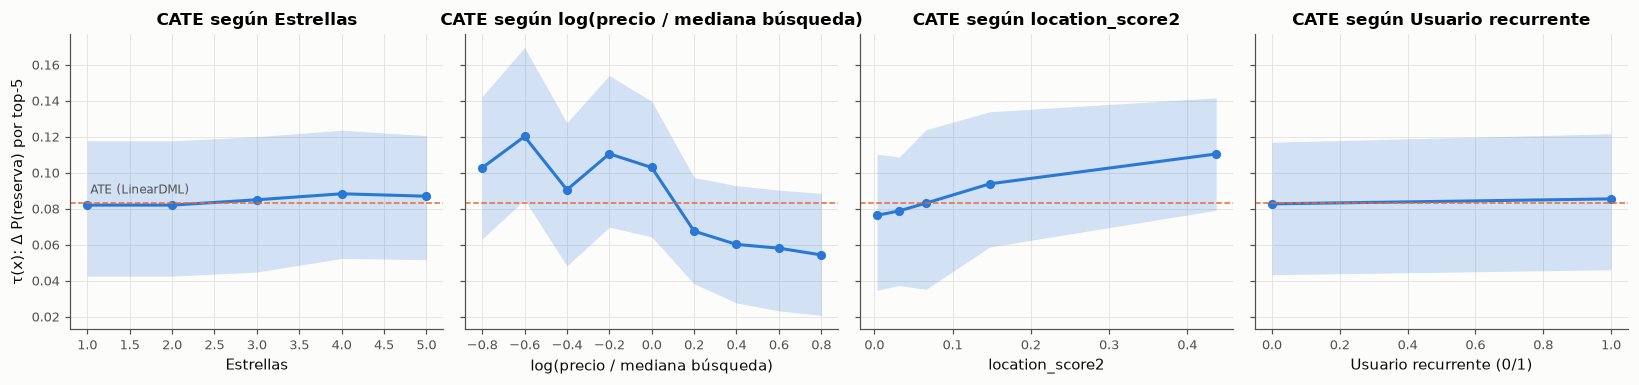

valor    CATE  IC_inf  IC_sup
variable                                              
prop_starrating      0  1.0000  0.0819  0.0425  0.1177
                     1  2.0000  0.0819  0.0425  0.1177
                     2  3.0000  0.0849  0.0447  0.1200
                     3  4.0000  0.0882  0.0523  0.1235
                     4  5.0000  0.0869  0.0517  0.1206
log_precio_rel       0 -0.8000  0.1027  0.0631  0.1423
                     1 -0.6000  0.1201  0.0849  0.1695
                     2 -0.4000  0.0905  0.0482  0.1277
                     3 -0.2000  0.1104  0.0697  0.1540
                     4  0.0000  0.1028  0.0643  0.1396
                     5  0.2000  0.0675  0.0382  0.0973
                     6  0.4000  0.0601  0.0276  0.0927
                     7  0.6000  0.0580  0.0232  0.0903
                     8  0.8000  0.0542  0.0207  0.0885
prop_location_score2 0  0.0035  0.0762  0.0347  0.1103
                     1  0.0320  0.0787  0.0373  0.1086
                     2  0.0660  0.0830  0.0351  0.1238
                     3  0.1476  0.0938  0.0587  0.1338
                     4  0.4369  0.1104  0.0791  0.1415
usuario_recurrente   0  0.0000  0.0826  0.0433  0.1169
                     1  1.0000  0.0854  0.0460  0.1216

In [70]:
t0 = time.time()
s0 = dml["R = 0"]["datos"]
cf = CausalForestDML(
    model_y=RandomForestRegressor(
        n_estimators=100, min_samples_leaf=50, max_depth=12, n_jobs=-1, random_state=SEED
    ),
    model_t=RandomForestClassifier(
        n_estimators=100, min_samples_leaf=50, max_depth=12, n_jobs=-1, random_state=SEED
    ),
    discrete_treatment=True,
    n_estimators=400,
    min_samples_leaf=100,
    cv=5,
    random_state=SEED,
    n_jobs=-1,
)
cf.fit(s0["booking_bool"], s0["top5"], X=s0[X_CATE], W=s0[W_CATE], groups=s0["srch_id"])
print(f"CausalForestDML (R = 0): {time.time() - t0:.0f} s")


def curva_cate(modelo, base: pd.DataFrame, variable: str, grilla: np.ndarray) -> pd.DataFrame:
    """CATE promedio (y su IC) moviendo `variable` en la grilla y dejando las otras X como en la muestra."""
    filas = []
    for v in grilla:
        Xv = base[X_CATE].copy()
        Xv[variable] = v
        inf_v = modelo.effect_inference(Xv.sample(min(len(Xv), 3000), random_state=SEED))
        filas.append(
            {
                "valor": v,
                "CATE": inf_v.pred.mean(),
                "IC_inf": np.percentile(inf_v.conf_int()[0], 50),
                "IC_sup": np.percentile(inf_v.conf_int()[1], 50),
            }
        )
    return pd.DataFrame(filas)


curvas = {
    "prop_starrating": curva_cate(cf, s0, "prop_starrating", np.array([1, 2, 3, 4, 5])),
    "log_precio_rel": curva_cate(cf, s0, "log_precio_rel", np.linspace(-0.8, 0.8, 9)),
    "prop_location_score2": curva_cate(
        cf,
        s0,
        "prop_location_score2",
        np.quantile(s0["prop_location_score2"], [0.05, 0.25, 0.5, 0.75, 0.95]),
    ),
    "usuario_recurrente": curva_cate(cf, s0, "usuario_recurrente", np.array([0, 1])),
}
fig, ax = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
titulos = {
    "prop_starrating": "Estrellas",
    "log_precio_rel": "log(precio / mediana búsqueda)",
    "prop_location_score2": "location_score2",
    "usuario_recurrente": "Usuario recurrente (0/1)",
}
for a, (v, c) in zip(ax, curvas.items(), strict=True):
    a.plot(c["valor"], c["CATE"], "o-", color=gr.AZUL, ms=5)
    a.fill_between(c["valor"], c["IC_inf"], c["IC_sup"], color=gr.AZUL, alpha=0.2, lw=0)
    a.axhline(dml["R = 0"]["ATE"], color=gr.NARANJA, ls="--", lw=1)
    a.set(xlabel=titulos[v], title=f"CATE según {titulos[v].split(' (')[0]}")
ax[0].set_ylabel("τ(x): Δ P(reserva) por top-5")
ax[0].annotate(
    "ATE (LinearDML)",
    xy=(1, dml["R = 0"]["ATE"]),
    xytext=(2, 6),
    textcoords="offset points",
    fontsize=8,
    color=gr.TEXTO_2,
)
fig.tight_layout()
gr.guardar(fig, "f4_cate")
plt.show()
pd.concat(curvas, names=["variable"]).round(4)

**CATE por segmento: ¿para quién rinde el slot?** Definimos los segmentos por terciles del precio
relativo y de `location_score2` dentro de cada muestra, y reportamos el efecto promedio del
segmento, $\tau_S = \mathbb{E}[\tau(X) \mid X \in S]$, con su IC 95 %. Lo estimamos con dos
modelos que se complementan:

* **LinearDML con orden aleatorio (R = 1):** no hereda el sesgo de $U$; es la magnitud causal que
  usamos para valuar (4.9).
* **Causal Forest DML con el orden del algoritmo (R = 0):** forma no paramétrica de la
  heterogeneidad, con más eventos pero con el nivel sesgado por $U$.

In [71]:
def segmentos(d: pd.DataFrame) -> dict[str, pd.Series]:
    qp = d["log_precio_rel"].quantile([1 / 3, 2 / 3]).to_numpy()
    ql = d["prop_location_score2"].quantile([1 / 3, 2 / 3]).to_numpy()
    precio = pd.cut(d["log_precio_rel"], [-np.inf, *qp, np.inf], labels=["barato", "medio", "caro"])
    ubic = pd.cut(
        d["prop_location_score2"], [-np.inf, *ql, np.inf], labels=["baja", "media", "alta"]
    )
    return {
        "barato y bien ubicado": (precio == "barato") & (ubic == "alta"),
        "barato para su búsqueda": precio == "barato",
        "bien ubicado": ubic == "alta",
        "todos": pd.Series(True, index=d.index),
        "mal ubicado": ubic == "baja",
        "caro para su búsqueda": precio == "caro",
        "caro y mal ubicado": (precio == "caro") & (ubic == "baja"),
    }


s1 = dml["R = 1"]["datos"]
m1 = dml["R = 1"]["modelo"]
filas_seg = []
seg1, seg0 = segmentos(s1), segmentos(s0)
for nombre in seg1:
    i1 = m1.ate_inference(X=s1.loc[seg1[nombre], X_CATE])
    i0 = cf.ate_inference(X=s0.loc[seg0[nombre], X_CATE])
    filas_seg.append(
        {
            "segmento": nombre,
            "τ R=1 (LinearDML)": i1.mean_point,
            "IC95_inf R=1": i1.conf_int_mean()[0],
            "IC95_sup R=1": i1.conf_int_mean()[1],
            "τ R=0 (Causal Forest)": i0.mean_point,
            "IC95_inf R=0": i0.conf_int_mean()[0],
            "IC95_sup R=0": i0.conf_int_mean()[1],
            "hoteles R=1": int(seg1[nombre].sum()),
            "hoteles R=0": int(seg0[nombre].sum()),
        }
    )
tabla_cate_seg = pd.DataFrame(filas_seg).set_index("segmento")
for r in ("R=1", "R=0"):
    col = "τ R=1 (LinearDML)" if r == "R=1" else "τ R=0 (Causal Forest)"
    tabla_cate_seg[f"relativo a todos ({r})"] = (
        tabla_cate_seg[col] / tabla_cate_seg.loc["todos", col]
    )
coefs_R1 = pd.DataFrame(
    {
        "θ (efecto de x sobre τ)": m1.coef_,
        "IC95_inf": m1.coef__interval()[0],
        "IC95_sup": m1.coef__interval()[1],
        "p": m1.coef__inference().pvalue(),
    },
    index=X_CATE,
)
print("LinearDML con orden aleatorio (R = 1): τ(x) = θ0 + xᵀθ")
print(coefs_R1.round(4).to_string())
tabla_cate_seg.round(4)

LinearDML con orden aleatorio (R = 1): τ(x) = θ0 + xᵀθ
                      θ (efecto de x sobre τ)  IC95_inf  IC95_sup       p
prop_starrating                        0.0006   -0.0012    0.0025  0.4886
log_precio_rel                        -0.0049   -0.0085   -0.0012  0.0086
prop_location_score2                   0.0124    0.0012    0.0235  0.0297
usuario_recurrente                     0.0123    0.0000    0.0246  0.0498


,τ R=1 (LinearDML),IC95_inf R=1,IC95_sup R=1,τ R=0 (Causal Forest),IC95_inf R=0,IC95_sup R=0,hoteles R=1,hoteles R=0,relativo a todos (R=1),relativo a todos (R=0)
segmento,,,,,,,,,,
barato y bien ubicado,0.0110,0.0081,0.0139,0.1192,0.0809,0.1574,14176,14407,1.4987,1.4221
barato para su búsqueda,0.0090,0.0069,0.0111,0.0996,0.0576,0.1416,48704,49959,1.2200,1.1887
bien ubicado,0.0093,0.0069,0.0117,0.0940,0.0596,0.1283,48700,49893,1.2600,1.1214
todos,0.0073,0.0059,0.0088,0.0838,0.0447,0.1228,146111,149878,1.0000,1.0000
mal ubicado,0.0062,0.0045,0.0079,0.0766,0.0368,0.1164,48730,50374,0.8390,0.9144
caro para su búsqueda,0.0056,0.0039,0.0073,0.0610,0.0269,0.0950,48702,49960,0.7583,0.7276
caro y mal ubicado,0.0042,0.0022,0.0062,0.0494,0.0161,0.0826,14621,15194,0.5663,0.5894


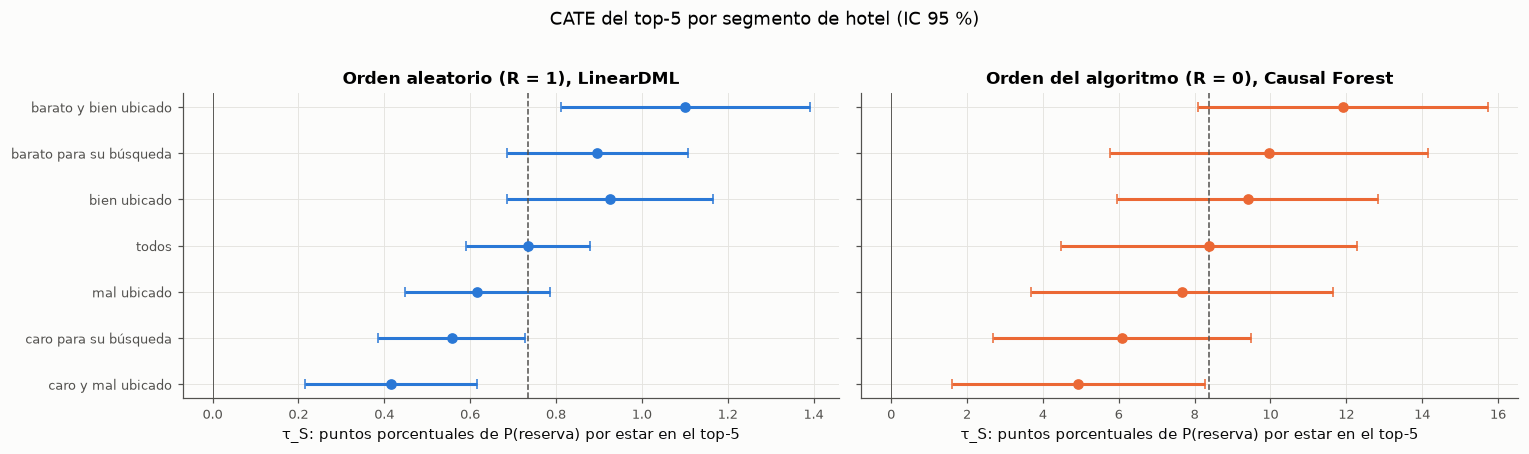

In [72]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
orden = list(tabla_cate_seg.index)
for a, (col, lo, hi, titulo, color) in zip(
    ax,
    [
        (
            "τ R=1 (LinearDML)",
            "IC95_inf R=1",
            "IC95_sup R=1",
            "Orden aleatorio (R = 1), LinearDML",
            gr.AZUL,
        ),
        (
            "τ R=0 (Causal Forest)",
            "IC95_inf R=0",
            "IC95_sup R=0",
            "Orden del algoritmo (R = 0), Causal Forest",
            gr.NARANJA,
        ),
    ],
    strict=True,
):
    t_ = tabla_cate_seg
    a.errorbar(
        100 * t_[col],
        range(len(orden)),
        xerr=[100 * (t_[col] - t_[lo]), 100 * (t_[hi] - t_[col])],
        fmt="o",
        color=color,
        capsize=3,
    )
    a.axvline(100 * t_.loc["todos", col], color=gr.TEXTO_2, ls="--", lw=1)
    a.axvline(0, color=gr.TEXTO_2, lw=0.6)
    a.set(xlabel="τ_S: puntos porcentuales de P(reserva) por estar en el top-5", title=titulo)
ax[0].set_yticks(range(len(orden)), orden)
ax[0].invert_yaxis()
ax[0].annotate(
    "promedio de la muestra",
    xy=(100 * tabla_cate_seg.loc["todos", "τ R=1 (LinearDML)"], len(orden) - 0.6),
    xytext=(8, 0),
    textcoords="offset points",
    fontsize=8,
    color=gr.TEXTO_2,
)
fig.suptitle("CATE del top-5 por segmento de hotel (IC 95 %)", y=1.02)
fig.tight_layout()
gr.guardar(fig, "f4_cate_segmentos")
plt.show()  # fmt: skip

**Lectura de los segmentos.**
- **La heterogeneidad se confirma con orden aleatorio.** Los coeficientes del LinearDML de R = 1
  tienen el mismo signo que las curvas del Causal Forest de R = 0: el efecto del slot baja con el
  precio relativo y sube con la ubicación. Lo que sugería el dato del algoritmo no es un artefacto
  de $U$.
- **Magnitud.** El orden de los segmentos es el mismo en los dos estratos: "barato y bien
  ubicado" arriba, "caro y mal ubicado" abajo. Los niveles absolutos no son comparables entre
  estratos (selección del dataset, Entrada 4); los cocientes "relativo a todos" sí lo son.
- **Incertidumbre.** Los IC de segmentos vecinos se superponen; los extremos son los que separan.
  La recomendación de asignación se apoya en los extremos y en el signo de los coeficientes, no en
  el orden fino de los segmentos intermedios.

**DML.**
- Con el orden del algoritmo, `LinearDML` estima un ATE de 0,0833 (IC 95 % [0,0789; 0,0877]),
  consistente con la regresión backdoor (0,0961) y el IPW (0,0890).
- Con orden aleatorio, 0,0073 [0,0059; 0,0088].
- Relativos a sus tasas base (0,0202 y 0,0037), los cocientes son 4,1 y 2,0: el mismo patrón que
  el logit condicional. El observacional casi duplica la amplificación relativa del benchmark.

**CATE (Causal Forest DML, orden del algoritmo).** El efecto del top-5 es heterogéneo:
- **Mayor para hoteles baratos relativos a su búsqueda:** CATE ≈ 0,09-0,12 con precio relativo
  bajo, contra ≈ 0,05-0,07 con precio relativo alto.
- **Mayor para hoteles mejor ubicados:** de 0,076 a 0,111 entre los percentiles 5 y 95 de
  `location_score2`.
- Casi plano en estrellas (0,082-0,088) y en usuario recurrente (0,083 vs. 0,085).

**Negocio:** el slot rinde más cuando muestra una oferta atractiva (buen precio relativo, buena
ubicación), no cuando muestra el hotel de mayor categoría. Las magnitudes absolutas heredan la
selección del dataset y el sesgo por U de R = 0; lo interpretable es el **orden relativo** de los
perfiles.

## 4.8 Ensayo crítico: el choque entre capacidad predictiva y palanca causal

**¿Si la posición es la variable más importante del Random Forest, puede la dirección usarla como
palanca?** En la Fase 3, `position` es la variable con mayor importancia por permutación en Test (la
PR-AUC cae 0,103 al permutarla), y la regla raíz del árbol podado es `position ≤ 4,5`. La tentación
es: "el top-5 multiplica la conversión por 6 (5,38 en OR intra-búsqueda); subamos a los hoteles que
queremos vender".

La Fase 4 muestra por qué es un error.
1. **Gran parte de esa capacidad predictiva es selección, no causa.** El algoritmo pone arriba a los
   hoteles que se iban a reservar igual (por calidad, precio, competidores y, sobre todo, por un
   desempeño histórico que no vemos). Para *predecir*, la posición es útil justamente porque resume
   todo eso. Para *intervenir*, solo cuenta el efecto que queda cuando esa selección se rompe: el
   orden aleatorio da un OR de 2,11, menos de la mitad que la asociación ingenua en log-odds.
2. **La palanca existe, pero es más chica y heterogénea.** Mover un hotel al top-5 sí aumenta sus
   reservas (efecto causal positivo, robusto a las refutaciones), sobre todo si es barato para su
   búsqueda y está bien ubicado. Subir un hotel caro y mal ubicado rinde la mitad.
3. **Cuándo una variable muy predictiva no tiene poder causal, o tiene el signo opuesto:**
   - cuando es un **proxy de confusores** (la posición resume U);
   - cuando es **consecuencia del resultado o un colisionador** (el "destacado" C, o el clic si se
     condiciona en él);
   - cuando hay **selección de la muestra** sobre el resultado (S).

   En nuestro DAG, condicionar en C hace que la exposición parezca dañina para ventas de hoteles de
   calidad. Y un modelo que "controla" por el clic concluye que la posición no importa: el
   **mismo dato da tres respuestas distintas según qué se condiciona**.
4. **Otra cara del choque:** `random_bool` es la segunda variable más importante del Random Forest
   (ΔPR-AUC 0,079). No es una palanca de negocio: refleja que el proveedor seleccionó distinto las
   búsquedas de cada estrato. Es importancia predictiva generada por el diseño muestral.

**Conclusión del ensayo:** la importancia predictiva responde "¿qué variables ayudan a adivinar Y?";
la palanca causal responde "¿qué pasa con Y si muevo X?". Solo el DAG, la identificación y, cuando
existe, un experimento, permiten pasar de una a la otra.

## 4.9 Traducción a decisiones de negocio

1. **Valuación del slot premium: un rango, no un número.** La tabla de escenarios de abajo valúa
   1.000 exposiciones en el top-5 bajo supuestos explícitos:
   - **Δp por exposición:** desde el límite inferior del IC del benchmark ajustado (conservador)
     hasta la diferencia de tasas sin ajuste con orden aleatorio (optimista).
   - **Gasto por reserva:** mediana (conservador y central) o media (optimista).
   - **Desplazamiento:** con slots de suma cero, una reserva ganada puede ser una reserva que perdió
     otro hotel de la lista. El escenario conservador supone que la mitad de las reservas
     incrementales son desplazadas: es el valor para la plataforma, no para el hotel.

   Todas las cifras valen **solo para búsquedas con al menos un clic**, la única población del
   dataset. La escala absoluta depende de esa selección: el rango es ilustrativo y sirve para
   ordenar decisiones, no para presupuestar.
2. **No pagar el sesgo.** Valuar el slot con datos del algoritmo, aun ajustados, sobreestima su
   efecto relativo en un 60 % (OR 3,38 vs. 2,11). Un contrato de posicionamiento pago calculado así
   sobreprecia el inventario.
3. **Asignación por segmento.** Con el efecto causal del benchmark (segunda tabla de abajo), el
   slot rinde más con hoteles baratos para su búsqueda y bien ubicados, y menos con hoteles caros y
   mal ubicados. Si el objetivo es maximizar reservas incrementales, se prioriza la exposición de
   los primeros: la celda siguiente cuantifica cuántas reservas y USD suma reasignar 1.000
   exposiciones del peor segmento al mejor.
4. **Experimentar en forma continua.** El orden aleatorio es la única fuente de verdad que permitió
   detectar el sesgo. Mantener una fracción chica de tráfico con orden aleatorio funciona como
   auditoría permanente del valor causal del ranking.
5. **Límites de la recomendación:**
   - Vale para búsquedas con al menos un clic.
   - Con slots de suma cero, subir a un hotel desplaza a otro (SUTVA): el efecto neto sobre la
     plataforma es menor que la suma de efectos individuales.

In [73]:
gasto_medio = dc.loc[
    (dc.booking_bool == 1) & (dc.gross_bookings_usd > 0) & (dc.precio_outlier == 0),
    "gross_bookings_usd",
]
print(
    f"Gasto por reserva (todas las reservas sin outliers): media = {gasto_medio.mean():.2f} USD, mediana = {gasto_medio.median():.2f} USD, n = {len(gasto_medio)}"
)
d1 = R1.groupby("top5")["booking_bool"].mean()
print(f"R = 1: P(reserva | top-5) = {d1[1]:.4f}, P(reserva | resto) = {d1[0]:.4f}")

Gasto por reserva (todas las reservas sin outliers): media = 383.49 USD, mediana = 223.27 USD, n = 16064
R = 1: P(reserva | top-5) = 0.0142, P(reserva | resto) = 0.0037


In [74]:
# Escenarios de valuación del slot (por 1.000 exposiciones en el top-5, búsquedas con ≥ 1 clic)
fe_bench = tabla_rel.loc[("R = 1 (aleatorio)", "ajustado por Z")]
supuestos = {
    "conservador": {"Δp por exposición": fe_bench["Δp IC95"][0], "fuente Δp": "límite inferior IC 95 %, R = 1 ajustado (efectos fijos)",
                    "gasto por reserva (USD)": gasto_medio.median(), "fuente gasto": "mediana", "desplazamiento de otra reserva": 0.5},
    "central": {"Δp por exposición": fe_bench["MPL-EF (Δp)"], "fuente Δp": "R = 1 ajustado (efectos fijos)",
                "gasto por reserva (USD)": gasto_medio.median(), "fuente gasto": "mediana", "desplazamiento de otra reserva": 0.0},
    "optimista": {"Δp por exposición": d1[1] - d1[0], "fuente Δp": "R = 1 sin ajuste (diferencia de tasas)",
                  "gasto por reserva (USD)": gasto_medio.mean(), "fuente gasto": "media", "desplazamiento de otra reserva": 0.0},
}  # fmt: skip
escenarios = pd.DataFrame(supuestos).T
escenarios["reservas incrementales / 1.000"] = (
    1000
    * escenarios["Δp por exposición"].astype(float)
    * (1 - escenarios["desplazamiento de otra reserva"].astype(float))
)
escenarios["USD incrementales / 1.000"] = escenarios["reservas incrementales / 1.000"] * escenarios[
    "gasto por reserva (USD)"
].astype(float)
escenarios

,Δp por exposición,fuente Δp,gasto por reserva (USD),fuente gasto,desplazamiento de otra reserva,reservas incrementales / 1.000,USD incrementales / 1.000
conservador,0.0055,"límite inferior IC 95 %, R = 1 ajustado (efect...",223.27,mediana,0.5,2.7500,613.9925
central,0.0064,R = 1 ajustado (efectos fijos),223.27,mediana,0.0,6.4413,1438.1600
optimista,0.0105,R = 1 sin ajuste (diferencia de tasas),383.4864,media,0.0,10.5424,4042.8593


In [75]:
# Valuación por segmento con el efecto causal del benchmark (R = 1, LinearDML): por 1.000
# exposiciones en el top-5, sin desplazamiento y con el gasto mediano por reserva
negocio_seg = pd.DataFrame(
    {
        "Δp por exposición": tabla_cate_seg["τ R=1 (LinearDML)"],
        "reservas incrementales / 1.000": 1000 * tabla_cate_seg["τ R=1 (LinearDML)"],
        "IC95_inf reservas": 1000 * tabla_cate_seg["IC95_inf R=1"],
        "IC95_sup reservas": 1000 * tabla_cate_seg["IC95_sup R=1"],
    }
)
negocio_seg["USD incrementales / 1.000"] = (
    negocio_seg["reservas incrementales / 1.000"] * gasto_medio.median()
)
negocio_seg["relativo a todos"] = tabla_cate_seg["relativo a todos (R=1)"]
mejor_seg, peor_seg = "barato y bien ubicado", "caro y mal ubicado"
ganancia_reasignar = (
    negocio_seg.loc[mejor_seg, "reservas incrementales / 1.000"]
    - negocio_seg.loc[peor_seg, "reservas incrementales / 1.000"]
)
print(
    f"Reasignar 1.000 exposiciones de '{peor_seg}' a '{mejor_seg}': "
    f"{ganancia_reasignar:+.2f} reservas incrementales "
    f"({ganancia_reasignar * gasto_medio.median():+,.0f} USD con el gasto mediano)"
)
negocio_seg.round(3)

Reasignar 1.000 exposiciones de 'caro y mal ubicado' a 'barato y bien ubicado': +6.85 reservas incrementales (+1,530 USD con el gasto mediano)


,Δp por exposición,reservas incrementales / 1.000,IC95_inf reservas,IC95_sup reservas,USD incrementales / 1.000,relativo a todos
segmento,,,,,,
barato y bien ubicado,0.011,11.011,8.114,13.907,2458.406,1.499
barato para su búsqueda,0.009,8.963,6.860,11.066,2001.108,1.220
bien ubicado,0.009,9.257,6.859,11.654,2066.723,1.260
todos,0.007,7.347,5.907,8.786,1640.305,1.000
mal ubicado,0.006,6.164,4.475,7.852,1376.161,0.839
caro para su búsqueda,0.006,5.571,3.856,7.286,1243.859,0.758
caro y mal ubicado,0.004,4.160,2.159,6.162,928.843,0.566


## 4.10 Síntesis de la Fase 4

| Pregunta | Respuesta | Evidencia |
|---|---|---|
| ¿El top-5 causa reservas? | Sí: OR intra-búsqueda 2,11 [1,90; 2,35] con orden aleatorio | 4.3, benchmark |
| ¿Cuánto sesgo tiene el observacional? | Ingenuo 5,38; ajustado 3,38: sobreestima ≈ 60 % aun ajustado, también en diferencia de riesgos y con muestras re-ponderadas | 4.3 y 4.3 bis: los datos son incompatibles con que el ajuste por lo observable elimine el sesgo |
| ¿Cómo opera el efecto? | El clic es paso obligatorio del embudo; con orden aleatorio, la mayor parte del efecto es más clics | 4.4 |
| ¿Qué pasa si se condiciona en colisionadores? | La diferencia absoluta se infla (S); aparece Berkson (C) | 4.5 y simulaciones con verdad conocida |
| ¿Es robusta la estimación? | Estable en las 3 refutaciones; sensible a un U moderado | 4.6 |
| ¿Para quién rinde más? | Hoteles baratos para su búsqueda y bien ubicados | 4.7, CATE |
| ¿La variable más predictiva es una palanca? | Solo en parte: buena parte de su poder predictivo es selección | 4.8 |

---
# Fase 5 — Artefactos para la aplicación desplegada

La app (`app/app.py`) **no ve los datos**: lee solo los artefactos que genera esta sección en
`models/`. Reglas de confidencialidad (`tpi.artefactos`; decisión de Verónica del 12/11 de
publicar solo agregados):

* Conteos con supresión de celdas con menos de 10 filas; sin identificadores ni fechas.
* El modelo de la app es un **Random Forest compacto** (100 árboles, profundidad ≤ 12, hojas de
  ≥ 100 filas): cada predicción promedia al menos 100 observaciones de entrenamiento. Su
  desempeño en Test se compara con el del Random Forest completo.
* La heterogeneidad causal se exporta como una grilla de CATE precalculada (la app no corre
  EconML).

In [76]:
import json

import joblib

from tpi.artefactos import K_MIN, MIN_HOJA, claves_prohibidas, grilla_2d, guardar_json, histograma
from tpi.config import MODELS_DIR

t0 = time.time()
rf_app = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=MIN_HOJA,
    max_features=0.3,
    random_state=SEED,
    n_jobs=-1,
).fit(X_tr, y_tr)
p_app = rf_app.predict_proba(X_te)[:, 1]
ruta_modelo = MODELS_DIR / "rf_app.joblib"
MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(rf_app, ruta_modelo, compress=3)
print(
    f"RF de la app: PR-AUC Test = {average_precision_score(y_te, p_app):.4f} (RF completo: {tabla_test.loc['Random Forest', 'PR_AUC']:.4f}), "
    f"ROC-AUC = {roc_auc_score(y_te, p_app):.4f}, Brier = {brier_score_loss(y_te, p_app):.5f} | "
    f"{ruta_modelo.stat().st_size / 1e6:.1f} MB | {time.time() - t0:.0f} s"
)

RF de la app: PR-AUC Test = 0.1523 (RF completo: 0.1534), ROC-AUC = 0.8542, Brier = 0.01960 | 5.5 MB | 7 s


In [77]:
VARS_APP = {
    "prop_starrating": ("Estrellas", np.arange(0.5, 6, 1)),
    "prop_review_score": ("Puntaje de reseñas", np.arange(0.75, 5.5, 0.5)),
    "log_precio_rel": ("log(precio / mediana de la búsqueda)", np.linspace(-1.2, 1.2, 25)),
    "log_precio": ("log(precio por noche, USD)", np.linspace(2, 7.6, 29)),
    "prop_location_score2": ("Puntaje de ubicación 2", np.linspace(0, 1, 21)),
    "srch_booking_window": ("Anticipación de la búsqueda (días)", np.arange(0, 370, 15)),
    "srch_length_of_stay": ("Noches", np.arange(0.5, 15, 1)),
}
art = {
    "meta": {
        "fuente": "Kaggle, Personalize Expedia Hotel Searches - ICDM 2013 (muestra de 30.000 búsquedas)",
        "filas": len(df),
        "busquedas": int(df.srch_id.nunique()),
        "prevalencia_reserva": float(df.booking_bool.mean()),
        "k_min_supresion": K_MIN,
        "min_filas_por_hoja": MIN_HOJA,
        "semilla": SEED,
    },
    "variables": {},
    "ctr_posicion": {},
    "tasa_reserva_por_estrellas": {},
}
for v, (etq, bordes) in VARS_APP.items():
    art["variables"][v] = {
        "etiqueta": etq,
        **{
            f"R{r}": {
                f"reserva_{b}": histograma(
                    df.loc[(df.random_bool == r) & (df.booking_bool == b), v], bordes
                )
                for b in (0, 1)
            }
            for r in (0, 1)
        },
    }
for r in (0, 1):
    c = (
        df[(df.random_bool == r) & (df.position <= 38)]
        .groupby("position")
        .agg(
            n=("click_bool", "size"), clics=("click_bool", "sum"), reservas=("booking_bool", "sum")
        )
    )
    c = c[c.n >= K_MIN]
    art["ctr_posicion"][f"R{r}"] = {
        "posicion": c.index.tolist(),
        "n": c.n.tolist(),
        "ctr": (c.clics / c.n).tolist(),
        "tasa_reserva": (c.reservas / c.n).tolist(),
    }
    e = (
        df[df.random_bool == r]
        .groupby("prop_starrating")
        .agg(n=("booking_bool", "size"), reservas=("booking_bool", "sum"))
    )
    e = e[e.n >= K_MIN]
    art["tasa_reserva_por_estrellas"][f"R{r}"] = {
        "estrellas": e.index.tolist(),
        "n": e.n.tolist(),
        "tasa": (e.reservas / e.n).tolist(),
    }

esc, pca_ = pca_pipe.named_steps["escala"], pca_pipe.named_steps["pca"]
Zt = pca_pipe.transform(te[X_PCA].astype(float))
bx, by = np.linspace(-6, 8, 57), np.linspace(-5, 7, 49)
art["pca"] = {
    "variables": X_PCA,
    "media": esc.mean_,
    "desvio": esc.scale_,
    "componentes": pca_.components_[:4],
    "autovalores": pca_.explained_variance_,
    "pct_var": 100 * pca_.explained_variance_ratio_,
    "grilla_test": {
        f"reserva_{b}": grilla_2d(
            Zt[te.booking_bool.to_numpy() == b, 0], Zt[te.booking_bool.to_numpy() == b, 1], bx, by
        )
        for b in (0, 1)
    },
}
art["modelo"] = {
    "archivo": "rf_app.joblib",
    "features": FEATURES,
    "medianas_train": X_tr.median().to_dict(),
    "p01": X_tr.quantile(0.01).to_dict(),
    "p99": X_tr.quantile(0.99).to_dict(),
    "metricas_test_app": metricas(
        y_te,
        p_app,
        umbral_f1(
            y_sub,
            cross_val_predict(
                clone(rf_app), X_sub, y_sub, groups=g_sub, cv=CV, method="predict_proba", n_jobs=-1
            )[:, 1],
        ),
    ),
    "metricas_test_torneo": tabla_test.drop(columns=["seg. entrenamiento"]).to_dict(orient="index"),
    "importancia_permutacion": imp["Permutación (ΔPR-AUC)"].sort_values(ascending=False).to_dict(),
    "calibracion_app": dict(
        zip(
            ["frec_obs", "prob_media"],
            calibration_curve(y_te, p_app, n_bins=10, strategy="quantile"),
            strict=True,
        )
    ),
}

In [78]:
grilla_cate = []
base_x = s0[X_CATE].median()
for est_ in [1, 2, 3, 4, 5]:
    for pr in [-0.6, -0.3, 0.0, 0.3, 0.6]:
        for rec_ in [0, 1]:
            x = pd.DataFrame(
                [
                    {
                        **base_x.to_dict(),
                        "prop_starrating": est_,
                        "log_precio_rel": pr,
                        "usuario_recurrente": rec_,
                    }
                ]
            )[X_CATE]
            inf_x = cf.effect_inference(x)
            lo, hi = inf_x.conf_int()
            grilla_cate.append(
                {
                    "estrellas": est_,
                    "log_precio_rel": pr,
                    "usuario_recurrente": rec_,
                    "cate": float(inf_x.pred[0]),
                    "ic_inf": float(lo[0]),
                    "ic_sup": float(hi[0]),
                }
            )
art["causal"] = {
    "dag_dot": a_dot(g_alg),
    "dag_dot_aleatorio": a_dot(g_rand),
    "ate_dowhy": tabla_ate.reset_index(names="estrato").to_dict(orient="records"),
    "or_intra": [
        {"estrato": e, "ajuste": a, **fila}
        for (e, a), fila in tabla_rel.to_dict(orient="index").items()
    ],
    "or_benchmark": or_bench,
    "or_observacional_ajustado": or_adj0,
    "or_ingenuo": or_ing0,
    "dml": {
        k: {"ATE": v["ATE"], "IC95": v["IC95"], "tasa_base": v["tasa base"]} for k, v in dml.items()
    },
    "cate_grilla": grilla_cate,
    "cate_curvas": {k: c.to_dict(orient="list") for k, c in curvas.items()},
    "refutaciones": tabla_refut.reset_index(names="prueba").to_dict(orient="records"),
    "sensibilidad_u": tabla_u.to_dict(orient="records"),
    "mediador": tabla_med.reset_index(names="especificacion").to_dict(orient="records"),
    "robustez": {
        "cociente_or": float(tabla_rob.iloc[0]["cociente OR"]),
        "ic_boot_or": [
            float(ic_boot.loc["cociente_OR", "IC95_inf"]),
            float(ic_boot.loc["cociente_OR", "IC95_sup"]),
        ],
        "cociente_ame": float(tabla_rob.iloc[0]["cociente AME"]),
        "ic_boot_ame": [
            float(ic_boot.loc["cociente_AME", "IC95_inf"]),
            float(ic_boot.loc["cociente_AME", "IC95_sup"]),
        ],
        "p_wald": float(tabla_rob.iloc[0]["p (Wald)"]),
        "cociente_or_ponderado": float(tabla_rob.iloc[1]["cociente OR"]),
    },
    "escenarios": escenarios.reset_index(names="escenario").to_dict(orient="records"),
}
ruta_art = guardar_json(art, MODELS_DIR / "artefactos_app.json")
prohibidas = claves_prohibidas(json.loads(ruta_art.read_text("utf-8")))
assert not prohibidas, prohibidas
print(
    f"{ruta_art.name}: {ruta_art.stat().st_size / 1e3:.0f} kB | identificadores encontrados: {len(prohibidas)}"
)

artefactos_app.json: 114 kB | identificadores encontrados: 0


**Resultados para el informe y las diapositivas.** Todos los números que citan el informe Quarto y
las diapositivas se leen de este archivo (`models/resultados.json`), que solo contiene estadísticos
agregados. Así ningún número se copia a mano.

In [79]:
from dataclasses import asdict

from tpi.inferencia import Contraste


def _c(x: Contraste) -> dict:
    return {k: v for k, v in asdict(x).items() if k != "extra"} | {
        "extra": x.extra,
        "texto": x.texto(),
    }


resultados = {
    "fase0": {
        "filas_train_csv": 9_917_530,
        "busquedas_train_csv": 399_344,
        "muestra_filas": len(crudo),
        "muestra_busquedas": int(crudo.srch_id.nunique()),
    },
    "fase1": {
        "contraste1": _c(c1)
        | {
            "ctr_top5": float(por_busq[True].mean()),
            "ctr_resto": float(por_busq[False].mean()),
            "mde_dz": efecto_minimo_detectable(len(D)),
        },
        "contraste2": _c(c2)
        | {
            "cociente_geom": float(np.exp(c2.diferencia)),
            "ic_cociente": [float(np.exp(c2.ic95[0])), float(np.exp(c2.ic95[1]))],
            "mde_g": efecto_minimo_detectable(*c2.n),
            "n_rec": c2.n[0],
            "n_nue": c2.n[1],
        },
        "contraste2_mw": _c(c2b),
        "anova": {k: _c(v) for k, v in an.items()} | {"omega2": an["clasico"].extra["omega2"]},
        "posthoc_cociente_5_vs_12": float(
            1 / ph.loc[(ph.A == "1-2") & (ph.B == "5"), "cociente_precios"].iloc[0]
        ),
        "centinelas": tabla_centinelas.to_dict(orient="index"),
        "escala_precio_pct": tabla_escala["pct"].to_dict(),
        "outliers_precio": {
            "filas": int(df.precio_outlier.sum()),
            "pct": float(100 * df.precio_outlier.mean()),
            "cerca_inf": lo_abs,
            "cerca_sup": hi_abs,
        },
        "faltantes_pct": faltantes["pct_faltante"].to_dict(),
        "little": little | {"variables": COLS_LITTLE},
        "mcar_max_efecto": resumen_mcar["max_|efecto|"].to_dict(),
        "zc": tabla_zc.to_dict(orient="index"),
        "slots_especiales": SLOTS_ESPECIALES,
    },
    "fase2": {
        "ingenuo": {
            "r2": ingenuo.rsquared,
            "curtosis": dg_ing.curtosis,
            "cook_max": float(inf_ing.cook.max()),
        },
        "mco": {
            "n": int(mco.nobs),
            "r2": mco.rsquared,
            "r2_aj": mco.rsquared_adj,
            "F": mco.fvalue,
            "gl": [int(mco.df_model), int(mco.df_resid)],
            "coef": mco.params.to_dict(),
            "p_hc3": mco_hc3.pvalues.to_dict(),
        },
        "gauss_markov": asdict(dg),
        "influencia": {
            "outlier_y": int(inf.outlier_y.sum()),
            "alto_leverage": int(inf.alto_leverage.sum()),
            "influyente_4n": int(inf.influyente_4n.sum()),
            "influyente_05": int(inf.influyente_05.sum()),
            "cook_max": float(inf.cook.max()),
        },
        "vif_max_modelo": float(vif["VIF modelo 2.1"].max()),
        "vif_max_ampliado": float(vif["VIF conjunto ampliado (Fase 3)"].max()),
        "pca": {
            "autovalores": var_pca["autovalor"].tolist(),
            "pct_acum": var_pca["pct_acum"].tolist(),
            "n_kaiser": n_kaiser,
        },
    },
    "fase3": {
        "test": tabla_test.drop(columns=["seg. entrenamiento"]).to_dict(orient="index"),
        "mejor": mejor,
        "rf_params": busqueda_rf.best_params_,
        "logit_params": grid_log.best_params_,
        "logit_or": tabla_or.sort_values("p").head(12).to_dict(orient="index"),
        "arbol_libre": {
            "hojas": int(arbol_libre.get_n_leaves()),
            "pr_auc_train": float(average_precision_score(y_tr, p_libre_tr)),
            "pr_auc_test": float(average_precision_score(y_te, p_libre_te)),
        },
        "arbol_podado": {
            "alfa": float(alfa_opt),
            "hojas": int(arbol.get_n_leaves()),
            "profundidad": int(arbol.get_depth()),
        },
        "oob_pr_auc": float(average_precision_score(y_tr[ok], p_oob[ok])),
        "cronologico": {
            "pr_auc": float(average_precision_score(futuro[OBJETIVO], p_fut)),
            "roc_auc": float(roc_auc_score(futuro[OBJETIVO], p_fut)),
        },
        "importancia": imp[["MDI", "Permutación (ΔPR-AUC)"]].to_dict(orient="index"),
        "rho_cardinalidad_mdi": float(rho_card.statistic),
        "ranking_top5": pd.DataFrame(filas_rank).set_index("estrato").to_dict(orient="index"),
        "pca_features_pr_auc": float(average_precision_score(y_te, p_pca)),
    },
    "fase4": {
        "ate_dowhy": tabla_ate.to_dict(orient="index"),
        "or_intra": {
            f"{e} | {a}": fila for (e, a), fila in tabla_rel.to_dict(orient="index").items()
        },
        "or_ingenuo_R0": or_ing0,
        "or_ajustado_R0": or_adj0,
        "or_benchmark": or_bench,
        "brecha_logor": float(brecha),
        "pct_explicado_Z": float(100 * np.log(or_ing0 / or_adj0) / brecha),
        "sens_top4": {"or": sens_t.estimacion, "ic": list(sens_t.ic95)},
        "mediador": tabla_med.to_dict(orient="index"),
        "seleccion_sim": tabla_s.to_dict(orient="index"),
        "colisionador_C": tabla_c.to_dict(orient="index"),
        "refutaciones": tabla_refut.to_dict(orient="index"),
        "sens_u": tabla_u.to_dict(orient="records"),
        "dml": {
            k: {"ATE": v["ATE"], "IC95": v["IC95"], "tasa_base": v["tasa base"]}
            for k, v in dml.items()
        },
        "gasto_medio": float(gasto_medio.mean()),
        "gasto_mediana": float(gasto_medio.median()),
        "p_top5_R1": float(d1[1]),
        "p_resto_R1": float(d1[0]),
        "robustez": {
            "tabla": tabla_rob.to_dict(orient="index"),
            "bootstrap": ic_boot.to_dict(orient="index"),
            "B": len(boot),
            "smd_max_sin_ponderar": float(balance["SMD sin ponderar"].abs().max()),
            "smd_max_ponderado": float(balance["SMD ponderado"].abs().max()),
            "ess": float(ess),
            "n_R0": len(s0b),
            "n_R1": len(s1b),
            "fe_inf_R0": fe_i0.estimacion,
            "fe_inf_R1": fe_i1.estimacion,
        },
        "embudo": tabla_emb.to_dict(orient="index"),
        "escenarios": escenarios.to_dict(orient="index"),
        "overlap": tabla_overlap.to_dict(orient="index"),
        "ipw": {f"{e} | {v}": fila for (e, v), fila in tabla_ipw.to_dict(orient="index").items()},
        "cate_segmentos": tabla_cate_seg.to_dict(orient="index"),
        "het_R1": coefs_R1.to_dict(orient="index"),
        "negocio_segmentos": negocio_seg.to_dict(orient="index"),
        "reasignacion": {
            "desde": peor_seg,
            "hacia": mejor_seg,
            "reservas_por_1000": float(ganancia_reasignar),
            "usd_por_1000": float(ganancia_reasignar * gasto_medio.median()),
        },
    },
}
ruta_res = guardar_json(resultados, MODELS_DIR / "resultados.json")
assert not claves_prohibidas(json.loads(ruta_res.read_text("utf-8")))
print(f"{ruta_res.name}: {ruta_res.stat().st_size / 1e3:.0f} kB")

resultados.json: 41 kB
